In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

### Objetivo

Implementar un agente de RL que aprenda a invertir en un entorno simulado con un único activo.

### Definición del entorno

El **estado** (observación) es una tupla de la forma ``(tendencia, posición)`` en la que:

- ``tendencia`` es la tendencia del precio, calculada a partir de las últimas 6 observaciones.

- ``posición`` es $1$ si el agente posee el activo y $0$ si no lo posee.

En cada momento, las **acciones** son:

- $0$ = vender

- $1$ = mantener

- $2$ = comprar

Obviamente, la acción *vender* sólo tendrá efecto si el agente es poseedor del activo, y la acción *comprar* sólo tendrá efecto cuando el agente no posee el activo.


In [2]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info

### Funciones para generar precios

Se proponen cuatro funciones generadoras de precios. Las pruebas deben hacerse al menos con estas cuatro funciones. Si se desea, pueden añadirse otras funciones de diferentes características, o incluso probar con alguna serie de precios real.

#### 1. Tendencia suave + componente cíclica

In [3]:
def generar_precios(n_steps=1000):
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = np.random.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios

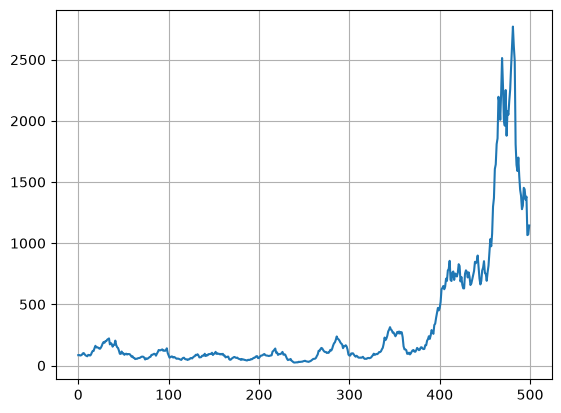

In [4]:
precios = generar_precios(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 2. Movimiento browniano

In [5]:
def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02):
    """
    Genera precios usando Movimiento Browniano Geométrico.
    - mu: Tendencia o deriva esperada (drift).
    - sigma: Volatilidad (desviación estándar de los retornos).
    """
    dt = 1.0
    # Retornos logarítmicos distribuidos normalmente
    retornos = np.random.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), n_steps)
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios

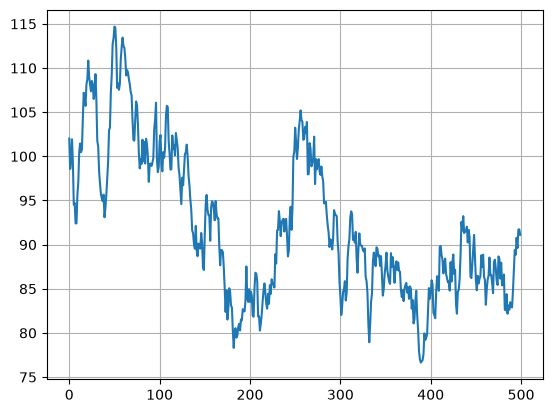

In [6]:
precios = generar_precios_browniano(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 3. Reversión a la media

In [7]:
def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02):
    """
    Genera precios que tienden a revertir hacia un valor medio.
    - mean_price: El precio objetivo o de equilibrio.
    - kappa: Velocidad de reversión (cuánto más alto, más rápido vuelve al valor medio).
    - volatility: Magnitud del ruido aleatorio añadido en cada paso.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    for t in range(1, n_steps):
        # Fuerza de atracción hacia la media + ruido aleatorio
        delta = kappa * (mean_price - precios[t-1]) + np.random.normal(0, volatility * mean_price)
        precios[t] = precios[t-1] + delta

        # Evitar precios negativos o cero por seguridad
        precios[t] = max(precios[t], 0.1)

    return precios

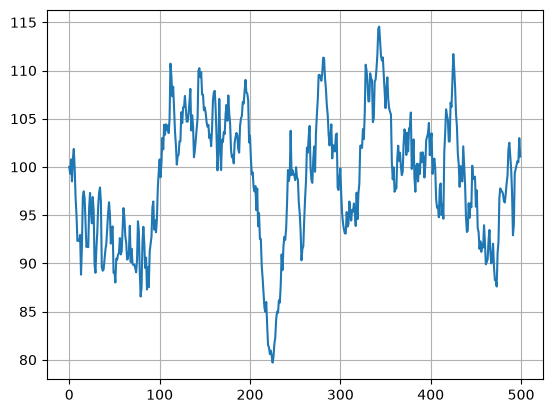

In [8]:
precios = generar_precios_reversion_media(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 4. Alternancia entre regímenes alcistas y bajistas

In [9]:
def generar_precios_regimenes(n_steps=1000, start_price=100.0):
    """
    Genera precios alternando entre regímenes alcistas y bajistas de forma estocástica.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    # Estado inicial: 0 = Alcista, 1 = Bajista
    estado = 0

    retornos = []
    for _ in range(n_steps):
        # Probabilidad de cambiar de régimen en cada paso
        if np.random.rand() < 0.02:
            estado = 1 - estado

        if estado == 0:  # Régimen alcista
            ret = np.random.normal(0.001, 0.01)
        else:            # Régimen bajista (caídas con más ruido)
            ret = np.random.normal(-0.0015, 0.025)

        retornos.append(ret)

    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)

    # Asegurar que no haya valores negativos
    precios = np.maximum(precios, 0.1)
    return precios

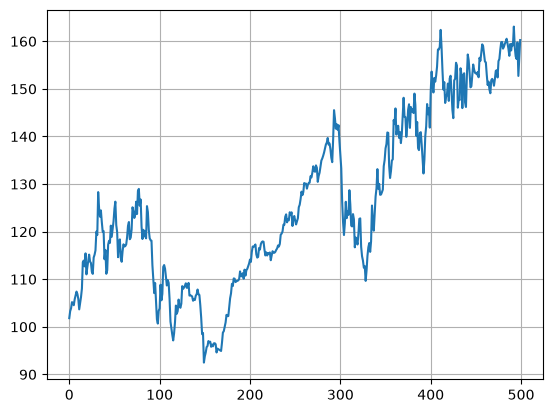

In [10]:
precios = generar_precios_regimenes(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

### Agente aleatorio

Como línea base, se proporciona un agente aleatorio que en cada instante selecciona la acción al azar. A continuación se compara su rendimiento en un episodio con la estrategia *buy & hold*.

In [11]:
n_steps = 500
prices = generar_precios(n_steps)
env = SimpleTradingEnv(prices)

obs, info = env.reset()
terminated = False
step_count = 0

balances = [env.balance]
actions_taken = []
positions = []

while not terminated:
    action = env.action_space.sample()
    positions.append(env.position)
    actions_taken.append(action)

    obs, reward, terminated, truncated, info = env.step(action)
    balances.append(env.balance)

positions = np.array(positions)
actions_taken = np.array(actions_taken)
valid_prices = prices[5:-1]

In [12]:
prices_on = valid_prices.copy()
prices_on[positions==0] = np.nan
prices_off = valid_prices.copy()
prices_off[positions==1] = np.nan

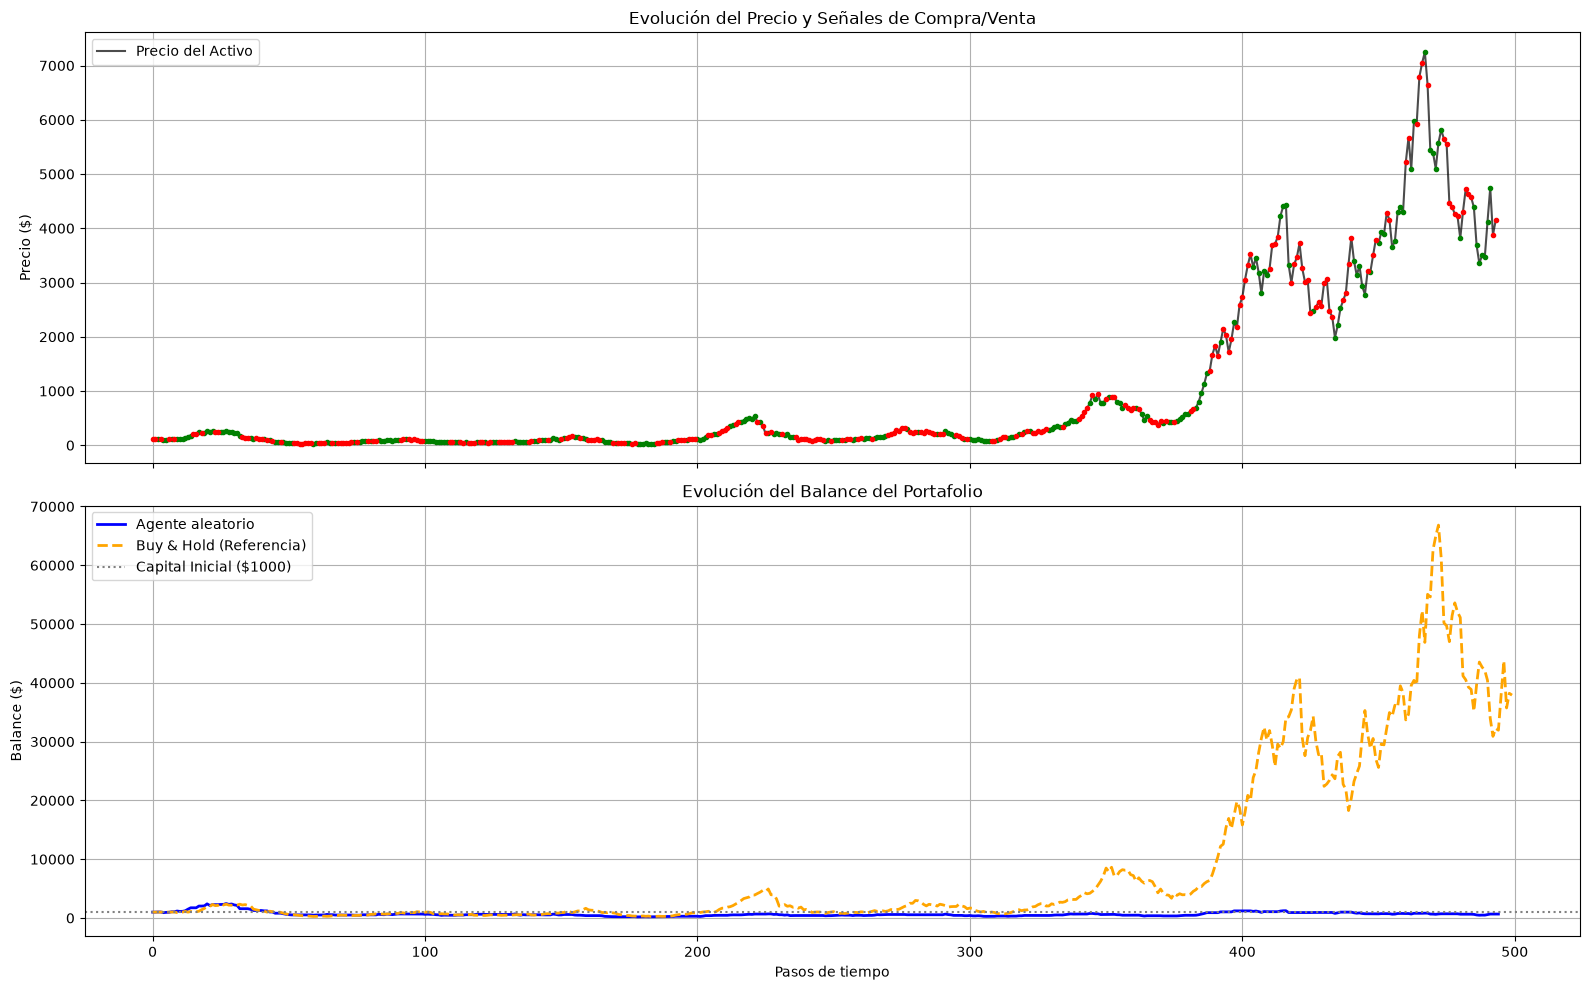

In [13]:
# --- Estrategia Buy & Hold para el panel de balance ---
bh_initial_cash = 1000.0
bh_start_price = prices[5]
bh_shares = (bh_initial_cash * 0.999) / bh_start_price
bh_balances = [bh_initial_cash if i < 5 else bh_shares * p for i, p in enumerate(prices)]

# --- Crear la figura con 2 Subgráficas ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PANEL 1: Evolución del precio y señales de Trading
ax1.plot(valid_prices, label="Precio del Activo", color="black", alpha=0.7, linewidth=1.5)
ax1.plot(prices_on, 'g.')
ax1.plot(prices_off, 'r.')
ax1.set_title("Evolución del Precio y Señales de Compra/Venta")
ax1.set_ylabel("Precio ($)")
ax1.legend(loc="upper left")
ax1.grid(True)

# PANEL 2: Evolución del Balance (Portafolio)
ax2.plot(balances, label="Agente aleatorio", color="blue", linewidth=2)
ax2.plot(bh_balances, label="Buy & Hold (Referencia)", color="orange", linestyle="--", linewidth=2)
ax2.axhline(y=1000, color="gray", linestyle=":", label="Capital Inicial ($1000)")

ax2.set_title("Evolución del Balance del Portafolio")
ax2.set_xlabel("Pasos de tiempo")
ax2.set_ylabel("Balance ($)")
ax2.legend(loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()

### Ejercicios y notas sobre la implementación

1. Implementar los algoritmos vistos en clase y probarlos con distintas funciones de generación de los precios. Deben implementarse al menos los algoritmos *DQN* y *A3C*, usando al menos las cuatro funciones de generación de precio propuestas.

   - Cada agente debe entrenarse con varios (muchos) episodios, y cada episodio debería usar una serie de precios distinta, aunque todas deberían ser generadas por la misma función. De este modo el agente puede aprender las regularidades de cada tipo de *mercado* sin repetir siempre los mismos datos para entrenar.

   - Para evaluar los agentes entrenados, se deberían usar datos de *test*, series de precios nuevas generadas a partir de la misma función usada durante el entrenamiento. Los resultados deberían promediarse sobre varias series de test.

2. Analizar las soluciones obtenidas para cada función de generación de precios, y compararlas con el agente aleatorio y con la estrategia *buy & hold*. Razonar si la estrategia encontrada en cada caso es la esperada.

3. Ajustar de manera adecuada los hiperparámetros de cada modelo, en particular el factor de aprendizaje $\alpha$, la tasa de exploración $\epsilon$ (probablemente con decaimiento temporal), el factor de descuento $\gamma$, y el número de episodios de entrenamiento.

4. Comparar en una tabla las soluciones obtenidas con cada algoritmo, incluyendo los *baselines*, sobre cada problema (función generadora de precios). Analizar al menos el rendimiento y el tiempo de convergencia.



### Entrega

Debe entregarse un documento en pdf de un **máximo de dos páginas** con un resumen de las pruebas realizadas, los resultados obtenidos y las conclusiones extraidas.

Las entregas se harán por grupos. Cada grupo de TFM realizará una entrega.

La fecha tope para la entrega es el **5/11/2026**, a las **23:59**.

**Importante:** Una primera versión del documento se deberá entregar por e-mail a manuel.smontanes@gmail.com antes de la clase del jueves 5 de noviembre. En dicha clase cada grupo presentará su trabajo y lo discutirá con el profesor durante un máximo de 15 minutos. Los comentarios recibidos pueden usarse para mejorar el documento para la entrega final.

De cara a organizar las presentaciones, un representante de cada grupo debe enviar un e-mail al profesor antes del martes 3 de noviembre. Ese mismo día os indicaré, mediante mensaje a los representantes, el orden de presentación.

### Evaluación

La realización de los ejercicios y pruebas propuestos garantiza el aprobado en la práctica (50%). El otro 50% se obtendrá valorando la realización de pruebas que vayan más allá de los mínimos planteados (10%), la calidad de presentación de los resultados (20%), la justificación de las decisiones de diseño tomadas (10%) y el análisis crítico de las soluciones obtenidas (10%).

## Solución

Dos algoritmos de aprendizaje por refuerzo profundo sobre el entorno y los generadores de la plantilla, sin modificarlos:

- **DQN**: una red neuronal sustituye a la tabla $Q(s, a)$; aprende de una memoria de transiciones y calcula los objetivos con una red objetivo que se actualiza con retraso.
- **A3C**: una red con dos salidas, la política $\pi(a \mid s)$ (actor) y el valor $V(s)$ (crítico), entrenada por varios trabajadores en paralelo que actualizan de forma asíncrona unos pesos compartidos.

Se comparan con el agente aleatorio, *buy & hold* y el Q-Learning tabular de la parte 1, sobre las mismas series de test.

### Fase 0: Preparación

#### Código compartido en módulos

- `entorno.py`: copia literal del entorno y los generadores de la plantilla.
- `protocolo.py`: protocolo de la parte 1 (series, episodios, baselines y métricas) y normalización de la tendencia.

Los procesos paralelos (Optuna, A3C) se crean con *spawn* en macOS y Windows y solo pueden usar código importable desde un módulo. Se comprueba que la copia reproduce exactamente las series y los episodios de la plantilla.

In [14]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium
import torch

import entorno
from protocolo import (GENERADORES, N_STEPS, SEMILLA_VAL, SEMILLA_TEST, SEMILLA_DISC, N_VAL, N_TEST, N_DISC,
                       generar_serie, generar_conjunto, evaluar, politica_aleatoria, politica_buy_and_hold,
                       tendencias_serie, parametros_normalizacion, normalizar_obs)

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"gymnasium {gymnasium.__version__} | torch {torch.__version__}")

Python 3.12.10 | numpy 2.5.4 | pandas 3.1.0 | gymnasium 1.4.0 | torch 2.15.0


In [15]:
# 1) Mismas series: generadores de entorno.py frente a los de la plantilla, con las mismas semillas
PARES_GENERADORES = {
    "ciclo": (generar_precios, entorno.generar_precios),
    "browniano": (generar_precios_browniano, entorno.generar_precios_browniano),
    "reversion": (generar_precios_reversion_media, entorno.generar_precios_reversion_media),
    "regimenes": (generar_precios_regimenes, entorno.generar_precios_regimenes),
}
for nombre, (gen_plantilla, gen_modulo) in PARES_GENERADORES.items():
    for semilla in range(20):
        np.random.seed(semilla)
        a = gen_plantilla(n_steps=N_STEPS)
        np.random.seed(semilla)
        b = gen_modulo(n_steps=N_STEPS)
        assert np.array_equal(a, b), nombre


# 2) Mismos episodios: el agente aleatorio, con la misma semilla, recorre los dos entornos
#    y se comparan observación, recompensa y balance en cada paso
def trayectoria_aleatoria(clase_entorno, prices, semilla):
    env = clase_entorno(prices)
    obs, info = env.reset()
    env.action_space.seed(semilla)
    pasos = [(*obs, 0.0, env.balance)]
    terminated = False
    while not terminated:
        obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
        pasos.append((*obs, reward, env.balance))
    return np.array(pasos)


for nombre in GENERADORES:
    for semilla in range(20):
        prices = generar_serie(nombre, SEMILLA_DISC + semilla)
        assert np.array_equal(trayectoria_aleatoria(SimpleTradingEnv, prices, semilla),
                              trayectoria_aleatoria(entorno.SimpleTradingEnv, prices, semilla)), nombre

print("entorno.py reproduce exactamente las series y los episodios de la plantilla")

entorno.py reproduce exactamente las series y los episodios de la plantilla


#### Protocolo experimental

El de la parte 1, con las mismas semillas: las series de validación y test son exactamente las mismas, así que DQN y A3C se comparan con Q-Learning y Sarsa sobre los mismos datos.

| Conjunto | Series por generador | Semillas | Uso |
|---|---|---|---|
| Entrenamiento | una nueva en cada episodio | desde 0 (otro bloque en cada repetición) | aprendizaje |
| Validación | 50 (fijas) | desde 10 000 | curvas de aprendizaje y ajuste |
| Test | 200 (fijas) | desde 20 000 | evaluación final, una sola vez |
| Discretización | 100 (fijas) | desde 30 000 | parámetros de normalización |

In [16]:
SERIES_VAL = {g: generar_conjunto(g, SEMILLA_VAL, N_VAL) for g in GENERADORES}
SERIES_TEST = {g: generar_conjunto(g, SEMILLA_TEST, N_TEST) for g in GENERADORES}
SERIES_DISC = {g: generar_conjunto(g, SEMILLA_DISC, N_DISC) for g in GENERADORES}

#### Comprobación con la parte 1

Con las mismas series, los baselines en validación deben coincidir exactamente con los de la parte 1.

In [17]:
# Resultados de la parte 1 en validación (redondeados a 2 decimales, como en su tabla)
PARTE1_VAL = pd.DataFrame(
    [("ciclo", "Aleatorio", 4863.37, 1.60), ("ciclo", "Buy & hold", 18198.41, 3.11),
     ("browniano", "Aleatorio", 855.18, -0.17), ("browniano", "Buy & hold", 852.13, -0.11),
     ("reversion", "Aleatorio", 924.03, -0.08), ("reversion", "Buy & hold", 1012.77, 0.01),
     ("regimenes", "Aleatorio", 837.06, -0.26), ("regimenes", "Buy & hold", 857.14, -0.21)],
    columns=["generador", "agente", "balance_mediana", "ret_log_medio"]).set_index(["generador", "agente"])

filas = []
for g in GENERADORES:
    referencias = {"Aleatorio": evaluar(politica_aleatoria, SERIES_VAL[g], semilla=SEMILLA_VAL),
                   "Buy & hold": evaluar(politica_buy_and_hold, SERIES_VAL[g])}
    for agente, res in referencias.items():
        filas.append({"generador": g, "agente": agente, **{k: v for k, v in res.items() if k != "finales"}})
BASELINES_VAL = pd.DataFrame(filas).set_index(["generador", "agente"])

# Diferencia con la parte 1 en las dos métricas de referencia: debe ser 0 al redondear
diferencia = BASELINES_VAL[PARTE1_VAL.columns].round(2) - PARTE1_VAL
assert (diferencia.abs() < 1e-9).all().all(), diferencia
print("Baselines en validación idénticos a los de la parte 1")
BASELINES_VAL.round(2)

Baselines en validación idénticos a los de la parte 1


balance_medio  balance_std  balance_mediana  \
generador agente                                                    
ciclo     Aleatorio        23123.30     80255.49          4863.37   
          Buy & hold      106284.82    195767.50         18198.41   
browniano Aleatorio          883.05       290.43           855.18   
          Buy & hold         962.01       374.29           852.13   
reversion Aleatorio          955.31       244.35           924.03   
          Buy & hold        1015.13        71.99          1012.77   
regimenes Aleatorio          801.57       207.66           837.06   
          Buy & hold         898.22       393.52           857.14   

                      ret_log_medio  pct_gana_bh  operaciones  pct_invertido  
generador agente                                                              
ciclo     Aleatorio            1.60         18.0       166.58          49.28  
          Buy & hold           3.11          0.0         1.00         100.00  
browniano Aleatorio           -0.17         44.0       166.58          49.28  
          Buy & hold          -0.11          0.0         1.00         100.00  
reversion Aleatorio           -0.08         34.0       166.58          49.28  
          Buy & hold           0.01          0.0         1.00         100.00  
regimenes Aleatorio           -0.26         42.0       166.58          49.28  
          Buy & hold          -0.21          0.0         1.00         100.00

#### Representación del estado para las redes

- **Sin discretizar.** DQN y A3C aproximan $Q$ (o $\pi$ y $V$) con una red que admite entradas continuas y generaliza entre valores próximos; solo las acciones tienen que ser discretas, y ya lo son. La fase 1 lo confirma: la red sitúa sola los umbrales de compra y venta.
- **Normalizada.** La tendencia tiene una dispersión de centésimas (décimas en *ciclo*) frente a una posición de 0 o 1: sin escalar, la red apenas la distingue. Se resta su media y se divide por su desviación típica, por generador y con las series de discretización. Es lineal: conserva toda la información.

In [18]:
TENDENCIAS_DISC = {g: np.concatenate([tendencias_serie(p) for p in SERIES_DISC[g]]) for g in GENERADORES}
NORMALIZACION = {g: parametros_normalizacion(TENDENCIAS_DISC[g]) for g in GENERADORES}

resumen = []
for g, t in TENDENCIAS_DISC.items():
    z = (t - NORMALIZACION[g]["media"]) / NORMALIZACION[g]["desv"]
    resumen.append({"generador": g, "media": NORMALIZACION[g]["media"], "desv. típica": NORMALIZACION[g]["desv"],
                    "p1": np.percentile(t, 1), "p99": np.percentile(t, 99),
                    "p1 normalizada": np.percentile(z, 1), "p99 normalizada": np.percentile(z, 99),
                    "mín. normalizada": z.min(), "máx. normalizada": z.max()})
pd.DataFrame(resumen).set_index("generador").round(4)

,media,desv. típica,p1,p99,p1 normalizada,p99 normalizada,mín. normalizada,máx. normalizada
generador,,,,,,,,
ciclo,0.0219,0.1527,-0.3166,0.3779,-2.2175,2.3315,-3.5961,4.6382
browniano,-0.0002,0.0249,-0.0574,0.0582,-2.2950,2.3434,-3.8266,4.6579
reversion,0.0001,0.0244,-0.0569,0.0575,-2.3350,2.3494,-3.9986,4.2219
regimenes,-0.0011,0.0236,-0.0668,0.0582,-2.7883,2.5164,-5.6400,4.9157


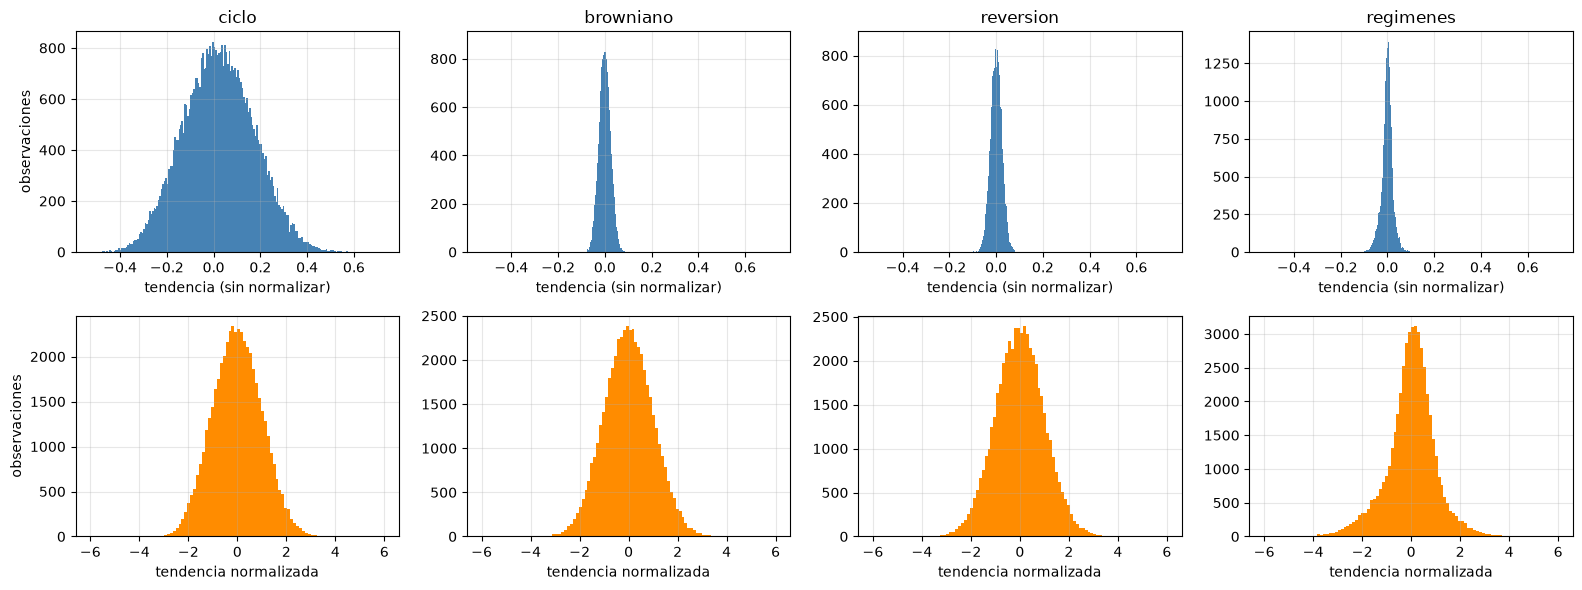

In [19]:
# Misma escala horizontal en cada fila: arriba la tendencia tal como la da el entorno, abajo normalizada
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex="row")
for j, g in enumerate(GENERADORES):
    t = TENDENCIAS_DISC[g]
    z = (t - NORMALIZACION[g]["media"]) / NORMALIZACION[g]["desv"]
    axes[0, j].hist(t, bins=200, color="steelblue")
    axes[0, j].set_title(g)
    axes[0, j].set_xlabel("tendencia (sin normalizar)")
    axes[1, j].hist(z, bins=100, range=(-6, 6), color="darkorange")
    axes[1, j].set_xlabel("tendencia normalizada")
    for ax in axes[:, j]:
        ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("observaciones")
axes[1, 0].set_ylabel("observaciones")
plt.tight_layout()
plt.show()

In [20]:
# Los parámetros se calcularon con las series de discretización; en validación (series nuevas)
# la tendencia normalizada debe quedar centrada y con desviación cercana a 1
comprobacion = {}
for g in GENERADORES:
    t_val = np.concatenate([tendencias_serie(p) for p in SERIES_VAL[g]])
    z_val = (t_val - NORMALIZACION[g]["media"]) / NORMALIZACION[g]["desv"]
    comprobacion[g] = {"media (validación)": z_val.mean(), "desv. típica (validación)": z_val.std()}
display(pd.DataFrame(comprobacion).T.round(3))

# Ejemplo: primera observación de una serie de validación y la entrada que recibirá la red
obs, _ = entorno.SimpleTradingEnv(SERIES_VAL["browniano"][0]).reset()
print("obs del entorno:", obs, "-> entrada de la red:", normalizar_obs(obs, **NORMALIZACION["browniano"]))

,media (validación),desv. típica (validación)
ciclo,-0.008,0.998
browniano,-0.011,0.982
reversion,0.002,0.986
regimenes,0.004,0.980


obs del entorno: [-0.00755097  0.        ] -> entrada de la red: [-0.29560187  0.        ]


**Resultado.** La desviación típica de la tendencia en *ciclo* es seis veces la de los otros tres generadores (0.153 frente a ~0.024). Normalizada, los cuatro quedan en la misma escala (98% central entre −2.8 y +2.5; extremos entre −5.6 y +4.9), sin necesidad de recortar. En validación, media ≈ 0 y desviación típica 0.98–1.00: la normalización se mantiene en series nuevas.

#### Resultados en disco

Cada entrenamiento guarda sus pesos y su curva en `resultados/`: el notebook se puede volver a ejecutar sin reentrenar.

In [21]:
CARPETA_RESULTADOS = Path("resultados")
CARPETA_RESULTADOS.mkdir(exist_ok=True)

### Fase 1: DQN

#### Diseño del agente

| Componente | Elección | Motivo |
|---|---|---|
| Red | 2 → 64 → 64 → 3 (ReLU, salida lineal) | Una salida por acción; dos capas bastan para relaciones no lineales con la tendencia |
| Memoria | 100 000 transiciones (~200 episodios), lotes de 64 al azar | Rompe la correlación entre transiciones consecutivas y reutiliza la experiencia |
| Red objetivo | Copia de la red cada 500 actualizaciones | El objetivo no persigue un blanco móvil: más estabilidad |
| Actualización | Cada 4 pasos, desde 1 000 transiciones | ~124 actualizaciones por episodio |
| Recompensa | Dividida por la volatilidad del generador | Ver abajo |
| Pérdida | Huber, gradiente recortado a norma 10 | Un paso extremo no arrastra a la red |
| Optimizador | Adam | Su tasa de aprendizaje es el $\alpha$ del enunciado |
| Exploración | ε-greedy, de 1 a 0.01 en línea recta | El esquema de la parte 1 |

En el último paso del episodio el objetivo es solo $r$.

#### Escala de la recompensa

Se divide por la desviación típica del retorno por paso de cada generador (series de discretización): un movimiento normal vale ~±1 en los cuatro mercados.

- **No cambia la política óptima:** escalar todas las recompensas por una constante positiva escala todos los $Q$ por igual.
- **Encaja con Huber,** que suaviza los errores mayores que 1: solo afecta a movimientos excepcionales. Con un factor fijo (retornos en %), un día normal de *ciclo* valdría ~±10.
- **Una misma $\alpha$ significa lo mismo en todos los mercados:** Optuna puede usar los mismos rangos.

In [22]:
from IPython.display import clear_output

from protocolo import desviacion_retorno
from dqn import CONFIG_DQN, REJILLA_Z, entrenar_dqn, guardar, cargar, red_desde_pesos, ventajas_en_rejilla

for g in GENERADORES:
    NORMALIZACION[g]["desv_retorno"] = desviacion_retorno(SERIES_DISC[g])

pd.DataFrame({g: {"desv. típica del retorno por paso": n["desv_retorno"],
                  "comisión (0.1%) en esas unidades": 0.001 / n["desv_retorno"]}
              for g, n in NORMALIZACION.items()}).T.round(4)

,desv. típica del retorno por paso,comisión (0.1%) en esas unidades
ciclo,0.1061,0.0094
browniano,0.0200,0.0500
reversion,0.0204,0.0490
regimenes,0.0189,0.0529


#### Seguimiento del entrenamiento

Cada 50 episodios: ganancia media de entrenamiento, política voraz en las 50 series de validación (la referencia fiable), operaciones, % invertido, pérdida, $|Q|$ medio y % de la rejilla de tendencias en que cambia la decisión. El gráfico se redibuja en cada control.

- **Parada automática** solo si la pérdida no es finita o $|Q| > 10^4$.
- **Se guardan** el modelo final (va a test, como en la parte 1) y el mejor en validación (diagnóstico de estabilidad). Si el resultado ya está en `resultados/`, se carga; para repetirlo con otra configuración hay que borrar su fichero.

In [23]:
REF_VAL = BASELINES_VAL.xs("Buy & hold", level="agente")["ret_log_medio"].to_dict()


def entrenar_o_cargar(ruta, entrenar):
    # Carga el resultado si ya está en disco; si no, entrena y lo guarda
    if ruta.exists():
        return cargar(ruta)
    resultado = entrenar()
    guardar(resultado, ruta)
    return resultado


def seguimiento(nombre, ref_bh, cada=50, exploracion=("epsilon", "ε"), magnitud=("q_medio", "|Q| medio")):
    # Devuelve la función que redibuja el seguimiento cada vez que el entrenamiento evalúa en validación.
    # exploracion y magnitud: (columna de la curva, etiqueta) de los paneles 2 y 3; por defecto, las del DQN
    def callback(curva, ganancias):
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
        episodios = np.arange(1, len(ganancias) + 1)

        # 1. Ganancia: cada episodio de entrenamiento, su media móvil y la política voraz en validación
        ax = axes[0]
        ax.plot(episodios, ganancias, color="lightgray", linewidth=0.6, label="entrenamiento (cada episodio)")
        ax.plot(episodios, pd.Series(ganancias).rolling(cada).mean(), color="dimgray",
                label=f"entrenamiento (media de {cada})")
        ax.plot(curva["episodio"], curva["ret_log_medio"], "o-", color="tab:blue", label="validación")
        ax.axhline(ref_bh, color="black", linestyle="--", linewidth=1, label="buy & hold (validación)")
        ax.axhline(0, color="black", linestyle=":", linewidth=1, label="no operar")
        ax.set_title(f"{nombre}: rentabilidad logarítmica")
        ax.legend(fontsize=7)

        # 2. Operaciones de la política voraz en validación y exploración
        ax = axes[1]
        ax.plot(curva["episodio"], curva["operaciones"], "o-", color="tab:orange")
        ax.set_ylabel("operaciones por episodio (validación)", color="tab:orange")
        ax_eps = ax.twinx()
        ax_eps.plot(curva["episodio"], curva[exploracion[0]], "--", color="tab:green")
        ax_eps.set_ylabel(exploracion[1], color="tab:green")
        ax.set_title("operaciones y exploración")

        # 3. Estabilidad de la red
        ax = axes[2]
        ax.plot(curva["episodio"], curva["perdida"], "o-", color="tab:red")
        ax.set_ylabel("pérdida de Huber", color="tab:red")
        ax_q = ax.twinx()
        ax_q.plot(curva["episodio"], curva[magnitud[0]], "--", color="tab:purple")
        ax_q.set_ylabel(magnitud[1], color="tab:purple")
        ax.set_title(f"pérdida y {magnitud[1]}")

        for ax in axes:
            ax.set_xlabel("episodio")
            ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

        u = curva.iloc[-1]
        print(f"episodio {u['episodio']:.0f} | {exploracion[1]} {u[exploracion[0]]:.2f} | "
              f"entrenamiento {u['ganancia_entren']:+.3f} | validación {u['ret_log_medio']:+.3f} "
              f"(buy & hold {ref_bh:+.3f}) | operaciones {u['operaciones']:.1f} | invertido {u['pct_invertido']:.0f}% | "
              f"pérdida {u['perdida']:.3f} | {magnitud[1]} {u[magnitud[0]]:.2f} | {u['tiempo_s']:.0f} s")
    return callback

#### Primera prueba

Comprobación de que la implementación aprende, en dos mercados:

- ***Ciclo***: señal fuerte; un DQN correcto debe superar claramente a *buy & hold*.
- ***Reversión***: señal pequeña y solo en los extremos; el mercado más sensible a los hiperparámetros en la parte 1.

En *browniano* y *regímenes* no operar es lo razonable, y también lo que haría un agente roto: no sirven para esta comprobación. Configuración: $\alpha$ = 0.001, $\gamma$ = 0.5, exploración 50%, 600 episodios, una repetición.

In [24]:
CONFIG_PRUEBA = {"lr": 1e-3, "gamma": 0.5, "frac_exploracion": 0.5}
N_EP_PRUEBA = 600
PRUEBA_DQN = {}

# Configuración completa de la prueba: valores por defecto del módulo con los de CONFIG_PRUEBA
pd.Series({**CONFIG_DQN, **CONFIG_PRUEBA}).to_frame("valor")

,valor
lr,0.001
gamma,0.500
frac_exploracion,0.500
eps_inicial,1.000
eps_final,0.010
n_ocultas,64.000
tam_lote,64.000
tam_memoria,100000.000
inicio_aprendizaje,1000.000
cada_pasos,4.000


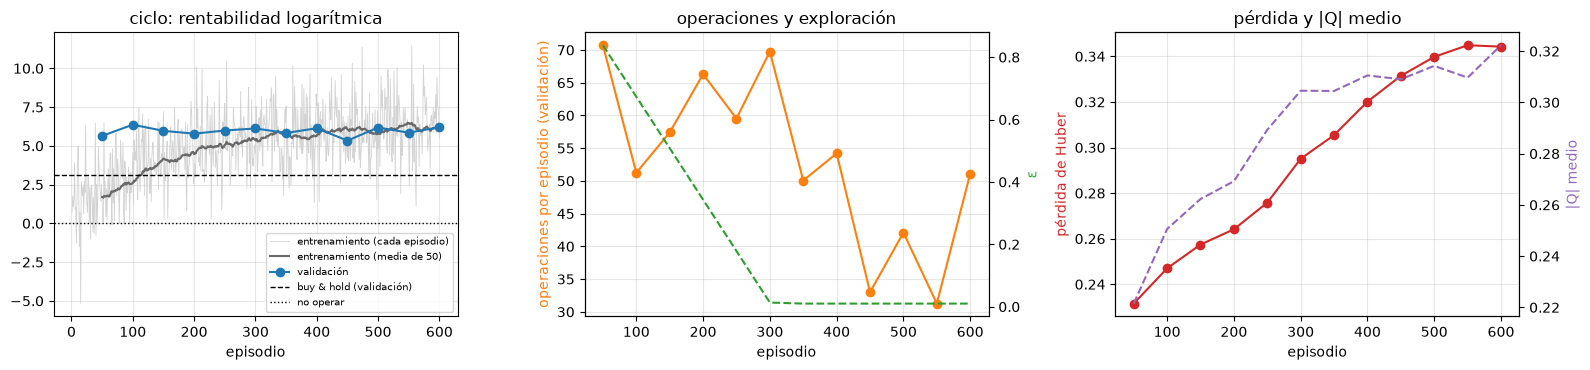

episodio 600 | ε 0.01 | entrenamiento +6.295 | validación +6.202 (buy & hold +3.113) | operaciones 51.1 | invertido 67% | pérdida 0.344 | |Q| medio 0.32 | 31 s


In [25]:
g = "ciclo"
PRUEBA_DQN[g] = entrenar_o_cargar(
    CARPETA_RESULTADOS / f"prueba_dqn_{g}.pkl",
    lambda: entrenar_dqn(g, NORMALIZACION[g], CONFIG_PRUEBA, n_episodios=N_EP_PRUEBA,
                         series_val=SERIES_VAL[g], cada=50, callback=seguimiento(g, REF_VAL[g])))
seguimiento(g, REF_VAL[g])(PRUEBA_DQN[g]["curva"], PRUEBA_DQN[g]["ganancias"])

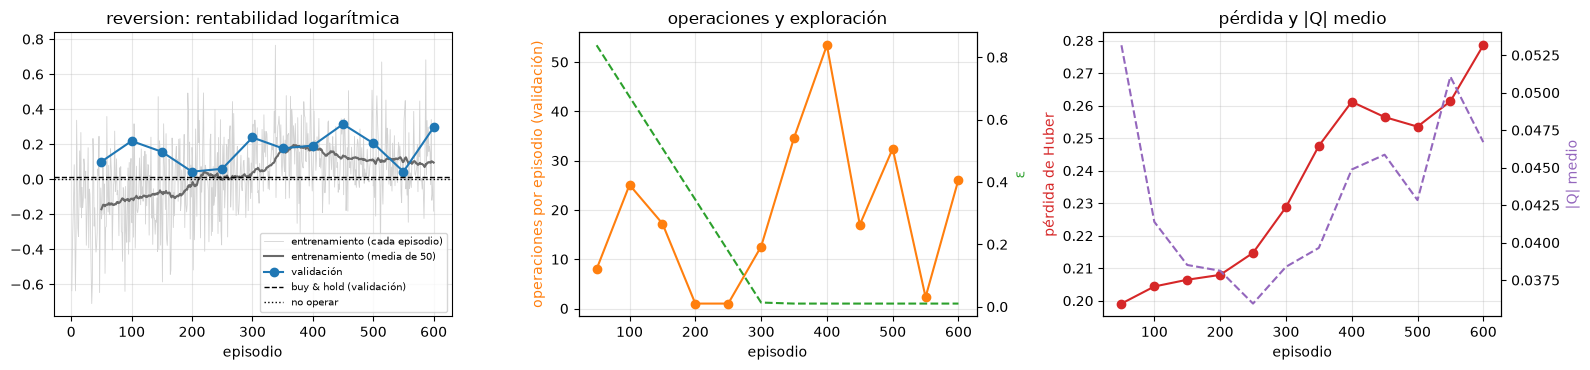

episodio 600 | ε 0.01 | entrenamiento +0.095 | validación +0.296 (buy & hold +0.013) | operaciones 26.2 | invertido 45% | pérdida 0.279 | |Q| medio 0.05 | 30 s


In [26]:
g = "reversion"
PRUEBA_DQN[g] = entrenar_o_cargar(
    CARPETA_RESULTADOS / f"prueba_dqn_{g}.pkl",
    lambda: entrenar_dqn(g, NORMALIZACION[g], CONFIG_PRUEBA, n_episodios=N_EP_PRUEBA,
                         series_val=SERIES_VAL[g], cada=50, callback=seguimiento(g, REF_VAL[g])))
seguimiento(g, REF_VAL[g])(PRUEBA_DQN[g]["curva"], PRUEBA_DQN[g]["ganancias"])

In [27]:
filas = []
for g, r in PRUEBA_DQN.items():
    c = r["curva"]
    filas.append({
        "generador": g,
        "buy & hold (val.)": REF_VAL[g],
        "final (val.)": c["ret_log_medio"].iloc[-1],
        "media últimas 4 evaluaciones": c["ret_log_medio"].iloc[-4:].mean(),
        "mejor (val.)": c["ret_log_medio"].max(),
        "episodio del mejor": r["mejor_episodio"],
        "operaciones (final)": c["operaciones"].iloc[-1],
        "cambios de política, % (últimas 4)": c["cambios_politica_%"].iloc[-4:].mean(),
        "ms por episodio": 1000 * r["tiempo"] / r["n_episodios"],
        "divergió": r["divergio"],
    })
pd.DataFrame(filas).set_index("generador").round(3)

,buy & hold (val.),final (val.),media últimas 4 evaluaciones,mejor (val.),episodio del mejor,operaciones (final),"cambios de política, % (últimas 4)",ms por episodio,divergió
generador,,,,,,,,,
ciclo,3.113,6.202,5.893,6.363,100,51.10,4.132,51.464,False
reversion,0.013,0.296,0.215,0.314,450,26.16,16.219,50.556,False


#### Política aprendida

Para cada valor de la tendencia, ventaja de cambiar de posición frente a quedarse como se está:

- sin activo: $Q(\text{comprar}) - \max\big(Q(\text{vender}), Q(\text{mantener})\big)$; positiva → compra;
- con activo: $Q(\text{vender}) - \max\big(Q(\text{mantener}), Q(\text{comprar})\big)$; positiva → vende.

Es el equivalente continuo de las rejillas C/V de la parte 1; la distancia a cero mide la seguridad de la decisión.

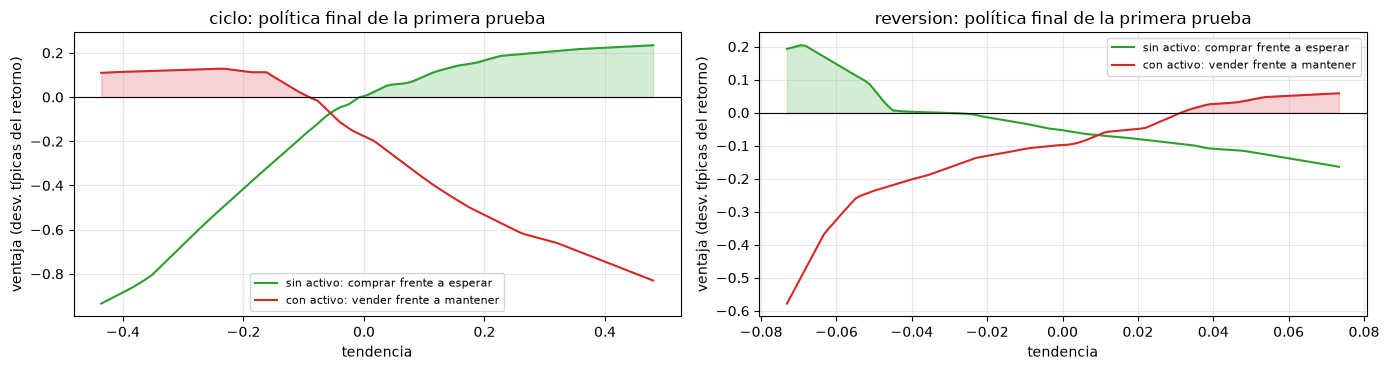

In [28]:
def grafico_politica(resultados, titulo):
    fig, axes = plt.subplots(1, len(resultados), figsize=(7 * len(resultados), 3.8), squeeze=False)
    for ax, (g, r) in zip(axes[0], resultados.items()):
        red = red_desde_pesos(r["pesos"], r["config"]["n_ocultas"])
        ventaja_compra, ventaja_venta = ventajas_en_rejilla(red)
        tendencia = NORMALIZACION[g]["media"] + REJILLA_Z * NORMALIZACION[g]["desv"]  # de vuelta a unidades del entorno

        ax.plot(tendencia, ventaja_compra, color="tab:green", label="sin activo: comprar frente a esperar")
        ax.plot(tendencia, ventaja_venta, color="tab:red", label="con activo: vender frente a mantener")
        ax.fill_between(tendencia, 0, ventaja_compra, where=ventaja_compra > 0, color="tab:green", alpha=0.2)
        ax.fill_between(tendencia, 0, ventaja_venta, where=ventaja_venta > 0, color="tab:red", alpha=0.2)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(f"{g}: {titulo}")
        ax.set_xlabel("tendencia")
        ax.set_ylabel("ventaja (desv. típicas del retorno)")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


grafico_politica(PRUEBA_DQN, "política final de la primera prueba")

**Resultado.**

- **Funciona:** en *ciclo*, 6.20 en validación frente a 3.11 de *buy & hold*, desde los primeros episodios.
- **Estrategia esperada:** sigue la tendencia en *ciclo*; en *reversión* compra tras caídas fuertes (tendencia < −0.045) y vende tras subidas (> +0.03), umbrales cercanos a los deciles de la parte 1 sin haber discretizado.
- **Punto débil, la estabilidad en *reversión*:** la validación oscila entre 0.04 y 0.31 y la decisión cambia en el 16% de la rejilla entre controles (4% en *ciclo*). Las ventajas entre acciones son pequeñas frente al tamaño de cada actualización ($\alpha$ = 0.001); se ajusta en la fase 2.
- **Coste:** ~51 ms por episodio.

### Fase 2: Ajuste de hiperparámetros del DQN

Búsqueda conjunta con Optuna (muestreador TPE multivariante), un estudio por mercado. Ajustar los hiperparámetros de uno en uno, como en la parte 1, no detecta sus interacciones; TPE prueba combinaciones completas y concentra la búsqueda en las zonas prometedoras.

| Hiperparámetro | Rango |
|---|---|
| $\alpha$ | $10^{-5}$ a $3 \cdot 10^{-3}$, escala logarítmica |
| $\gamma$ | a través del horizonte $1/(1-\gamma)$: de 2 a 100 pasos ($\gamma$ de 0.5 a 0.99), escala logarítmica |
| Exploración | fracción de los episodios en que ε baja de 1 a 0.01: de 10% a 80% |

- **Cada prueba:** 1 000 episodios, con las mismas series de entrenamiento en todas (repetición 0).
- **Puntuación:** rentabilidad logarítmica media en validación en los 5 últimos controles (episodios 800–1 000). Penaliza la inestabilidad; con exploración ≤ 80%, esos controles llegan con la exploración terminada.
- **Presupuesto:** 40 pruebas por mercado, 8 procesos en paralelo (2 por mercado), sin poda. Si se interrumpe, al relanzar continúa donde se quedó.
- **Confirmación:** las 3 mejores de cada mercado se repiten con 3 semillas nuevas; se elige la de mejor media.
- El número de episodios se fija más adelante, con las curvas de convergencia.

In [29]:
import json
import multiprocessing as mp

import optuna

from protocolo import normalizacion
from ajuste import (N_CONTROLES, almacen, terminadas, limpiar_interrumpidas, prueba_dqn, confirmar_dqn,
                    puntuacion)

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Cada proceso calcula la normalización por su cuenta: debe coincidir con la del notebook
assert all(normalizacion(g) == NORMALIZACION[g] for g in GENERADORES)

RUTA_OPTUNA_DQN = CARPETA_RESULTADOS / "optuna_dqn.log"
N_PRUEBAS = 40
N_PROCESOS = 8
PROCESOS_POR_MERCADO = N_PROCESOS // len(GENERADORES)

ESTUDIOS_DQN = {g: optuna.create_study(study_name=f"dqn_{g}", storage=almacen(RUTA_OPTUNA_DQN),
                                       direction="maximize", load_if_exists=True) for g in GENERADORES}
for e in ESTUDIOS_DQN.values():
    limpiar_interrumpidas(e)


def progreso(estudios):
    filas = []
    for g, e in estudios.items():
        hechas = terminadas(e)
        filas.append({"mercado": g, "pruebas terminadas": len(hechas),
                      "mejor puntuación": max((t.value for t in hechas), default=np.nan)})
    return pd.DataFrame(filas).set_index("mercado").round(3)


# Cada tarea es una prueba (un entrenamiento); se mantienen 2 en marcha por mercado hasta tener N_PRUEBAS
# terminadas. Si se interrumpe la celda, el "with" detiene los procesos; al relanzarla, continúa donde iba.
semilla = sum(len(e.trials) for e in ESTUDIOS_DQN.values())  # semillas del muestreador nuevas también al retomar
t0 = ultimo = time.perf_counter()
with mp.get_context("spawn").Pool(N_PROCESOS) as pool:
    en_marcha = []  # (mercado, resultado pendiente)
    while True:
        for g in GENERADORES:
            activas = sum(m == g for m, _ in en_marcha)
            faltan = N_PRUEBAS - len(terminadas(ESTUDIOS_DQN[g])) - activas
            for _ in range(min(faltan, PROCESOS_POR_MERCADO - activas)):
                en_marcha.append((g, pool.apply_async(prueba_dqn, (g, RUTA_OPTUNA_DQN, semilla))))
                semilla += 1
        if not en_marcha:
            break
        time.sleep(2)
        for tarea in [x for x in en_marcha if x[1].ready()]:
            tarea[1].get()  # si una prueba ha fallado, su error aparece aquí
            en_marcha.remove(tarea)
        if time.perf_counter() - ultimo > 30:
            ultimo = time.perf_counter()
            clear_output(wait=True)
            print(f"Búsqueda en marcha: {(ultimo - t0) / 60:.1f} min")
            display(progreso(ESTUDIOS_DQN))

clear_output(wait=True)
print(f"Búsqueda terminada en {(time.perf_counter() - t0) / 60:.1f} min")
progreso(ESTUDIOS_DQN)

Búsqueda terminada en 0.0 min


,pruebas terminadas,mejor puntuación
mercado,,
ciclo,40,6.328
browniano,40,0.000
reversion,40,0.278
regimenes,40,0.010


In [30]:
def config_de(t):
    return {"lr": t.params["lr"], "gamma": 1 - 1 / t.params["horizonte"],
            "frac_exploracion": t.params["frac_exploracion"]}


filas = []
for g, e in ESTUDIOS_DQN.items():
    hechas = terminadas(e)
    mejor = max(hechas, key=lambda t: t.value)
    filas.append({"mercado": g, "pruebas": len(hechas),
                  "divergidas": sum(t.user_attrs["divergio"] for t in hechas),
                  "mejor puntuación": mejor.value, "buy & hold (val.)": REF_VAL[g],
                  "α": f"{mejor.params['lr']:.1e}", "γ": config_de(mejor)["gamma"],
                  "horizonte (pasos)": mejor.params["horizonte"], "exploración": mejor.params["frac_exploracion"]})
pd.DataFrame(filas).set_index("mercado").round(3)

,pruebas,divergidas,mejor puntuación,buy & hold (val.),α,γ,horizonte (pasos),exploración
mercado,,,,,,,,
ciclo,40,0,6.328,3.113,1.6e-04,0.986,70.997,0.585
browniano,40,0,0.000,-0.110,1.1e-05,0.753,4.049,0.424
reversion,40,0,0.278,0.013,1.1e-05,0.785,4.654,0.471
regimenes,40,0,0.010,-0.212,1.3e-05,0.535,2.150,0.294


#### Relación de cada hiperparámetro con la puntuación

Puntuación de cada prueba frente a cada hiperparámetro, con su correlación de rangos ($\rho$ de Spearman), en lugar de un índice de importancia:

- El índice por defecto de Optuna (PED-ANOVA) compara el 10% mejor de las pruebas con el resto: 4 pruebas por mercado.
- fANOVA trata $\alpha$ y el horizonte en escala lineal (las pruebas con $\alpha < 10^{-4}$ ocupan el 3% del eje) y, con 40 pruebas de una sola semilla, lo dominan unas pocas atípicas.

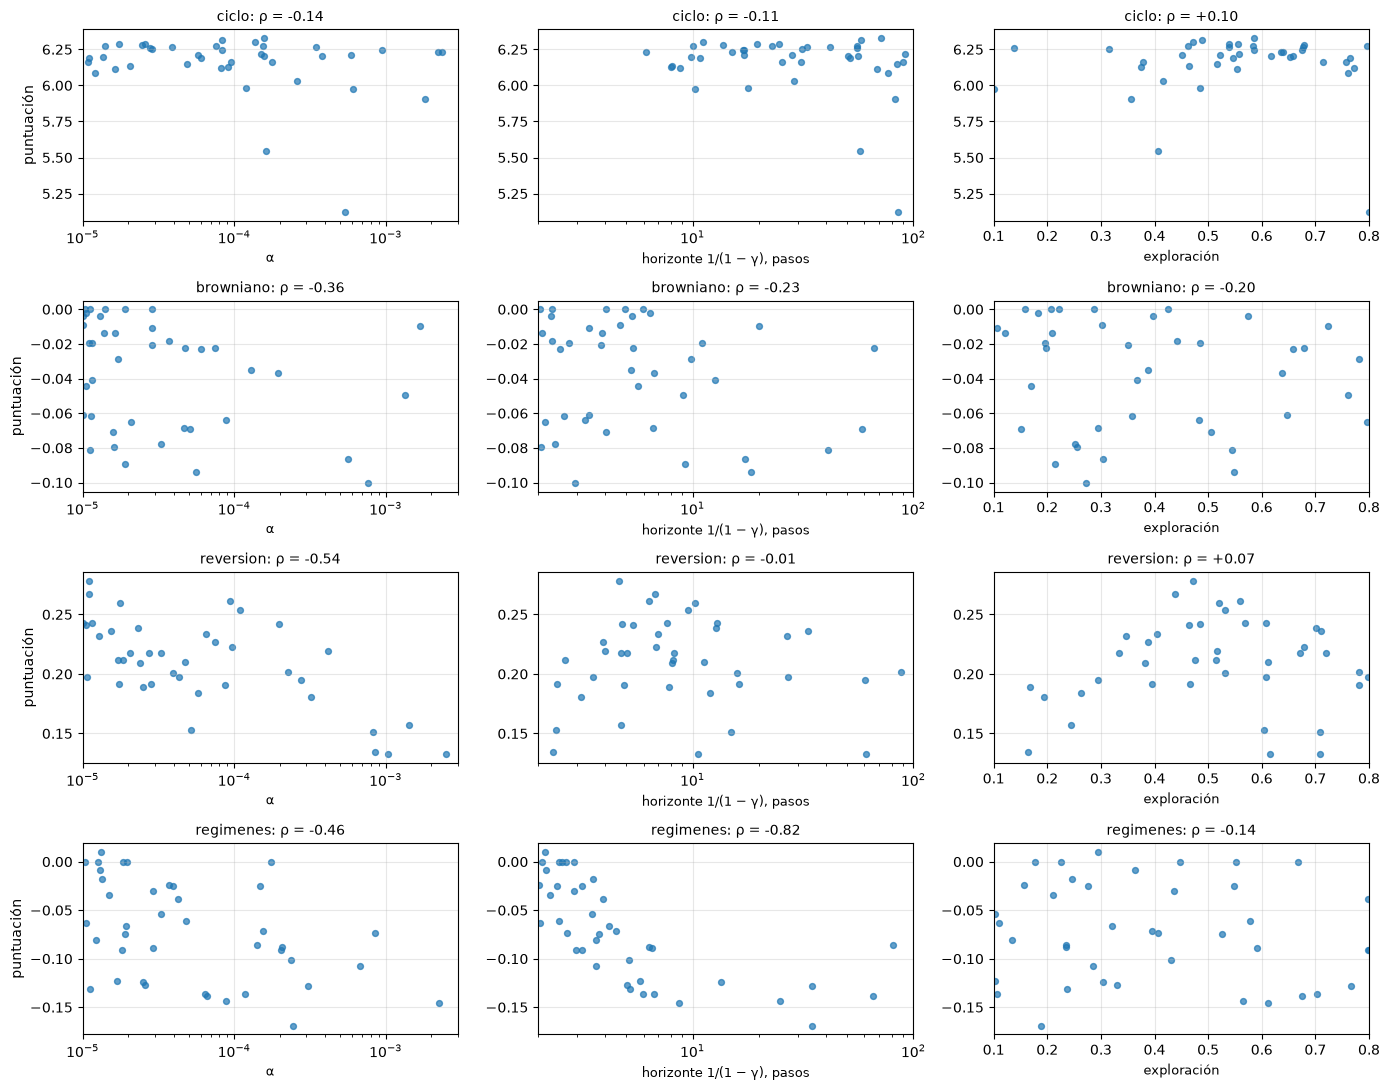

In [31]:
RANGOS = {"lr": ("α", (1e-5, 3e-3)), "horizonte": ("horizonte 1/(1 − γ), pasos", (2, 100)),
          "frac_exploracion": ("exploración", (0.1, 0.8))}

fig, axes = plt.subplots(len(ESTUDIOS_DQN), len(RANGOS), figsize=(14, 11))
for fila, (g, e) in zip(axes, ESTUDIOS_DQN.items()):
    hechas = terminadas(e)
    puntos = pd.Series([t.value for t in hechas])
    for ax, (p, (etiqueta, rango)) in zip(fila, RANGOS.items()):
        x = pd.Series([t.params[p] for t in hechas])
        rho = x.rank().corr(puntos.rank())  # Spearman: correlación de Pearson entre los rangos
        ax.scatter(x, puntos, s=18, color="tab:blue", alpha=0.7)
        if p != "frac_exploracion":
            ax.set_xscale("log")
        ax.set_xlim(*rango)
        ax.set_title(f"{g}: ρ = {rho:+.2f}", fontsize=10)
        ax.set_xlabel(etiqueta, fontsize=9)
        ax.grid(alpha=0.3)
    fila[0].set_ylabel("puntuación")
plt.tight_layout()
plt.show()

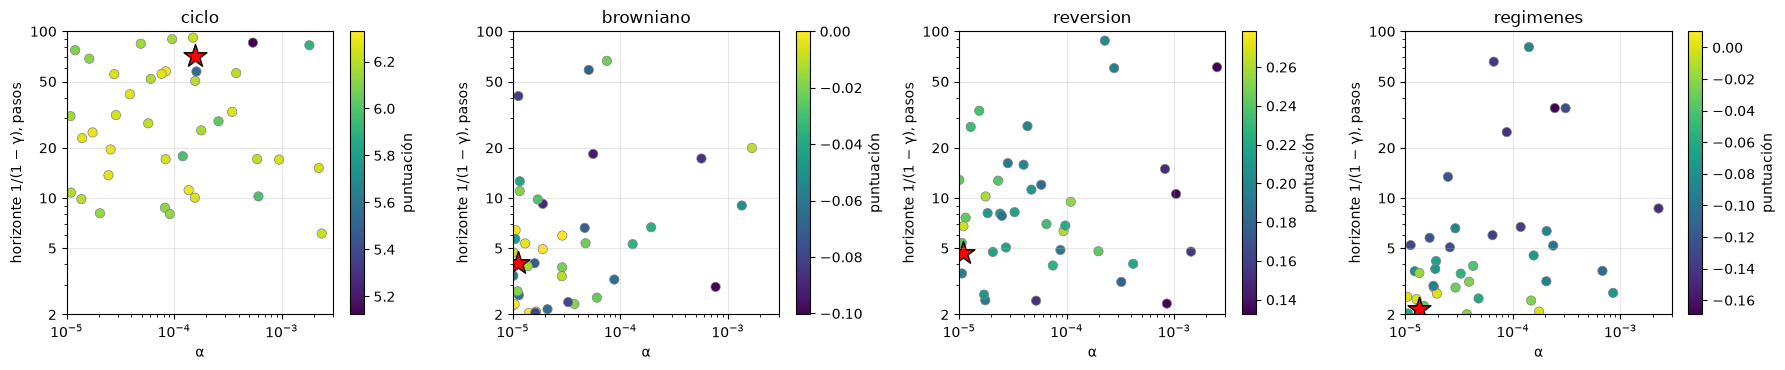

In [32]:
# Combinaciones α × horizonte probadas, coloreadas por puntuación; la estrella es la mejor
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (g, e) in zip(axes, ESTUDIOS_DQN.items()):
    hechas = terminadas(e)
    puntos = ax.scatter([t.params["lr"] for t in hechas], [t.params["horizonte"] for t in hechas],
                        c=[t.value for t in hechas], cmap="viridis", s=45, edgecolor="gray", linewidth=0.5)
    mejor = max(hechas, key=lambda t: t.value)
    ax.scatter(mejor.params["lr"], mejor.params["horizonte"], marker="*", s=300, color="red", edgecolor="black")
    # Mismos ejes en los cuatro mercados: el rango completo de la búsqueda
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1e-5, 3e-3)
    ax.set_ylim(2, 100)
    ax.set_yticks([2, 5, 10, 20, 50, 100], ["2", "5", "10", "20", "50", "100"])
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("α")
    ax.set_ylabel("horizonte 1/(1 − γ), pasos")
    ax.set_title(g)
    ax.grid(alpha=0.3)
    plt.colorbar(puntos, ax=ax, label="puntuación")
plt.tight_layout()
plt.show()

#### Confirmación

Cada prueba de la búsqueda es un único entrenamiento con las series de la repetición 0, así que la mejor puntuación puede deberse en parte a la suerte. Las 3 mejores configuraciones de cada mercado se repiten con 3 semillas nuevas (otras series de entrenamiento y otra inicialización de la red) y se elige la de mejor media.

In [33]:
N_MEJORES = 3
REPS_CONFIRMACION = (1, 2, 3)

CANDIDATAS = {g: sorted(terminadas(e), key=lambda t: t.value, reverse=True)[:N_MEJORES]
              for g, e in ESTUDIOS_DQN.items()}
tareas = {(g, t.number, rep): config_de(t)
          for g, ts in CANDIDATAS.items() for t in ts for rep in REPS_CONFIRMACION}

t0 = time.perf_counter()
with mp.get_context("spawn").Pool(N_PROCESOS) as pool:
    pendientes = {(g, n, rep): pool.apply_async(
                      confirmar_dqn, (g, config, rep, CARPETA_RESULTADOS / f"confirmacion_dqn_{g}_p{n}_r{rep}.pkl"))
                  for (g, n, rep), config in tareas.items()}
    while not all(r.ready() for r in pendientes.values()):
        time.sleep(10)
        clear_output(wait=True)
        print(f"Confirmación en marcha: {sum(r.ready() for r in pendientes.values())}/{len(pendientes)} "
              f"entrenamientos, {(time.perf_counter() - t0) / 60:.1f} min")
    CONFIRMACION = {k: r.get() for k, r in pendientes.items()}

clear_output(wait=True)
print(f"Confirmación terminada en {(time.perf_counter() - t0) / 60:.1f} min")

Confirmación terminada en 0.2 min


In [34]:
filas = []
for g, ts in CANDIDATAS.items():
    for t in ts:
        puntos = [puntuacion(CONFIRMACION[(g, t.number, rep)]["curva"]) for rep in REPS_CONFIRMACION]
        filas.append({"mercado": g, "prueba": t.number, **config_de(t),
                      "puntuación en la búsqueda": t.value,
                      "media con 3 semillas nuevas": np.mean(puntos), "desv. entre semillas": np.std(puntos)})
TABLA_CONFIRMACION = pd.DataFrame(filas)

# Configuración elegida en cada mercado: la de mejor media con las semillas nuevas
ELEGIDAS = TABLA_CONFIRMACION.loc[TABLA_CONFIRMACION.groupby("mercado", sort=False)["media con 3 semillas nuevas"].idxmax()]
CONFIG_DQN_ELEGIDA = {f["mercado"]: {k: float(f[k]) for k in ("lr", "gamma", "frac_exploracion")}
                      for _, f in ELEGIDAS.iterrows()}
with open(CARPETA_RESULTADOS / "config_dqn_elegida.json", "w") as fichero:
    json.dump(CONFIG_DQN_ELEGIDA, fichero, indent=1)

TABLA_CONFIRMACION["elegida"] = TABLA_CONFIRMACION.index.isin(ELEGIDAS.index)
TABLA_CONFIRMACION["lr"] = TABLA_CONFIRMACION["lr"].map("{:.1e}".format)
TABLA_CONFIRMACION.rename(columns={"lr": "α", "gamma": "γ", "frac_exploracion": "exploración"}) \
    .set_index(["mercado", "prueba"]).round(3)

α      γ  exploración  puntuación en la búsqueda  \
mercado   prueba                                                           
ciclo     15      1.6e-04  0.986        0.585                      6.328   
          8       8.4e-05  0.983        0.489                      6.313   
          32      1.4e-04  0.910        0.472                      6.300   
browniano 2       1.1e-05  0.753        0.424                      0.000   
          26      1.4e-05  0.511        0.222                      0.000   
          28      1.0e-05  0.566        0.207                      0.000   
reversion 30      1.1e-05  0.785        0.471                      0.278   
          20      1.1e-05  0.852        0.437                      0.267   
          13      9.4e-05  0.842        0.559                      0.261   
regimenes 23      1.3e-05  0.535        0.294                      0.010   
          17      1.9e-05  0.654        0.668                      0.000   
          25      2.0e-05  0.626        0.225                      0.000   

                  media con 3 semillas nuevas  desv. entre semillas  elegida  
mercado   prueba                                                              
ciclo     15                            5.947                 0.224    False  
          8                             5.975                 0.256    False  
          32                            6.158                 0.038     True  
browniano 2                            -0.033                 0.033    False  
          26                           -0.034                 0.037    False  
          28                           -0.007                 0.010     True  
reversion 30                            0.249                 0.012     True  
          20                            0.228                 0.011    False  
          13                            0.196                 0.020    False  
regimenes 23                            0.010                 0.008     True  
          17                           -0.013                 0.014    False  
          25                           -0.022                 0.016    False

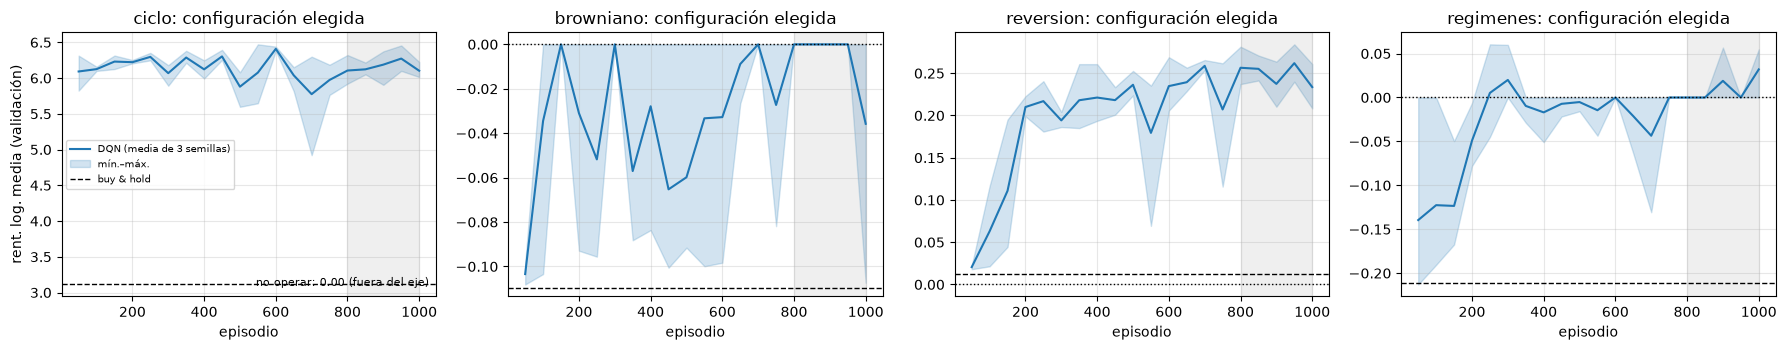

In [35]:
def linea_referencia(ax, y, valores, **kwargs):
    # Dibuja la línea si cae cerca de las curvas; si no, escribe su valor para no aplastar el eje (como en la parte 1)
    lo, hi = np.min(valores), np.max(valores)
    if lo - 2 * (hi - lo) <= y <= hi + 2 * (hi - lo):
        ax.axhline(y, **kwargs)
    else:
        ax.text(0.98, 0.04 + 0.08 * len(ax.texts), f"{kwargs.get('label', '')}: {y:.2f} (fuera del eje)",
                transform=ax.transAxes, ha="right", fontsize=8)


# Validación de la configuración elegida con las 3 semillas nuevas; en gris, los controles que puntúan
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, (_, f) in zip(axes, ELEGIDAS.iterrows()):
    g, n = f["mercado"], f["prueba"]
    curvas = np.array([CONFIRMACION[(g, n, rep)]["curva"]["ret_log_medio"] for rep in REPS_CONFIRMACION])
    episodios = CONFIRMACION[(g, n, REPS_CONFIRMACION[0])]["curva"]["episodio"]
    ax.plot(episodios, curvas.mean(0), color="tab:blue", label="DQN (media de 3 semillas)")
    ax.fill_between(episodios, curvas.min(0), curvas.max(0), color="tab:blue", alpha=0.2, label="mín.–máx.")
    ax.axvspan(episodios.iloc[-min(N_CONTROLES, len(episodios))], episodios.iloc[-1], color="gray", alpha=0.12)
    linea_referencia(ax, REF_VAL[g], curvas, color="black", linestyle="--", linewidth=1, label="buy & hold")
    linea_referencia(ax, 0, curvas, color="black", linestyle=":", linewidth=1, label="no operar")
    ax.set_title(f"{g}: configuración elegida")
    ax.set_xlabel("episodio")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("rent. log. media (validación)")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

#### Comprobaciones dirigidas

Dos zonas que la búsqueda no cubrió y que pueden cambiar la elección:

- ***Reversión*: $\alpha$ en el borde del rango.** La puntuación media mejora al bajar $\alpha$ (0.18 con $\alpha > 1.2 \cdot 10^{-4}$, 0.24 entre $10^{-5}$ y $1.3 \cdot 10^{-5}$) y la elegida está en el límite inferior. Se prueban $\alpha$ = 5e-6 y 3e-6.
- ***Regímenes*: $\alpha$ pequeña con horizonte largo.** Las 5 pruebas con horizonte ≥ 20 son de la fase aleatoria inicial, todas con $\alpha \geq 6.6 \cdot 10^{-5}$, y TPE no volvió a esa zona; en la parte 1 solo funcionó $\gamma$ = 0.99. Se prueban $\alpha \in$ {1e-5, 3e-5} × horizonte $\in$ {50, 100}.

El resto de la configuración es el elegido, con las mismas 3 semillas que la confirmación (mismas series de entrenamiento e inicialización: comparación pareada).

**Criterio, fijado antes de ejecutar:** una alternativa sustituye a la elegida solo si la supera en las 3 semillas; si lo hacen varias, la de mejor media.

In [36]:
# Cada alternativa es la configuración elegida con estos cambios
COMPROBACIONES = {
    "reversion": [{"lr": lr} for lr in (5e-6, 3e-6)],
    "regimenes": [{"lr": lr, "gamma": 1 - 1 / h} for lr in (1e-5, 3e-5) for h in (50, 100)],
}
PRUEBA_ELEGIDA = ELEGIDAS.set_index("mercado")["prueba"].to_dict()
CONFIG_CONFIRMADA = {f["mercado"]: {k: float(f[k]) for k in ("lr", "gamma", "frac_exploracion")}
                     for _, f in ELEGIDAS.iterrows()}
ALTERNATIVAS = {(g, i): {**CONFIG_CONFIRMADA[g], **cambio}
                for g, cambios in COMPROBACIONES.items() for i, cambio in enumerate(cambios)}


def ruta_comprobacion(g, config, rep):
    return CARPETA_RESULTADOS / (f"comprobacion_dqn_{g}_p{PRUEBA_ELEGIDA[g]}_lr{config['lr']:.0e}"
                                 f"_h{1 / (1 - config['gamma']):.0f}_r{rep}.pkl")


t0 = time.perf_counter()
with mp.get_context("spawn").Pool(N_PROCESOS) as pool:
    pendientes = {(g, i, rep): pool.apply_async(confirmar_dqn, (g, config, rep, ruta_comprobacion(g, config, rep)))
                  for (g, i), config in ALTERNATIVAS.items() for rep in REPS_CONFIRMACION}
    while not all(r.ready() for r in pendientes.values()):
        time.sleep(10)
        clear_output(wait=True)
        print(f"Comprobaciones en marcha: {sum(r.ready() for r in pendientes.values())}/{len(pendientes)} "
              f"entrenamientos, {(time.perf_counter() - t0) / 60:.1f} min")
    COMPROBACION = {k: r.get() for k, r in pendientes.items()}

clear_output(wait=True)
print(f"Comprobaciones terminadas en {(time.perf_counter() - t0) / 60:.1f} min")

Comprobaciones terminadas en 0.2 min


In [37]:
def puntos_y_operaciones(resultados):
    # Puntuación de cada semilla y operaciones por episodio en el último control (media de las semillas)
    return (np.array([puntuacion(r["curva"]) for r in resultados]),
            np.mean([r["curva"]["operaciones"].iloc[-1] for r in resultados]))


filas = []
for g, cambios in COMPROBACIONES.items():
    n = PRUEBA_ELEGIDA[g]
    base, ops = puntos_y_operaciones([CONFIRMACION[(g, n, rep)] for rep in REPS_CONFIRMACION])
    candidatas = [(f"elegida (prueba {n})", CONFIG_CONFIRMADA[g], base, ops, False)]
    for i in range(len(cambios)):
        puntos, ops = puntos_y_operaciones([COMPROBACION[(g, i, rep)] for rep in REPS_CONFIRMACION])
        candidatas.append((f"alternativa {i + 1}", ALTERNATIVAS[(g, i)], puntos, ops, bool((puntos > base).all())))

    for nombre, config, puntos, ops, supera in candidatas:
        filas.append({"mercado": g, "configuración": nombre, "α": f"{config['lr']:.1e}",
                      "horizonte": 1 / (1 - config["gamma"]),
                      **{f"semilla {rep}": p for rep, p in zip(REPS_CONFIRMACION, puntos)},
                      "media": puntos.mean(), "desv.": puntos.std(), "operaciones (final)": ops,
                      "supera a la elegida en las 3 semillas": supera})

    # Criterio fijado antes de ejecutar
    ganadoras = [c for c in candidatas if c[4]]
    if ganadoras:
        nombre, config, *_ = max(ganadoras, key=lambda c: c[2].mean())
        CONFIG_DQN_ELEGIDA[g] = config
        print(f"{g}: se adopta la {nombre}")
    else:
        CONFIG_DQN_ELEGIDA[g] = CONFIG_CONFIRMADA[g]
        print(f"{g}: se mantiene la configuración elegida")

with open(CARPETA_RESULTADOS / "config_dqn_elegida.json", "w") as fichero:
    json.dump(CONFIG_DQN_ELEGIDA, fichero, indent=1)

TABLA_COMPROBACION = pd.DataFrame(filas).set_index(["mercado", "configuración"])
TABLA_COMPROBACION.round(3)

reversion: se mantiene la configuración elegida
regimenes: se mantiene la configuración elegida


α  horizonte  semilla 1  semilla 2  \
mercado   configuración                                                   
reversion elegida (prueba 30)  1.1e-05      4.654      0.233      0.262   
          alternativa 1        5.0e-06      4.654      0.231      0.233   
          alternativa 2        3.0e-06      4.654      0.234      0.244   
regimenes elegida (prueba 23)  1.3e-05      2.150      0.020      0.011   
          alternativa 1        1.0e-05     50.000     -0.142     -0.138   
          alternativa 2        1.0e-05    100.000     -0.198     -0.181   
          alternativa 3        3.0e-05     50.000     -0.126     -0.135   
          alternativa 4        3.0e-05    100.000     -0.150     -0.127   

                               semilla 3  media  desv.  operaciones (final)  \
mercado   configuración                                                       
reversion elegida (prueba 30)      0.252  0.249  0.012               34.693   
          alternativa 1            0.192  0.219  0.019               27.220   
          alternativa 2            0.223  0.234  0.008               29.287   
regimenes elegida (prueba 23)      0.000  0.010  0.008               12.547   
          alternativa 1           -0.117 -0.132  0.011               29.153   
          alternativa 2           -0.130 -0.170  0.029               21.620   
          alternativa 3           -0.107 -0.123  0.012               28.960   
          alternativa 4           -0.128 -0.135  0.011               21.567   

                               supera a la elegida en las 3 semillas  
mercado   configuración                                               
reversion elegida (prueba 30)                                  False  
          alternativa 1                                        False  
          alternativa 2                                        False  
regimenes elegida (prueba 23)                                  False  
          alternativa 1                                        False  
          alternativa 2                                        False  
          alternativa 3                                        False  
          alternativa 4                                        False

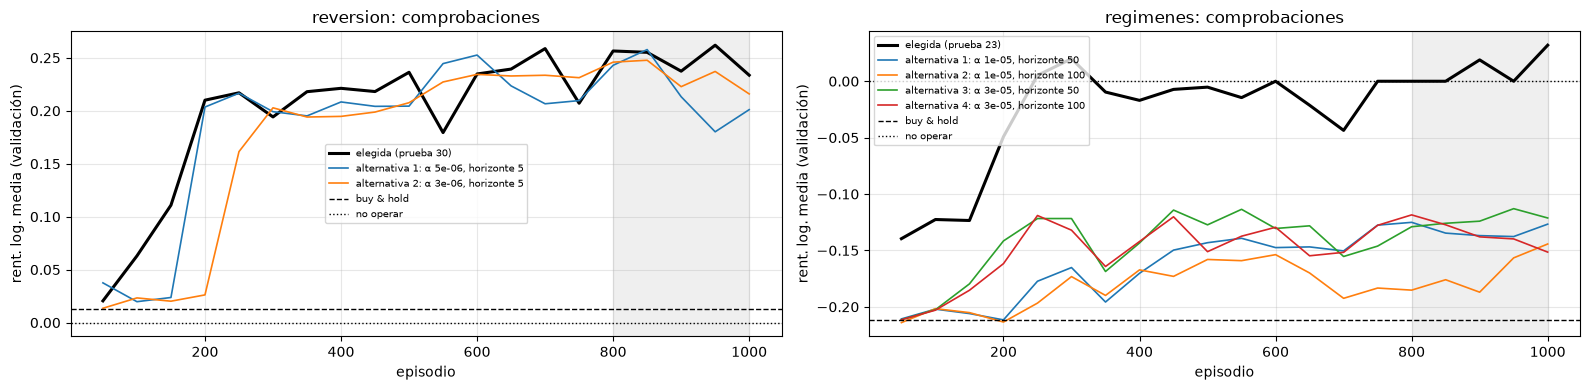

In [38]:
# Validación media de las 3 semillas de cada configuración; en gris, los controles que puntúan
fig, axes = plt.subplots(1, len(COMPROBACIONES), figsize=(16, 4))
for ax, (g, cambios) in zip(axes, COMPROBACIONES.items()):
    n = PRUEBA_ELEGIDA[g]
    grupos = {f"elegida (prueba {n})": [CONFIRMACION[(g, n, rep)] for rep in REPS_CONFIRMACION]}
    for i in range(len(cambios)):
        config = ALTERNATIVAS[(g, i)]
        grupos[f"alternativa {i + 1}: α {config['lr']:.0e}, horizonte {1 / (1 - config['gamma']):.0f}"] = \
            [COMPROBACION[(g, i, rep)] for rep in REPS_CONFIRMACION]

    medias = []
    for nombre, resultados in grupos.items():
        episodios = resultados[0]["curva"]["episodio"]
        media = np.mean([r["curva"]["ret_log_medio"] for r in resultados], axis=0)
        medias.append(media)
        ax.plot(episodios, media, linewidth=2.2 if nombre.startswith("elegida") else 1.2,
                color="black" if nombre.startswith("elegida") else None, label=nombre)
    ax.axvspan(episodios.iloc[-min(N_CONTROLES, len(episodios))], episodios.iloc[-1], color="gray", alpha=0.12)
    valores = np.concatenate(medias)
    linea_referencia(ax, REF_VAL[g], valores, color="black", linestyle="--", linewidth=1, label="buy & hold")
    linea_referencia(ax, 0, valores, color="black", linestyle=":", linewidth=1, label="no operar")
    ax.set_title(f"{g}: comprobaciones")
    ax.set_xlabel("episodio")
    ax.set_ylabel("rent. log. media (validación)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

#### Por qué fallan los horizontes largos en *regímenes*

Valor que la red atribuye a la acción que elige, $Q(s_t, a_t)$, frente al retorno descontado que obtiene realmente la política voraz desde ese paso, en las series de validación. Solo los 200 primeros pasos de cada serie, para que el final del episodio no recorte el retorno. Unidades: desviaciones típicas del retorno por paso.

In [39]:
def sesgo_q(resultado, series, norm, n_pasos=200):
    # Por serie: media de Q de la acción elegida y del retorno descontado realizado en los n_pasos primeros pasos
    red = red_desde_pesos(resultado["pesos"], resultado["config"]["n_ocultas"])
    gamma = resultado["config"]["gamma"]
    por_serie = []
    for prices in series:
        env = SimpleTradingEnv(prices)
        obs, info = env.reset()
        terminado = False
        q_elegida, recompensas = [], []
        while not terminado:
            with torch.no_grad():
                q = red(torch.from_numpy(normalizar_obs(obs, norm["media"], norm["desv"])))
            a = int(torch.argmax(q))
            obs, reward, terminado, truncated, info = env.step(a)
            q_elegida.append(float(q[a]))
            recompensas.append(reward / norm["desv_retorno"])  # misma escala que en el entrenamiento
        retorno, acumulado = np.zeros(len(recompensas)), 0.0
        for t in range(len(recompensas) - 1, -1, -1):
            acumulado = recompensas[t] + gamma * acumulado
            retorno[t] = acumulado
        por_serie.append((np.mean(q_elegida[:n_pasos]), np.mean(retorno[:n_pasos])))
    return np.array(por_serie)


g = "regimenes"
grupos = {f"elegida (prueba {PRUEBA_ELEGIDA[g]})": [CONFIRMACION[(g, PRUEBA_ELEGIDA[g], rep)] for rep in REPS_CONFIRMACION]}
for i in range(len(COMPROBACIONES[g])):
    config = ALTERNATIVAS[(g, i)]
    grupos[f"alternativa {i + 1}: α {config['lr']:.0e}, horizonte {1 / (1 - config['gamma']):.0f}"] = \
        [COMPROBACION[(g, i, rep)] for rep in REPS_CONFIRMACION]

filas = []
for nombre, resultados in grupos.items():
    # Media de las 3 semillas en cada serie; intervalo de confianza entre las 50 series de validación
    por_serie = np.mean([sesgo_q(r, SERIES_VAL[g], NORMALIZACION[g]) for r in resultados], axis=0)
    sesgo = por_serie[:, 0] - por_serie[:, 1]
    margen = 1.96 * sesgo.std(ddof=1) / np.sqrt(len(sesgo))
    filas.append({"configuración": nombre, "Q predicho": por_serie[:, 0].mean(),
                  "retorno realizado": por_serie[:, 1].mean(), "sesgo": sesgo.mean(),
                  "IC 95% inferior": sesgo.mean() - margen, "IC 95% superior": sesgo.mean() + margen,
                  "invertido (%, final)": np.mean([r["curva"]["pct_invertido"].iloc[-1] for r in resultados])})
pd.DataFrame(filas).set_index("configuración").round(3)

,Q predicho,retorno realizado,sesgo,IC 95% inferior,IC 95% superior,"invertido (%, final)"
configuración,,,,,,
elegida (prueba 23),0.017,0.006,0.011,-0.004,0.027,39.706
"alternativa 1: α 1e-05, horizonte 50",1.016,-0.676,1.693,0.944,2.442,87.660
"alternativa 2: α 1e-05, horizonte 100",1.655,-1.030,2.686,1.261,4.111,90.516
"alternativa 3: α 3e-05, horizonte 50",1.242,-0.593,1.835,1.043,2.627,89.043
"alternativa 4: α 3e-05, horizonte 100",2.333,-1.047,3.379,1.949,4.810,92.004


**Resultado.**

- **Búsqueda:** 160 pruebas, ninguna divergió.
- **La confirmación corrige la suerte de la búsqueda:** en tres mercados la mejor prueba puntúa menos con semillas nuevas (*ciclo*: de 6.33 a 5.95) y la elección cambia en *ciclo* y *browniano*. En *ciclo*, los horizontes > 50 dan a la vez las mejores y las peores pruebas (desviación 0.33 frente a 0.09 con horizonte ≤ 50); la elegida (horizonte 11) es la más estable entre semillas (0.04 frente a 0.22–0.26).
- **Qué importa:** $\alpha$ en *reversión* ($\rho$ = −0.54: cuanto menor, mejor; por debajo de $10^{-5}$ ya no mejora y aprende más despacio) y el horizonte en *regímenes* ($\rho$ = −0.82). La exploración no muestra relación con la puntuación en ningún mercado.
- ***Regímenes*, horizontes largos:** pierden en todas las semillas (−0.12 a −0.17) con ~90% del tiempo invertido. La red sobreestima el valor de su acción entre 1.7 y 3.4 desviaciones típicas, más cuanto más largo es el horizonte; con horizonte 2 el sesgo es nulo. Es el sesgo del máximo en el objetivo, el que Double DQN está diseñado para corregir.
- **Validación frente a Q-Learning / Sarsa tabulares (parte 1):** *ciclo* 6.16 (6.30–6.32), *browniano* −0.01 (0), *reversión* 0.25 (0.16–0.26), *regímenes* 0.01 (0–0.06), con 1 000 episodios frente a 5 000. La comparación definitiva se hace en test.

### Fase 3: A3C

#### Diseño del agente

| Componente | Elección | Motivo |
|---|---|---|
| Red | Capas comunes 2 → 64 → 64 y dos salidas: política (softmax, 3 acciones) y $V(s)$ | Misma capacidad que el DQN; actor y crítico comparten la representación de la tendencia |
| Trabajadores | 4 procesos asíncronos; cada episodio toma la siguiente serie de un contador común | Gradientes consecutivos de trayectorias distintas: la descorrelación que en el DQN aporta la memoria. Más trabajadores, más desfase entre los parámetros con que se calcula un gradiente y los que actualiza; se fija en todo el estudio |
| Actualización | Cada $t_{max}$ pasos, con el retorno a $n$ pasos: recompensas reales y $V$ del último estado | Menos dependencia del crítico que el objetivo a un paso |
| Pérdida | Actor: $-\log \pi(a \mid s) \cdot (R - V(s))$; crítico: Huber; total: actor + 0.5 · crítico − β · entropía | El crítico como referencia reduce la varianza del gradiente de la política |
| Exploración | Política estocástica con un término de entropía de peso β constante | Evita que la política se vuelva determinista antes de tiempo, p. ej. en "no operar" por la comisión |
| Optimizador | Adam compartido: los trabajadores aplican su gradiente sobre la red global, con los mismos momentos | Su tasa de aprendizaje es el $\alpha$ del enunciado, como en el DQN |
| Estado y recompensa | Iguales que en el DQN, con las mismas series de entrenamiento | Comparación directa |
| Evaluación | Política voraz: la acción más probable | Igual que el DQN y la parte 1 |

- **Controles exactos:** cada 50 episodios los trabajadores se detienen mientras se evalúa la red global. El tiempo de entrenamiento excluye las evaluaciones, como en el DQN, e incluye el arranque de los procesos.
- **Sin el máximo en el objetivo:** el crítico estima $V$ de la política actual, sin el sesgo medido en la fase 2.
- **No reproducible al bit:** el orden de las actualizaciones asíncronas depende del sistema operativo; con las mismas semillas, dos ejecuciones no coinciden. La variabilidad se mide con repeticiones.

#### Evaluación por lotes

La red de A3C se evalúa jugando todas las series a la vez, con una sola pasada de la red por paso (`evaluar_lote`). Se comprueba que da exactamente las mismas métricas que la evaluación paso a paso del DQN y los baselines, con dos políticas deterministas.

In [40]:
from protocolo import evaluar_lote
from a3c import (CONFIG_A3C, entrenar_a3c, politica_en_rejilla, red_desde_pesos as red_a3c_desde_pesos)


def regla_reversion(norm):
    # Política determinista de prueba: compra tras una caída fuerte y vende tras una subida fuerte
    def accion(z):
        return 2 if z < -1 else (0 if z > 1 else 1)
    paso = lambda obs, env: accion(normalizar_obs(obs, norm["media"], norm["desv"])[0])
    lote = lambda obs: np.array([accion(normalizar_obs(o, norm["media"], norm["desv"])[0]) for o in obs])
    return paso, lote


def mismas_metricas(a, b):
    return all(np.array_equal(a[k], b[k]) for k in a)


filas = []
for g in GENERADORES:
    paso, lote = regla_reversion(NORMALIZACION[g])
    filas.append({"mercado": g,
                  "regla de reversión": mismas_metricas(evaluar_lote(lote, SERIES_VAL[g]), evaluar(paso, SERIES_VAL[g])),
                  "buy & hold": mismas_metricas(evaluar_lote(lambda obs: np.where(obs[:, 1] == 0, 2, 1), SERIES_VAL[g]),
                                                evaluar(politica_buy_and_hold, SERIES_VAL[g]))})
comprobacion_lotes = pd.DataFrame(filas).set_index("mercado")
assert comprobacion_lotes.all().all()
comprobacion_lotes

,regla de reversión,buy & hold
mercado,,
ciclo,True,True
browniano,True,True
reversion,True,True
regimenes,True,True


#### Primera prueba

Comprobación de que la implementación aprende, en los mismos dos mercados que el DQN (*ciclo* y *reversión*), con 1 000 episodios: $\alpha$ = 3e-4, $\gamma$ = 0.9, β = 0.01, $t_{max}$ = 20.

In [41]:
CONFIG_PRUEBA_A3C = {"lr": 3e-4, "gamma": 0.9, "beta": 0.01, "t_max": 20}
N_EP_PRUEBA_A3C = 1000
PRUEBA_A3C = {}
SEGUIMIENTO_A3C = {"exploracion": ("entropia", "entropía de la política"), "magnitud": ("v_medio", "|V| medio")}

# Configuración completa de la prueba: valores por defecto del módulo con los de CONFIG_PRUEBA_A3C
pd.Series({**CONFIG_A3C, **CONFIG_PRUEBA_A3C}).to_frame("valor")

,valor
lr,0.0003
gamma,0.9000
beta,0.0100
t_max,20.0000
n_trabajadores,4.0000
n_ocultas,64.0000
coef_critico,0.5000
max_norma_grad,10.0000


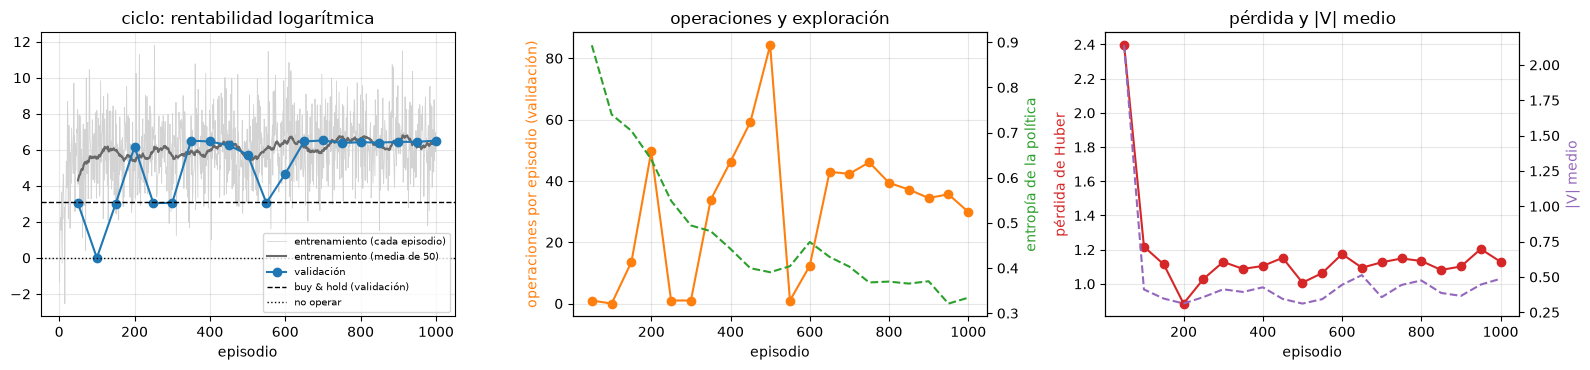

episodio 1000 | entropía de la política 0.33 | entrenamiento +6.508 | validación +6.506 (buy & hold +3.113) | operaciones 29.9 | invertido 58% | pérdida 1.129 | |V| medio 0.49 | 10 s


In [42]:
g = "ciclo"
PRUEBA_A3C[g] = entrenar_o_cargar(
    CARPETA_RESULTADOS / f"prueba_a3c_{g}.pkl",
    lambda: entrenar_a3c(g, NORMALIZACION[g], CONFIG_PRUEBA_A3C, n_episodios=N_EP_PRUEBA_A3C,
                         series_val=SERIES_VAL[g], cada=50, callback=seguimiento(g, REF_VAL[g], **SEGUIMIENTO_A3C)))
seguimiento(g, REF_VAL[g], **SEGUIMIENTO_A3C)(PRUEBA_A3C[g]["curva"], PRUEBA_A3C[g]["ganancias"])

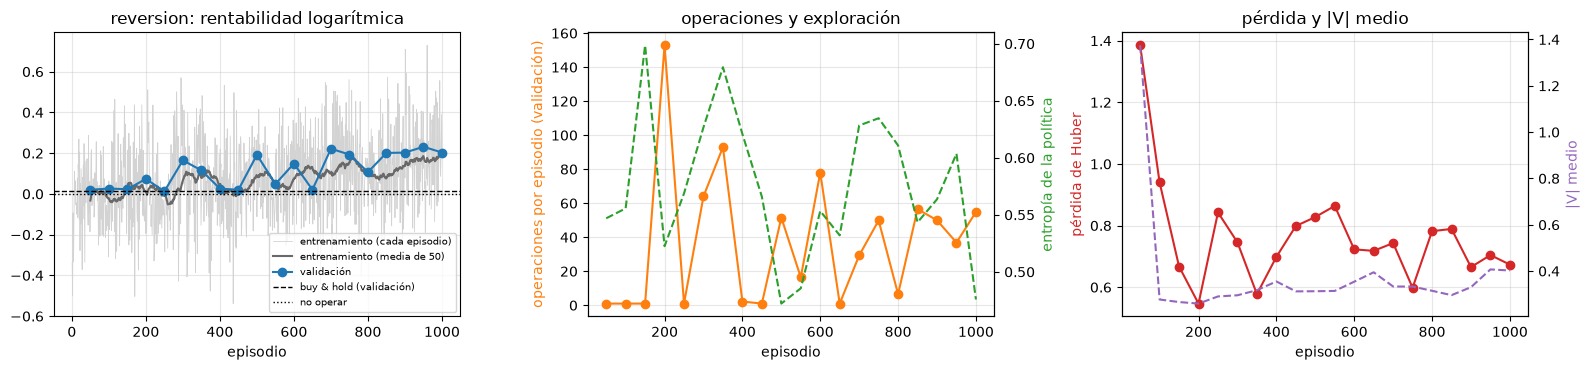

episodio 1000 | entropía de la política 0.48 | entrenamiento +0.192 | validación +0.203 (buy & hold +0.013) | operaciones 54.8 | invertido 61% | pérdida 0.673 | |V| medio 0.40 | 9 s


In [43]:
g = "reversion"
PRUEBA_A3C[g] = entrenar_o_cargar(
    CARPETA_RESULTADOS / f"prueba_a3c_{g}.pkl",
    lambda: entrenar_a3c(g, NORMALIZACION[g], CONFIG_PRUEBA_A3C, n_episodios=N_EP_PRUEBA_A3C,
                         series_val=SERIES_VAL[g], cada=50, callback=seguimiento(g, REF_VAL[g], **SEGUIMIENTO_A3C)))
seguimiento(g, REF_VAL[g], **SEGUIMIENTO_A3C)(PRUEBA_A3C[g]["curva"], PRUEBA_A3C[g]["ganancias"])

In [44]:
filas = []
for g, r in PRUEBA_A3C.items():
    c = r["curva"]
    filas.append({
        "generador": g,
        "buy & hold (val.)": REF_VAL[g],
        "final (val.)": c["ret_log_medio"].iloc[-1],
        "media últimos 5 controles": c["ret_log_medio"].iloc[-5:].mean(),
        "mejor (val.)": c["ret_log_medio"].max(),
        "episodio del mejor": r["mejor_episodio"],
        "operaciones (final)": c["operaciones"].iloc[-1],
        "entropía (final)": c["entropia"].iloc[-1],
        "cambios de política, % (últimos 5)": c["cambios_politica_%"].iloc[-5:].mean(),
        "ms por episodio": 1000 * r["tiempo"] / r["n_episodios"],
        "arranque (s)": r["tiempo_arranque"],
        "divergió": r["divergio"],
    })
pd.DataFrame(filas).set_index("generador").round(3)

,buy & hold (val.),final (val.),media últimos 5 controles,mejor (val.),episodio del mejor,operaciones (final),entropía (final),"cambios de política, % (últimos 5)",ms por episodio,arranque (s),divergió
generador,,,,,,,,,,,
ciclo,3.113,6.506,6.441,6.516,700,29.88,0.334,1.405,9.777,1.410,False
reversion,0.013,0.203,0.189,0.231,950,54.82,0.476,9.339,9.454,1.251,False


#### Política aprendida

Para cada valor de la tendencia: probabilidad de comprar sin activo y de vender con activo. Las bandas marcan dónde la acción más probable cambia de posición, que es lo que hace la política voraz. La entropía máxima, política uniforme, es $\ln 3 \approx 1.10$.

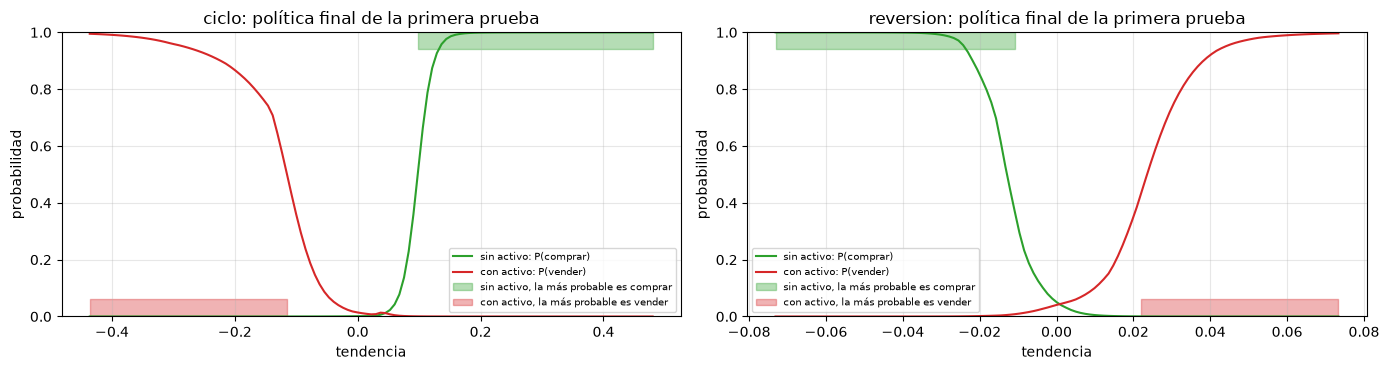

In [45]:
def grafico_politica_a3c(resultados, titulo):
    fig, axes = plt.subplots(1, len(resultados), figsize=(7 * len(resultados), 3.8), squeeze=False)
    for ax, (g, r) in zip(axes[0], resultados.items()):
        red = red_a3c_desde_pesos(r["pesos"], r["config"]["n_ocultas"])
        p_compra, p_venta, compra, venta = politica_en_rejilla(red)
        tendencia = NORMALIZACION[g]["media"] + REJILLA_Z * NORMALIZACION[g]["desv"]  # de vuelta a unidades del entorno

        ax.plot(tendencia, p_compra, color="tab:green", label="sin activo: P(comprar)")
        ax.plot(tendencia, p_venta, color="tab:red", label="con activo: P(vender)")
        ax.fill_between(tendencia, 0.94, 1.0, where=compra, color="tab:green", alpha=0.35,
                        label="sin activo, la más probable es comprar")
        ax.fill_between(tendencia, 0.0, 0.06, where=venta, color="tab:red", alpha=0.35,
                        label="con activo, la más probable es vender")
        ax.set_ylim(0, 1)
        ax.set_title(f"{g}: {titulo}")
        ax.set_xlabel("tendencia")
        ax.set_ylabel("probabilidad")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()


grafico_politica_a3c(PRUEBA_A3C, "política final de la primera prueba")

**Resultado.**

- **Aprende en los dos mercados sin ajustar:** *ciclo* 6.44 en validación (media de los 5 últimos controles; *buy & hold* 3.11; DQN ajustado 6.16), *reversión* 0.19 (*buy & hold* 0.01; DQN ajustado 0.25).
- **La política voraz salta mientras la política es muy estocástica:** con probabilidades parecidas, la acción más probable cambia en tramos enteros de tendencia. En *ciclo*, 7 de los 13 primeros controles caen a mantener siempre o a no operar mientras la política estocástica gana 5.4–6.5 en entrenamiento; desde el episodio 650 se estabiliza. En *reversión*, los saltos duran hasta el episodio 650.
- **Estrategias:** en *ciclo*, seguimiento de tendencia con una banda amplia: compra con tendencia > 0.10 y vende con < −0.12 (el DQN compra desde −0.01/−0.03), con ~35 operaciones por episodio frente a ~55. En *reversión*, compra tras caídas (< −0.011) y vende tras subidas (> 0.022), con umbrales más cercanos a cero que el DQN y más operaciones (~50 frente a ~36).
- **Coste:** 8.3 ms por episodio con 4 trabajadores (DQN: ~51 ms en un proceso), más 1.3 s de arranque.

### Fase 4: Ajuste de hiperparámetros de A3C

Mismo protocolo que el DQN: TPE multivariante, un estudio por mercado, 40 pruebas de 1 000 episodios con las series de la repetición 0, puntuación con los 5 últimos controles y confirmación de las 3 mejores con 3 semillas nuevas.

| Hiperparámetro | Rango |
|---|---|
| $\alpha$ | $10^{-5}$ a $10^{-2}$, escala logarítmica |
| $\gamma$ | a través del horizonte $1/(1-\gamma)$: de 2 a 100 pasos, escala logarítmica |
| β (entropía) | $10^{-4}$ a $10^{-1}$, escala logarítmica |
| $t_{max}$ | 5 o 20 |

- **$\alpha$, más ancho por arriba que en el DQN:** A3C hace ~25 actualizaciones por episodio con $t_{max}$ = 20 (~99 con 5), frente a ~124 del DQN.
- **β ocupa el lugar de la exploración del DQN;** su límite inferior equivale en la práctica a no tener término de entropía.
- **Divergencias:** una prueba que diverge (pérdida no finita o $|V| > 10^4$) puntúa −1, peor que cualquier resultado, aunque se hubiera evaluado antes: su modelo final no sirve, y así TPE aprende a evitar esa zona.
- **$t_{max}$:** con horizontes cortos, 20 reduce el peso del crítico en el retorno sin apenas aumentar la varianza; con horizontes largos, 5 evita multiplicarla por ~3. Como el horizonte se ajusta, $t_{max}$ también.
- **Paralelismo:** 2 entrenamientos a la vez, cada uno con sus 4 trabajadores. Las pruebas se lanzan en hilos del proceso principal, porque cada entrenamiento crea sus propios procesos.

In [46]:
import concurrent.futures as cf

from ajuste import prueba_a3c, confirmar_a3c, puntuacion_resultado

RUTA_OPTUNA_A3C = CARPETA_RESULTADOS / "optuna_a3c.log"
N_PRUEBAS_A3C = 40
N_SIMULTANEAS = 2  # entrenamientos a la vez, cada uno con sus 4 trabajadores

ESTUDIOS_A3C = {g: optuna.create_study(study_name=f"a3c_{g}", storage=almacen(RUTA_OPTUNA_A3C),
                                       direction="maximize", load_if_exists=True) for g in GENERADORES}
for e in ESTUDIOS_A3C.values():
    limpiar_interrumpidas(e)

# Se mantienen N_SIMULTANEAS pruebas en marcha, siempre del mercado al que le faltan más. Si se interrumpe la
# celda, las pruebas en curso terminan (unos segundos) y no se lanzan más; al relanzarla, continúa donde iba.
semilla = sum(len(e.trials) for e in ESTUDIOS_A3C.values())  # semillas del muestreador nuevas también al retomar
t0 = ultimo = time.perf_counter()
with cf.ThreadPoolExecutor(N_SIMULTANEAS) as hilos:
    en_marcha = []  # (mercado, resultado pendiente)
    while True:
        while len(en_marcha) < N_SIMULTANEAS:
            faltan = {g: N_PRUEBAS_A3C - len(terminadas(ESTUDIOS_A3C[g])) - sum(m == g for m, _ in en_marcha)
                      for g in GENERADORES}
            g = max(faltan, key=faltan.get)
            if faltan[g] <= 0:
                break
            en_marcha.append((g, hilos.submit(prueba_a3c, g, RUTA_OPTUNA_A3C, semilla)))
            semilla += 1
        if not en_marcha:
            break
        time.sleep(1)
        for tarea in [x for x in en_marcha if x[1].done()]:
            tarea[1].result()  # si una prueba ha fallado, su error aparece aquí
            en_marcha.remove(tarea)
        if time.perf_counter() - ultimo > 30:
            ultimo = time.perf_counter()
            clear_output(wait=True)
            print(f"Búsqueda en marcha: {(ultimo - t0) / 60:.1f} min")
            display(progreso(ESTUDIOS_A3C))

clear_output(wait=True)
print(f"Búsqueda terminada en {(time.perf_counter() - t0) / 60:.1f} min")
progreso(ESTUDIOS_A3C)

Búsqueda terminada en 0.0 min


,pruebas terminadas,mejor puntuación
mercado,,
ciclo,40,6.066
browniano,40,0.000
reversion,40,0.220
regimenes,40,0.007


In [47]:
def config_a3c_de(t):
    return {"lr": t.params["lr"], "gamma": 1 - 1 / t.params["horizonte"], "beta": t.params["beta"],
            "t_max": t.params["t_max"]}


filas = []
for g, e in ESTUDIOS_A3C.items():
    hechas = terminadas(e)
    mejor = max(hechas, key=lambda t: t.value)
    filas.append({"mercado": g, "pruebas": len(hechas),
                  "divergidas": sum(t.user_attrs["divergio"] for t in hechas),
                  "mejor puntuación": mejor.value, "buy & hold (val.)": REF_VAL[g],
                  "α": f"{mejor.params['lr']:.1e}", "γ": config_a3c_de(mejor)["gamma"],
                  "horizonte (pasos)": mejor.params["horizonte"], "β": f"{mejor.params['beta']:.1e}",
                  "t_max": mejor.params["t_max"],
                  "segundos por prueba (mediana)": np.median([t.user_attrs["tiempo_s"] for t in hechas])})
pd.DataFrame(filas).set_index("mercado").round(3)

,pruebas,divergidas,mejor puntuación,buy & hold (val.),α,γ,horizonte (pasos),β,t_max,segundos por prueba (mediana)
mercado,,,,,,,,,,
ciclo,40,0,6.066,3.113,3.7e-04,0.791,4.791,4.5e-03,20,17.075
browniano,40,1,0.000,-0.110,4.1e-03,0.790,4.766,4.2e-04,5,17.127
reversion,40,1,0.220,0.013,8.7e-05,0.803,5.083,8.5e-02,20,17.531
regimenes,40,0,0.007,-0.212,1.9e-05,0.559,2.268,4.2e-03,5,32.615


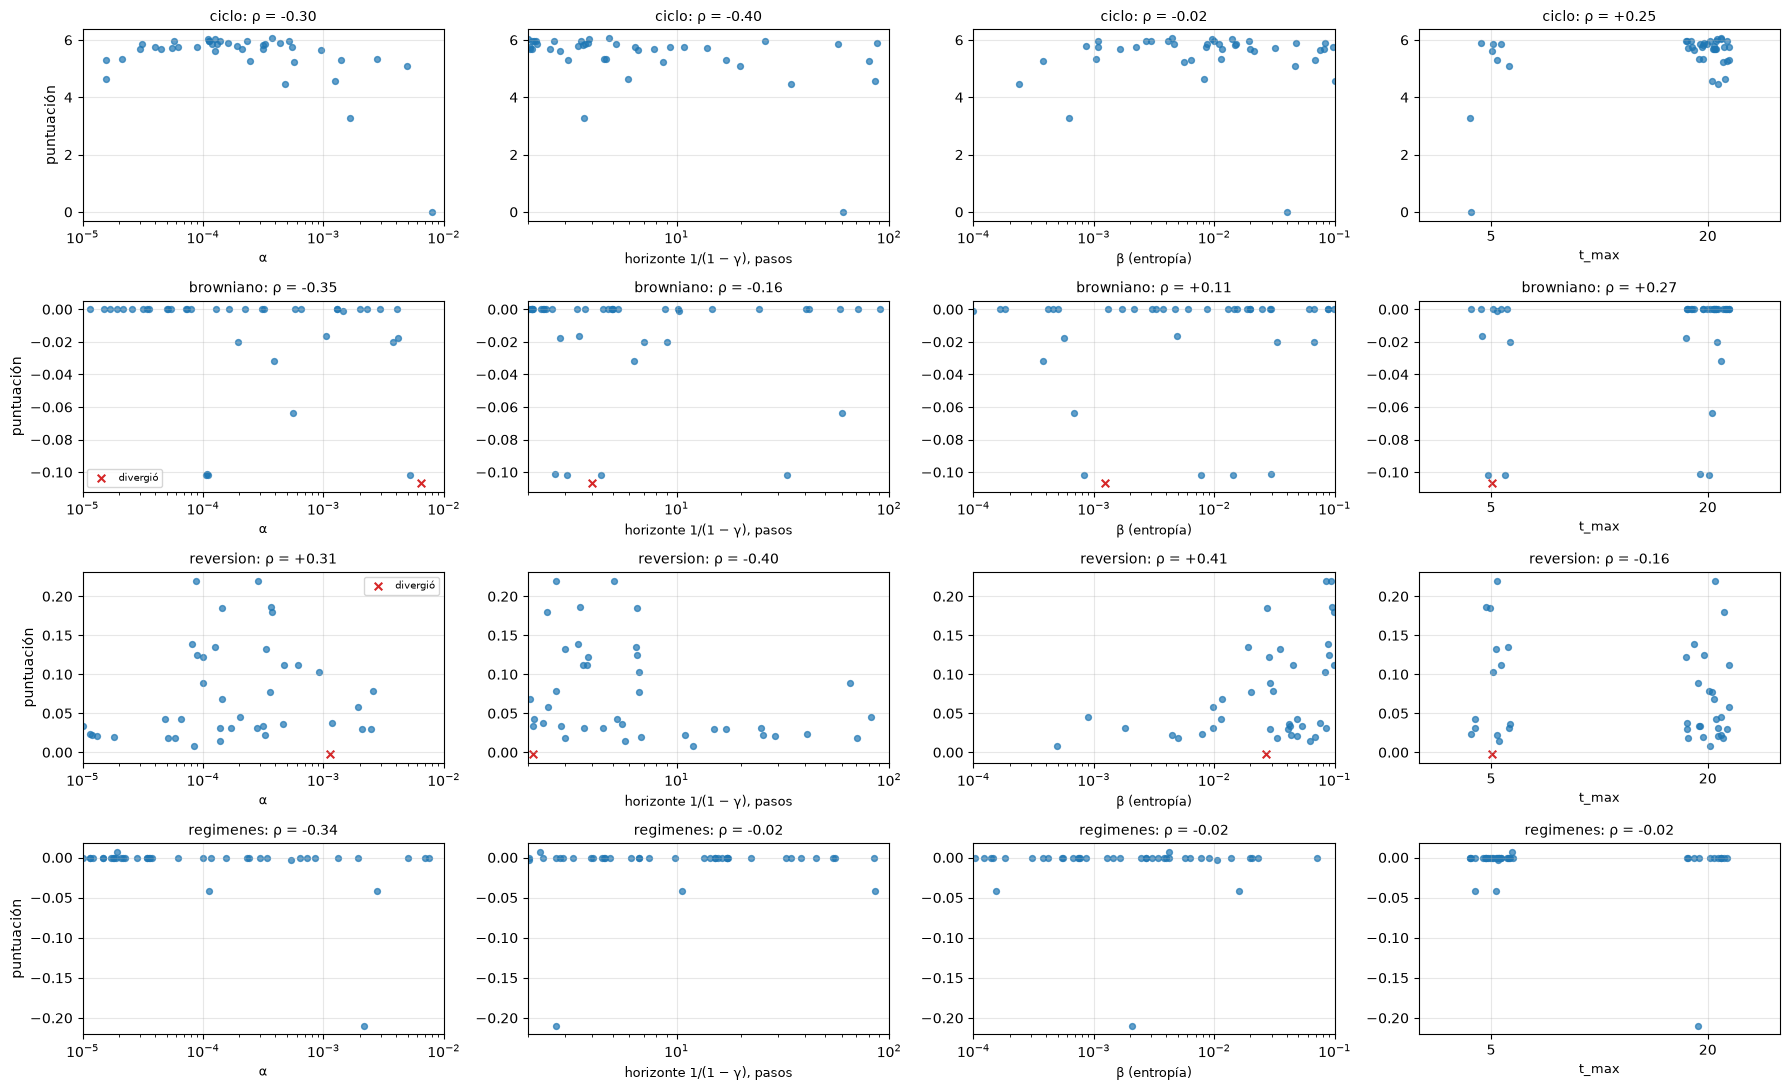

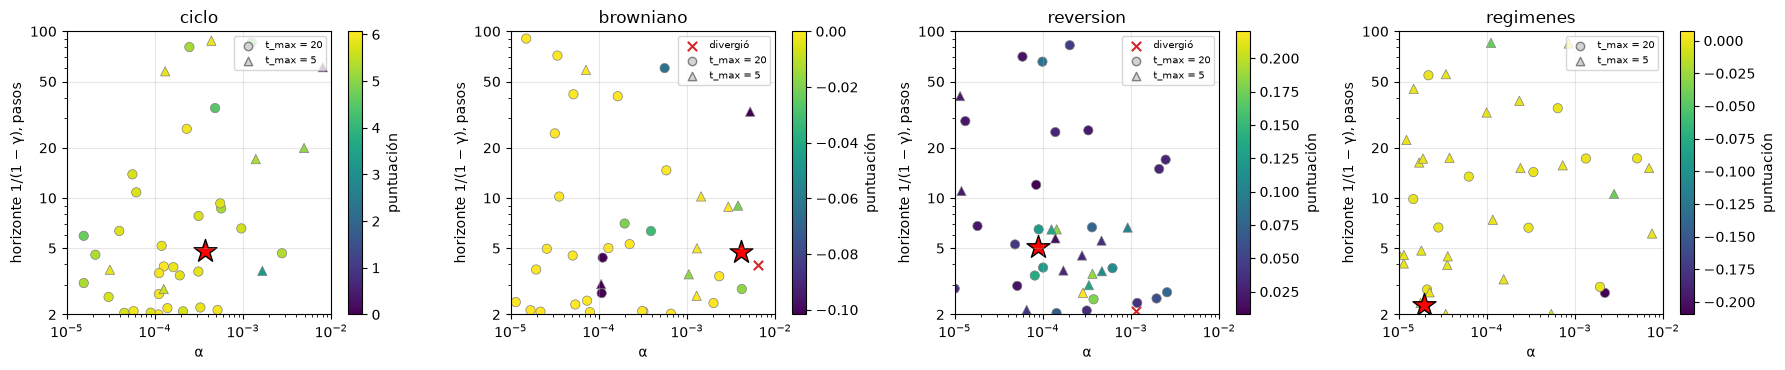

In [48]:
# Puntuación de cada prueba frente a cada hiperparámetro, con la correlación de rangos ρ de Spearman.
# Las pruebas que divergen (puntuación -1) se marcan con una x roja en el borde inferior y no entran en ρ.
# t_max solo toma dos valores: los puntos se separan un poco en horizontal para que no se tapen
RANGOS_A3C = {"lr": ("α", (1e-5, 1e-2)), "horizonte": ("horizonte 1/(1 − γ), pasos", (2, 100)),
              "beta": ("β (entropía)", (1e-4, 1e-1)), "t_max": ("t_max", (0, 25))}


def rho_spearman(x, y):
    # Correlación de Pearson entre los rangos; no está definida si una de las dos variables es constante
    return x.rank().corr(y.rank()) if x.nunique() > 1 and y.nunique() > 1 else np.nan


def separar_divergidas(estudio):
    hechas = terminadas(estudio)
    return ([t for t in hechas if not t.user_attrs["divergio"]], [t for t in hechas if t.user_attrs["divergio"]])


fig, axes = plt.subplots(len(ESTUDIOS_A3C), len(RANGOS_A3C), figsize=(18, 11))
for fila, (g, e) in zip(axes, ESTUDIOS_A3C.items()):
    validas, divergidas = separar_divergidas(e)
    puntos = pd.Series([t.value for t in validas])
    suelo = puntos.min() - 0.05 * (puntos.max() - puntos.min() + 1e-9)  # altura de las x de las divergidas
    for ax, (p, (etiqueta, rango)) in zip(fila, RANGOS_A3C.items()):
        x = pd.Series([float(t.params[p]) for t in validas])
        x_div = np.array([float(t.params[p]) for t in divergidas])
        rho = rho_spearman(x, puntos)
        if p == "t_max":
            x = x + np.random.default_rng(0).uniform(-1.5, 1.5, len(x))
            x_div = x_div + np.random.default_rng(1).uniform(-1.5, 1.5, len(x_div))
            ax.set_xticks([5, 20])
        else:
            ax.set_xscale("log")
        ax.scatter(x, puntos, s=18, color="tab:blue", alpha=0.7)
        if len(divergidas):
            ax.scatter(x_div, np.full(len(x_div), suelo), marker="x", s=30, color="tab:red", label="divergió")
            if p == "lr":
                ax.legend(fontsize=7)
        ax.set_xlim(*rango)
        ax.set_title(f"{g}: ρ = {rho:+.2f}" if np.isfinite(rho) else f"{g}: ρ no definida", fontsize=10)
        ax.set_xlabel(etiqueta, fontsize=9)
        ax.grid(alpha=0.3)
    fila[0].set_ylabel("puntuación")
plt.tight_layout()
plt.show()

# Combinaciones α × horizonte, coloreadas por puntuación; círculo: t_max = 20, triángulo: t_max = 5; x roja: divergió;
# estrella: la mejor
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (g, e) in zip(axes, ESTUDIOS_A3C.items()):
    hechas, divergidas = separar_divergidas(e)
    valores = [t.value for t in hechas]
    escala = plt.Normalize(min(valores), max(valores))
    if divergidas:
        ax.scatter([t.params["lr"] for t in divergidas], [t.params["horizonte"] for t in divergidas],
                   marker="x", s=45, color="tab:red", label="divergió")
    for t_max, marcador in ((20, "o"), (5, "^")):
        grupo = [t for t in hechas if t.params["t_max"] == t_max]
        ax.scatter([t.params["lr"] for t in grupo], [t.params["horizonte"] for t in grupo],
                   c=[t.value for t in grupo], cmap="viridis", norm=escala, marker=marcador, s=45,
                   edgecolor="gray", linewidth=0.5)
        ax.scatter([], [], marker=marcador, color="lightgray", edgecolor="gray", label=f"t_max = {t_max}")  # leyenda
    mejor = max(hechas, key=lambda t: t.value)
    ax.scatter(mejor.params["lr"], mejor.params["horizonte"], marker="*", s=300, color="red", edgecolor="black")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1e-5, 1e-2)
    ax.set_ylim(2, 100)
    ax.set_yticks([2, 5, 10, 20, 50, 100], ["2", "5", "10", "20", "50", "100"])
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("α")
    ax.set_ylabel("horizonte 1/(1 − γ), pasos")
    ax.set_title(g)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")
    plt.colorbar(plt.cm.ScalarMappable(norm=escala, cmap="viridis"), ax=ax, label="puntuación")
plt.tight_layout()
plt.show()

#### Confirmación

Igual que en el DQN: las 3 mejores configuraciones de cada mercado se repiten con las semillas 1, 2 y 3 y se elige la de mejor media. En A3C la confirmación pesa más: al ser asíncrono, dos ejecuciones con la misma semilla tampoco coinciden.

In [49]:
CANDIDATAS_A3C = {g: sorted(terminadas(e), key=lambda t: t.value, reverse=True)[:N_MEJORES]
                  for g, e in ESTUDIOS_A3C.items()}
tareas = {(g, t.number, rep): config_a3c_de(t)
          for g, ts in CANDIDATAS_A3C.items() for t in ts for rep in REPS_CONFIRMACION}

t0 = time.perf_counter()
with cf.ThreadPoolExecutor(N_SIMULTANEAS) as hilos:
    pendientes = {(g, n, rep): hilos.submit(
                      confirmar_a3c, g, config, rep, CARPETA_RESULTADOS / f"confirmacion_a3c_{g}_p{n}_r{rep}.pkl")
                  for (g, n, rep), config in tareas.items()}
    while not all(f.done() for f in pendientes.values()):
        time.sleep(5)
        clear_output(wait=True)
        print(f"Confirmación en marcha: {sum(f.done() for f in pendientes.values())}/{len(pendientes)} "
              f"entrenamientos, {(time.perf_counter() - t0) / 60:.1f} min")
    CONFIRMACION_A3C = {k: f.result() for k, f in pendientes.items()}

clear_output(wait=True)
print(f"Confirmación terminada en {(time.perf_counter() - t0) / 60:.1f} min")

Confirmación terminada en 0.1 min


In [50]:
filas = []
for g, ts in CANDIDATAS_A3C.items():
    for t in ts:
        resultados = [CONFIRMACION_A3C[(g, t.number, rep)] for rep in REPS_CONFIRMACION]
        puntos = [puntuacion_resultado(r) for r in resultados]  # -1 si la ejecución divergió
        entropias = [r["curva"]["entropia"].iloc[-1] for r in resultados if not r["divergio"]]
        filas.append({"mercado": g, "prueba": t.number, **config_a3c_de(t),
                      "puntuación en la búsqueda": t.value,
                      "media con 3 semillas nuevas": np.mean(puntos), "desv. entre semillas": np.std(puntos),
                      "divergencias": sum(r["divergio"] for r in resultados),
                      "entropía final (media)": np.mean(entropias) if entropias else np.nan})
TABLA_CONFIRMACION_A3C = pd.DataFrame(filas)

# Configuración elegida en cada mercado: la de mejor media con las semillas nuevas
ELEGIDAS_A3C = TABLA_CONFIRMACION_A3C.loc[
    TABLA_CONFIRMACION_A3C.groupby("mercado", sort=False)["media con 3 semillas nuevas"].idxmax()]
CONFIG_A3C_ELEGIDA = {f["mercado"]: {"lr": float(f["lr"]), "gamma": float(f["gamma"]), "beta": float(f["beta"]),
                                     "t_max": int(f["t_max"])} for _, f in ELEGIDAS_A3C.iterrows()}
with open(CARPETA_RESULTADOS / "config_a3c_elegida.json", "w") as fichero:
    json.dump(CONFIG_A3C_ELEGIDA, fichero, indent=1)

TABLA_CONFIRMACION_A3C["elegida"] = TABLA_CONFIRMACION_A3C.index.isin(ELEGIDAS_A3C.index)
for columna in ("lr", "beta"):
    TABLA_CONFIRMACION_A3C[columna] = TABLA_CONFIRMACION_A3C[columna].map("{:.1e}".format)
TABLA_CONFIRMACION_A3C.rename(columns={"lr": "α", "gamma": "γ", "beta": "β"}).set_index(["mercado", "prueba"]).round(3)

α      γ        β  t_max  puntuación en la búsqueda  \
mercado   prueba                                                              
ciclo     4       3.7e-04  0.791  4.5e-03     20                      6.066   
          10      1.3e-04  0.743  9.6e-03     20                      6.044   
          33      1.1e-04  0.500  1.4e-02     20                      6.023   
browniano 1       4.1e-03  0.790  4.2e-04      5                      0.000   
          2       3.2e-04  0.520  3.1e-03     20                      0.000   
          3       5.2e-05  0.976  3.0e-02     20                      0.000   
reversion 23      8.7e-05  0.803  8.5e-02     20                      0.220   
          24      2.9e-04  0.630  9.3e-02      5                      0.219   
          33      3.7e-04  0.715  9.5e-02      5                      0.187   
regimenes 27      1.9e-05  0.559  4.2e-03      5                      0.007   
          0       1.3e-03  0.942  7.5e-04     20                      0.000   
          2       1.1e-05  0.753  2.5e-03      5                      0.000   

                  media con 3 semillas nuevas  desv. entre semillas  \
mercado   prueba                                                      
ciclo     4                             5.768                 0.071   
          10                            4.361                 2.235   
          33                            5.547                 0.524   
browniano 1                            -0.048                 0.035   
          2                            -0.012                 0.017   
          3                             0.000                 0.000   
reversion 23                            0.145                 0.045   
          24                           -0.212                 0.558   
          33                            0.137                 0.046   
regimenes 27                            0.000                 0.000   
          0                             0.000                 0.000   
          2                             0.000                 0.000   

                  divergencias  entropía final (media)  elegida  
mercado   prueba                                                 
ciclo     4                  0                   0.357     True  
          10                 0                   0.592    False  
          33                 0                   0.687    False  
browniano 1                  0                   0.017    False  
          2                  0                   0.421    False  
          3                  0                   1.048     True  
reversion 23                 0                   1.016     True  
          24                 1                   0.952    False  
          33                 0                   1.016    False  
regimenes 27                 0                   0.900     True  
          0                  0                   0.631    False  
          2                  0                   1.038    False

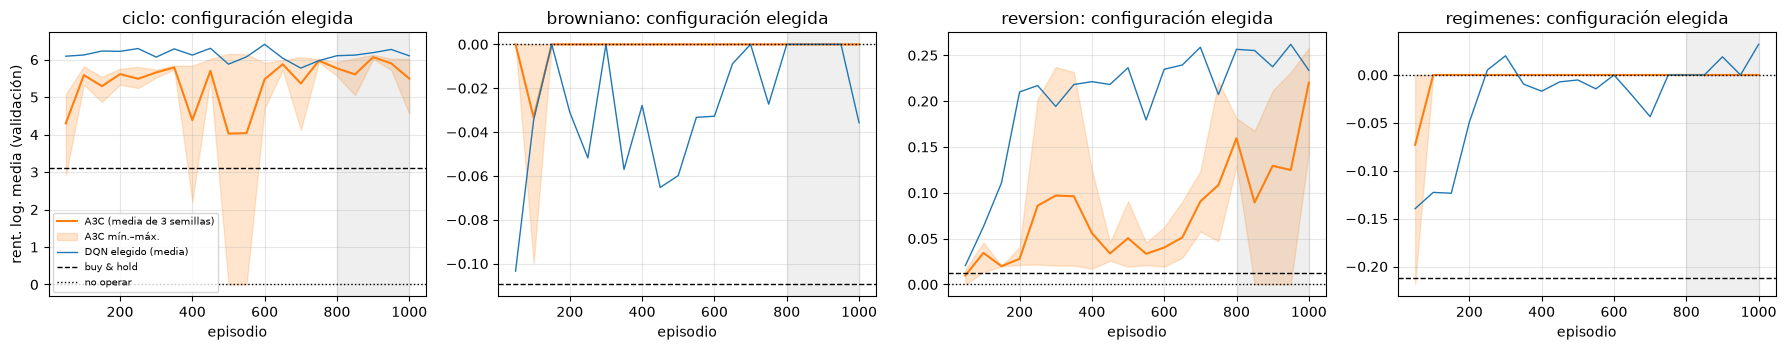

In [51]:
# Validación de la configuración elegida con las 3 semillas nuevas, junto a la del DQN elegido; en gris, los
# controles que puntúan
def matriz_curvas(resultados):
    # Curvas de validación de varias ejecuciones; las que se cortaron al divergir se completan con NaN
    n = max(len(r["curva"]) for r in resultados)
    curvas = np.array([np.pad(r["curva"]["ret_log_medio"].to_numpy(float), (0, n - len(r["curva"])),
                              constant_values=np.nan) for r in resultados])
    episodios = max((r["curva"]["episodio"] for r in resultados), key=len)
    return episodios, curvas


fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, (_, f) in zip(axes, ELEGIDAS_A3C.iterrows()):
    g, n = f["mercado"], f["prueba"]
    episodios, curvas = matriz_curvas([CONFIRMACION_A3C[(g, n, rep)] for rep in REPS_CONFIRMACION])
    episodios_dqn, curvas_dqn = matriz_curvas([CONFIRMACION[(g, PRUEBA_ELEGIDA[g], rep)] for rep in REPS_CONFIRMACION])
    ax.plot(episodios, np.nanmean(curvas, 0), color="tab:orange", label="A3C (media de 3 semillas)")
    ax.fill_between(episodios, np.nanmin(curvas, 0), np.nanmax(curvas, 0), color="tab:orange", alpha=0.2,
                    label="A3C mín.–máx.")
    ax.plot(episodios_dqn, np.nanmean(curvas_dqn, 0), color="tab:blue", linewidth=1, label="DQN elegido (media)")
    ax.axvspan(episodios.iloc[-min(N_CONTROLES, len(episodios))], episodios.iloc[-1], color="gray", alpha=0.12)
    valores = np.concatenate([curvas.ravel(), curvas_dqn.ravel()])
    valores = valores[np.isfinite(valores)]
    linea_referencia(ax, REF_VAL[g], valores, color="black", linestyle="--", linewidth=1, label="buy & hold")
    linea_referencia(ax, 0, valores, color="black", linestyle=":", linewidth=1, label="no operar")
    ax.set_title(f"{g}: configuración elegida")
    ax.set_xlabel("episodio")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("rent. log. media (validación)")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Resultado.**

- **Búsqueda:** 160 pruebas en 30 min. Divergen 2, y 1 de las 36 ejecuciones de la confirmación, todas con $t_{max}$ = 5 y en los primeros episodios ($|V| > 10^4$): con 5 pasos hay 4 veces más actualizaciones asíncronas sobre la red compartida. TPE prefirió $t_{max}$ = 20 en los tres mercados con señal; además, 5 duplica el tiempo (~34 s frente a ~17 s por prueba).
- **Validación con 3 semillas:** *ciclo* 5.77 ± 0.07 (DQN 6.16), *browniano* 0.00 (−0.01), *reversión* 0.15 ± 0.05 (0.25), *regímenes* 0.00 (0.01). El DQN gana donde hay señal; donde no la hay, los dos dejan de operar.
- **Política voraz inestable:** en *ciclo*, 2 de las 9 ejecuciones de confirmación dejan de operar en algún control de los que puntúan. En *reversión*, *browniano* y *regímenes* la política acaba casi uniforme (entropía ≈ 1.0; máximo 1.10) y la acción más probable depende de diferencias pequeñas.
- **Qué importa:** horizontes cortos en *ciclo* y *reversión* ($\rho$ = −0.40), como en el DQN. En *reversión*, β alto ($\rho$ = +0.41; 4 de las 5 mejores entre 0.085 y 0.1, en el borde del rango) y $\alpha$ mayor que en el DQN ($\rho$ = +0.31), porque A3C hace menos actualizaciones por episodio.
- ***Regímenes*, horizontes largos:** A3C no pierde (0.00, sin operar) donde el DQN perdía de −0.12 a −0.17 por sobreestimación: sin el máximo en el objetivo no hay sobreinversión. Tampoco encuentra la estrategia de la parte 1.

### Fase 5: Convergencia y test

Mismo protocolo que la parte 1, para comparar directamente con Q-Learning y Sarsa:

- **Entrenamientos:** configuración elegida de cada algoritmo y mercado, 5 semillas nuevas (10–14), 5 000 episodios, validación cada 100.
- **Episodios hasta converger:** primer episodio a partir del cual la curva de validación suavizada (media móvil de 5 controles) ya no baja del 90% de su mejora total; media ± desviación entre semillas.
- **Test:** modelo final de cada semilla con su política voraz en las 200 series de test; media ± desviación entre semillas. Aleatorio y *buy & hold* en las mismas series; Q-Learning y Sarsa, con la tabla de test de la parte 1.
- **Exploración del DQN en episodios absolutos:** ε llega a 0.01 en el mismo episodio que en el ajuste (la fracción se divide entre 5). Con la fracción original duraría 5 veces más que la ajustada.
- **Tiempo:** ms por episodio medidos aparte, con un solo entrenamiento en marcha y sin evaluaciones: el DQN en un proceso; A3C con sus 4 trabajadores, más el arranque. Tiempo hasta converger = episodios hasta converger × ms por episodio.

In [52]:
from final import (N_EPISODIOS_FINAL, REPS_FINAL, config_final_dqn, entrenar_final, episodio_convergencia,
                   medir_tiempo, evaluar_test)

CONFIGS_FINALES = {"dqn": {g: config_final_dqn(c) for g, c in CONFIG_DQN_ELEGIDA.items()},
                   "a3c": dict(CONFIG_A3C_ELEGIDA)}
ALGORITMOS = {"dqn": "DQN", "a3c": "A3C"}

pd.DataFrame({(ALGORITMOS[alg], g): c for alg, cs in CONFIGS_FINALES.items() for g, c in cs.items()}).T \
    .rename(columns={"lr": "α", "gamma": "γ", "frac_exploracion": "exploración (fracción de 5 000)", "beta": "β"})

α         γ  exploración (fracción de 5 000)         β  \
DQN ciclo      0.000136  0.910280                         0.094434       NaN   
    browniano  0.000010  0.565590                         0.041454       NaN   
    reversion  0.000011  0.785117                         0.094189       NaN   
    regimenes  0.000013  0.534912                         0.058820       NaN   
A3C ciclo      0.000371  0.791260                              NaN  0.004489   
    browniano  0.000052  0.976140                              NaN  0.029705   
    reversion  0.000087  0.803264                              NaN  0.085117   
    regimenes  0.000019  0.559004                              NaN  0.004246   

               t_max  
DQN ciclo        NaN  
    browniano    NaN  
    reversion    NaN  
    regimenes    NaN  
A3C ciclo       20.0  
    browniano   20.0  
    reversion   20.0  
    regimenes    5.0

#### Entrenamientos

Primero el DQN, 8 entrenamientos a la vez; después A3C, 2 a la vez con sus 4 trabajadores. Cada entrenamiento se guarda en `resultados/`; si se interrumpe la celda, al relanzarla solo se repiten los que faltan.

In [53]:
FINALES = {}

t0 = time.perf_counter()
with mp.get_context("spawn").Pool(N_PROCESOS) as pool:
    pendientes = {("dqn", g, rep): pool.apply_async(
                      entrenar_final, ("dqn", g, CONFIGS_FINALES["dqn"][g], rep,
                                       CARPETA_RESULTADOS / f"final_dqn_{g}_r{rep}.pkl"))
                  for g in GENERADORES for rep in REPS_FINAL}
    while not all(r.ready() for r in pendientes.values()):
        time.sleep(10)
        clear_output(wait=True)
        print(f"DQN: {sum(r.ready() for r in pendientes.values())}/{len(pendientes)} entrenamientos, "
              f"{(time.perf_counter() - t0) / 60:.1f} min")
    FINALES.update({k: r.get() for k, r in pendientes.items()})

clear_output(wait=True)
print(f"DQN terminado en {(time.perf_counter() - t0) / 60:.1f} min")

DQN terminado en 0.2 min


In [54]:
t0 = time.perf_counter()
with cf.ThreadPoolExecutor(N_SIMULTANEAS) as hilos:
    pendientes = {("a3c", g, rep): hilos.submit(
                      entrenar_final, "a3c", g, CONFIGS_FINALES["a3c"][g], rep,
                      CARPETA_RESULTADOS / f"final_a3c_{g}_r{rep}.pkl")
                  for g in GENERADORES for rep in REPS_FINAL}
    while not all(f.done() for f in pendientes.values()):
        time.sleep(5)
        clear_output(wait=True)
        print(f"A3C: {sum(f.done() for f in pendientes.values())}/{len(pendientes)} entrenamientos, "
              f"{(time.perf_counter() - t0) / 60:.1f} min")
    FINALES.update({k: f.result() for k, f in pendientes.items()})

clear_output(wait=True)
print(f"A3C terminado en {(time.perf_counter() - t0) / 60:.1f} min")

A3C terminado en 0.1 min


#### Convergencia

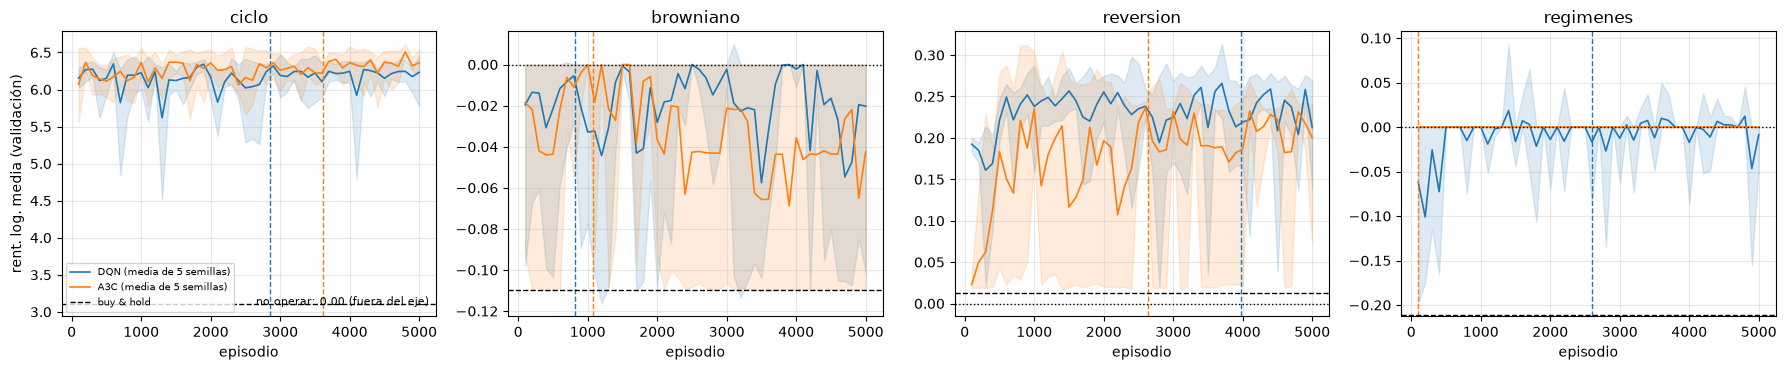

,,episodios_media,episodios_desv,divergencias
mercado,algoritmo,,,
ciclo,DQN,2860.0,2546.0,0
browniano,DQN,820.0,1610.0,0
reversion,DQN,3980.0,1069.0,0
regimenes,DQN,2600.0,2358.0,0
ciclo,A3C,3620.0,2004.0,0
browniano,A3C,1080.0,2191.0,0
reversion,A3C,2640.0,1250.0,0
regimenes,A3C,100.0,0.0,0


In [55]:
filas = []
for (alg, g, rep), r in FINALES.items():
    # Un entrenamiento que diverge no converge: su curva está cortada
    filas.append({"algoritmo": ALGORITMOS[alg], "mercado": g, "semilla": rep, "divergió": r["divergio"],
                  "episodio de convergencia": np.nan if r["divergio"] else episodio_convergencia(r["curva"])})
CONVERGENCIA = pd.DataFrame(filas)

# Validación de las 5 semillas (media y mín.–máx.); la línea vertical marca el episodio medio de convergencia
COLORES = {"DQN": "tab:blue", "A3C": "tab:orange"}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, g in zip(axes, GENERADORES):
    valores = []
    for alg, nombre in ALGORITMOS.items():
        episodios, curvas = matriz_curvas([FINALES[(alg, g, rep)] for rep in REPS_FINAL])
        media = np.nanmean(curvas, 0)
        ax.plot(episodios, media, color=COLORES[nombre], linewidth=1.2, label=f"{nombre} (media de 5 semillas)")
        ax.fill_between(episodios, np.nanmin(curvas, 0), np.nanmax(curvas, 0), color=COLORES[nombre], alpha=0.15)
        conv = CONVERGENCIA.query("algoritmo == @nombre and mercado == @g")["episodio de convergencia"].mean()
        ax.axvline(conv, color=COLORES[nombre], linestyle="--", linewidth=1)
        valores.append(curvas[np.isfinite(curvas)])
    valores = np.concatenate(valores)
    linea_referencia(ax, REF_VAL[g], valores, color="black", linestyle="--", linewidth=1, label="buy & hold")
    linea_referencia(ax, 0, valores, color="black", linestyle=":", linewidth=1, label="no operar")
    ax.set_title(g)
    ax.set_xlabel("episodio")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("rent. log. media (validación)")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

CONVERGENCIA.groupby(["mercado", "algoritmo"], sort=False).agg(
    episodios_media=("episodio de convergencia", "mean"), episodios_desv=("episodio de convergencia", "std"),
    divergencias=("divergió", "sum")).round(0)

El criterio del 90% es inestable cuando la curva es plana casi desde el principio o tiene caídas tardías: la mejora total es pequeña y cualquier oscilación retrasa el episodio de convergencia. La validación por tramos de episodios muestra la dinámica sin depender de ese umbral.

In [56]:
# Validación media de las 5 semillas por tramos de episodios
TRAMOS = [(0, 500), (500, 1000), (1000, 2000), (2000, 3000), (3000, 4000), (4000, 5000)]
filas = []
for (alg, g, rep), r in FINALES.items():
    c = r["curva"]
    filas.append({"mercado": g, "algoritmo": ALGORITMOS[alg],
                  **{f"{a}–{b}": c.loc[(c["episodio"] > a) & (c["episodio"] <= b), "ret_log_medio"].mean()
                     for a, b in TRAMOS}})
TABLA_TRAMOS = pd.DataFrame(filas).groupby(["mercado", "algoritmo"]).mean()
TABLA_TRAMOS.loc[[(g, a) for g in GENERADORES for a in ALGORITMOS.values()]].round(3)

0–500  500–1000  1000–2000  2000–3000  3000–4000  \
mercado   algoritmo                                                     
ciclo     DQN        6.194     6.156      6.126      6.115      6.209   
          A3C        6.177     6.213      6.274      6.244      6.298   
browniano DQN       -0.020    -0.016     -0.024     -0.009     -0.019   
          A3C       -0.034    -0.009     -0.016     -0.038     -0.046   
reversion DQN        0.186     0.240      0.242      0.230      0.238   
          A3C        0.086     0.186      0.171      0.185      0.192   
regimenes DQN       -0.052    -0.003     -0.004     -0.007     -0.001   
          A3C        0.000     0.000      0.000      0.000      0.000   

                     4000–5000  
mercado   algoritmo             
ciclo     DQN            6.193  
          A3C            6.348  
browniano DQN           -0.025  
          A3C           -0.042  
reversion DQN            0.234  
          A3C            0.212  
regimenes DQN           -0.005  
          A3C            0.000

#### Tiempo por episodio

Se mide aparte (500 episodios, sin evaluaciones), con un solo entrenamiento en marcha. Se guarda en `resultados/tiempos.json`; para medirlo de nuevo hay que borrar el fichero.

In [57]:
RUTA_TIEMPOS = CARPETA_RESULTADOS / "tiempos.json"
if RUTA_TIEMPOS.exists():
    with open(RUTA_TIEMPOS) as fichero:
        TIEMPOS = json.load(fichero)
else:
    TIEMPOS = {alg: {g: medir_tiempo(alg, g, CONFIGS_FINALES[alg][g]) for g in GENERADORES} for alg in ALGORITMOS}
    with open(RUTA_TIEMPOS, "w") as fichero:
        json.dump(TIEMPOS, fichero, indent=1)

# A3C usa 4 procesos: su tiempo de CPU por episodio es aproximadamente 4 veces el de reloj
pd.DataFrame({(ALGORITMOS[alg], g): {**t, "ms de CPU por episodio (aprox.)":
                                     t["ms_por_episodio"] * (CONFIG_A3C["n_trabajadores"] if alg == "a3c" else 1)}
              for alg, ts in TIEMPOS.items() for g, t in ts.items()}).T.round(2)

ms_por_episodio  arranque_s  ms de CPU por episodio (aprox.)
DQN ciclo                48.99        0.00                            48.99
    browniano            48.60        0.00                            48.60
    reversion            50.65        0.00                            50.65
    regimenes            48.72        0.00                            48.72
A3C ciclo                 8.95        1.20                            35.79
    browniano             9.42        1.27                            37.68
    reversion             9.71        1.28                            38.85
    regimenes            20.22        1.30                            80.87

#### Test

Antes, se comprueba que aleatorio y *buy & hold* dan en test exactamente lo mismo que en la parte 1: son las mismas 200 series.

In [58]:
PARTE1_TEST = pd.DataFrame(
    [("ciclo", "Aleatorio", 4943, 1.626), ("ciclo", "Buy & hold", 25318, 3.325),
     ("browniano", "Aleatorio", 810, -0.169), ("browniano", "Buy & hold", 931, -0.061),
     ("reversion", "Aleatorio", 910, -0.121), ("reversion", "Buy & hold", 989, -0.012),
     ("regimenes", "Aleatorio", 800, -0.256), ("regimenes", "Buy & hold", 869, -0.182)],
    columns=["mercado", "agente", "balance_mediana", "ret_log_medio"]).set_index(["mercado", "agente"])

filas = []
for g in GENERADORES:
    referencias = {"Aleatorio": evaluar(politica_aleatoria, SERIES_TEST[g], semilla=SEMILLA_TEST),
                   "Buy & hold": evaluar(politica_buy_and_hold, SERIES_TEST[g])}
    for agente, res in referencias.items():
        filas.append({"mercado": g, "agente": agente, **{k: v for k, v in res.items() if k != "finales"}})
BASELINES_TEST = pd.DataFrame(filas).set_index(["mercado", "agente"])

assert (BASELINES_TEST["balance_mediana"].round(0) == PARTE1_TEST["balance_mediana"]).all()
assert (BASELINES_TEST["ret_log_medio"].round(3) == PARTE1_TEST["ret_log_medio"]).all()
print("Baselines en test idénticos a los de la parte 1")

# Modelo final de cada semilla en las 200 series de test
filas = []
for (alg, g, rep), r in FINALES.items():
    res = evaluar_test(alg, r, g, SERIES_TEST[g])
    filas.append({"algoritmo": ALGORITMOS[alg], "mercado": g, "semilla": rep, "divergió": r["divergio"],
                  **{k: v for k, v in res.items() if k != "finales"}})
TEST = pd.DataFrame(filas)
TEST.pivot_table(index="mercado", columns=["algoritmo", "semilla"], values="ret_log_medio", sort=False).round(3)

Baselines en test idénticos a los de la parte 1


algoritmo    DQN                                A3C                       \
semilla       10     11     12     13     14     10     11     12     13   
mercado                                                                    
ciclo      6.076  5.807  6.103  6.180  6.272  6.235  6.152  6.279  6.410   
browniano  0.000  0.000  0.000  0.000 -0.063  0.000 -0.056  0.000  0.000   
reversion  0.145  0.193  0.215  0.187  0.112  0.045  0.206  0.194  0.178   
regimenes -0.071  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000   

algoritmo         
semilla       14  
mercado           
ciclo      6.287  
browniano -0.051  
reversion  0.166  
regimenes  0.000

#### Tabla comparativa

Rentabilidad logarítmica media en las 200 series de test. DQN y A3C: media de las 5 semillas (y su desviación); el resto de columnas, también medias de las 5 semillas. Q-Learning y Sarsa: tabla de test de la parte 1, con ~14 ms por episodio.

In [59]:
PARTE1_TABULAR = pd.DataFrame(
    [("ciclo", "Q-Learning", 533577, 6.239, 96, 49, 54, 3480, 1446),
     ("ciclo", "Sarsa", 548471, 6.254, 96, 47, 52, 4540, 383),
     ("browniano", "Q-Learning", 1000, 0.000, 56, 0, 0, 660, 314),
     ("browniano", "Sarsa", 1000, 0.000, 56, 0, 0, 200, 200),
     ("reversion", "Q-Learning", 1158, 0.143, 78, 32, 24, 2540, 1736),
     ("reversion", "Sarsa", 1271, 0.234, 87, 32, 40, 3100, 1390),
     ("regimenes", "Q-Learning", 1022, 0.024, 69, 32, 52, 1960, 653),
     ("regimenes", "Sarsa", 1000, 0.000, 63, 0, 0, 220, 194)],
    columns=["mercado", "agente", "balance_mediana", "ret_log_medio", "pct_gana_bh", "operaciones",
             "pct_invertido", "episodios_media", "episodios_desv"])
MS_TABULAR = 14.0

filas = []
for g in GENERADORES:
    for agente, f in BASELINES_TEST.loc[g].iterrows():
        filas.append({"mercado": g, "agente": agente, **f[["balance_mediana", "ret_log_medio", "pct_gana_bh",
                                                            "operaciones", "pct_invertido"]].to_dict()})
    for _, f in PARTE1_TABULAR[PARTE1_TABULAR["mercado"] == g].iterrows():
        filas.append({**f.to_dict(), "ms_por_episodio": MS_TABULAR,
                      "segundos_hasta_converger": f["episodios_media"] * MS_TABULAR / 1000})
    for alg, nombre in ALGORITMOS.items():
        t = TEST.query("algoritmo == @nombre and mercado == @g")
        c = CONVERGENCIA.query("algoritmo == @nombre and mercado == @g")["episodio de convergencia"]
        tiempo = TIEMPOS[alg][g]
        filas.append({"mercado": g, "agente": nombre, "balance_mediana": t["balance_mediana"].mean(),
                      "ret_log_medio": t["ret_log_medio"].mean(), "ret_log_desv": t["ret_log_medio"].std(),
                      "pct_gana_bh": t["pct_gana_bh"].mean(), "operaciones": t["operaciones"].mean(),
                      "pct_invertido": t["pct_invertido"].mean(), "episodios_media": c.mean(),
                      "episodios_desv": c.std(), "ms_por_episodio": tiempo["ms_por_episodio"],
                      "segundos_hasta_converger": tiempo["arranque_s"] + c.mean() * tiempo["ms_por_episodio"] / 1000,
                      "divergencias": int(t["divergió"].sum())})
TABLA_FINAL = pd.DataFrame(filas).set_index(["mercado", "agente"])
TABLA_FINAL.to_csv(CARPETA_RESULTADOS / "tabla_final.csv")

TABLA_FINAL.rename(columns={
    "balance_mediana": "balance mediano", "ret_log_medio": "rent. log. media", "ret_log_desv": "desv. entre semillas",
    "pct_gana_bh": "% gana a B&H", "operaciones": "operaciones", "pct_invertido": "% invertido",
    "episodios_media": "episodios hasta converger", "episodios_desv": "desv. episodios",
    "ms_por_episodio": "ms por episodio", "segundos_hasta_converger": "s hasta converger"}).round(3)

balance mediano  rent. log. media  % gana a B&H  \
mercado   agente                                                        
ciclo     Aleatorio          4943.212             1.626          15.0   
          Buy & hold        25317.789             3.325           0.0   
          Q-Learning       533577.000             6.239          96.0   
          Sarsa            548471.000             6.254          96.0   
          DQN              434717.245             6.088          95.7   
          A3C              506306.956             6.272          96.6   
browniano Aleatorio           809.833            -0.169          35.5   
          Buy & hold          931.089            -0.061           0.0   
          Q-Learning         1000.000             0.000          56.0   
          Sarsa              1000.000             0.000          56.0   
          DQN                 986.305            -0.013          50.0   
          A3C                 976.316            -0.021          55.7   
reversion Aleatorio           909.927            -0.121          31.5   
          Buy & hold          989.253            -0.012           0.0   
          Q-Learning         1158.000             0.143          78.0   
          Sarsa              1271.000             0.234          87.0   
          DQN                1191.011             0.170          86.0   
          A3C                1162.943             0.158          81.5   
regimenes Aleatorio           799.997            -0.256          40.0   
          Buy & hold          869.224            -0.182           0.0   
          Q-Learning         1022.000             0.024          69.0   
          Sarsa              1000.000             0.000          63.0   
          DQN                 979.734            -0.014          61.7   
          A3C                1000.000             0.000          63.0   

                      operaciones  % invertido  episodios hasta converger  \
mercado   agente                                                            
ciclo     Aleatorio       164.825       49.665                        NaN   
          Buy & hold        1.000      100.000                        NaN   
          Q-Learning       49.000       54.000                     3480.0   
          Sarsa            47.000       52.000                     4540.0   
          DQN              60.049       65.439                     2860.0   
          A3C              34.909       66.450                     3620.0   
browniano Aleatorio       164.825       49.665                        NaN   
          Buy & hold        1.000      100.000                        NaN   
          Q-Learning        0.000        0.000                      660.0   
          Sarsa             0.000        0.000                      200.0   
          DQN               0.225       19.657                      820.0   
          A3C               0.400       39.531                     1080.0   
reversion Aleatorio       164.825       49.665                        NaN   
          Buy & hold        1.000      100.000                        NaN   
          Q-Learning       32.000       24.000                     2540.0   
          Sarsa            32.000       40.000                     3100.0   
          DQN              26.524       71.875                     3980.0   
          A3C              34.537       68.512                     2640.0   
regimenes Aleatorio       164.825       49.665                        NaN   
          Buy & hold        1.000      100.000                        NaN   
          Q-Learning       32.000       52.000                     1960.0   
          Sarsa             0.000        0.000                      220.0   
          DQN               1.647        6.193                     2600.0   
          A3C               0.000        0.000                      100.0   

                      desv. episodios  ms por episodio  s hasta converger  \
mercado   agente                           

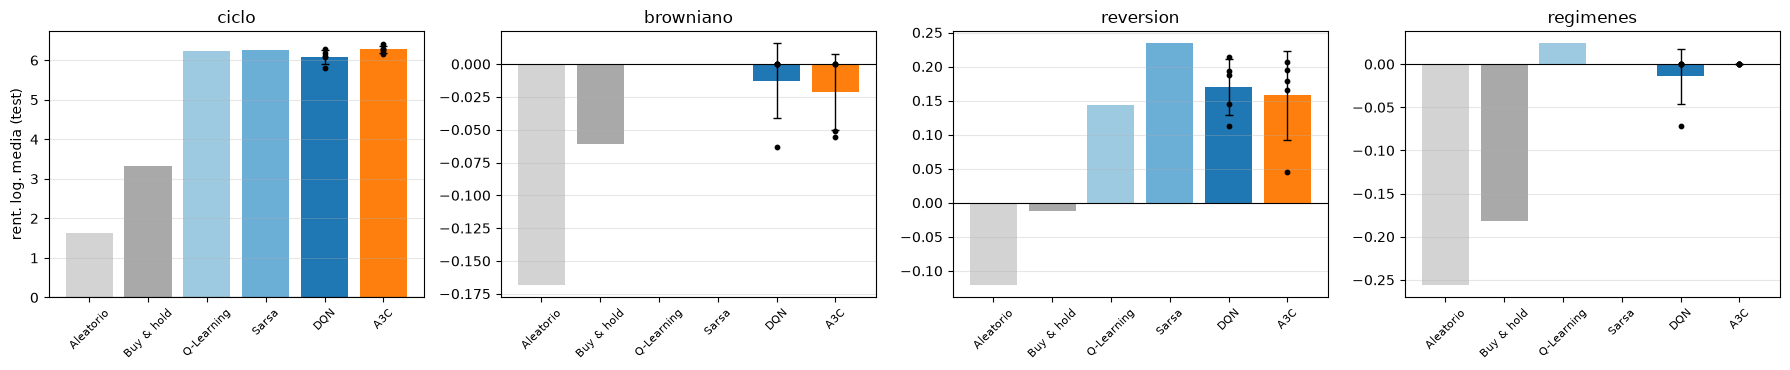

In [60]:
# Rentabilidad en test por mercado; en DQN y A3C, barra = media de las 5 semillas y puntos = cada semilla
AGENTES = ["Aleatorio", "Buy & hold", "Q-Learning", "Sarsa", "DQN", "A3C"]
COLORES_AGENTE = {"Aleatorio": "lightgray", "Buy & hold": "darkgray", "Q-Learning": "#9ecae1", "Sarsa": "#6baed6",
                  "DQN": "tab:blue", "A3C": "tab:orange"}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, g in zip(axes, GENERADORES):
    valores = TABLA_FINAL.loc[g].reindex(AGENTES)
    ax.bar(AGENTES, valores["ret_log_medio"], color=[COLORES_AGENTE[a] for a in AGENTES])
    for nombre in ALGORITMOS.values():
        x = AGENTES.index(nombre)
        puntos = TEST.query("algoritmo == @nombre and mercado == @g")["ret_log_medio"]
        ax.errorbar(x, valores.loc[nombre, "ret_log_medio"], yerr=valores.loc[nombre, "ret_log_desv"],
                    color="black", capsize=3, linewidth=1)
        ax.scatter([x] * len(puntos), puntos, color="black", s=10, zorder=3)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(g)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("rent. log. media (test)")
plt.tight_layout()
plt.show()

**Resultado.**

- **Test:** en *ciclo*, A3C 6.27 ± 0.09 y DQN 6.09 ± 0.17 (Q-Learning 6.24, Sarsa 6.25, *buy & hold* 3.33); en *reversión*, DQN 0.17 ± 0.04 y A3C 0.16 ± 0.07 (Sarsa 0.23, Q-Learning 0.14, *buy & hold* −0.01). En *browniano* y *regímenes*, los dos se quedan en torno a 0 sin operar, frente a −0.06 y −0.18 de *buy & hold*.
- **Con 5 000 episodios, A3C alcanza al DQN y lo supera en *ciclo*:** el DQN llega a su techo en menos de 1 000 episodios; A3C, que usa cada transición una sola vez, aprende más despacio pero sigue mejorando hasta el final (*ciclo*: 6.18 → 6.35 en validación; *reversión*: 0.09 → 0.21). Con los 1 000 episodios del ajuste, el DQN ganaba en los dos mercados.
- ***Ciclo*:** la peor semilla de A3C (6.15) supera a la mediana del DQN (6.10), con menos operaciones (35 por episodio frente a 60).
- ***Reversión*:** sin ganador entre los dos (semillas de 0.11 a 0.22 y de 0.05 a 0.21). La semilla 10 de A3C da 0.045; sin ella, 0.19. Sarsa sigue siendo el mejor.
- **De validación a test:** *reversión* 0.23 → 0.17 (DQN) y 0.21 → 0.16 (A3C); *ciclo* 6.19 → 6.09 y 6.35 → 6.27. La validación es algo optimista: con ella se eligieron las configuraciones y tiene solo 50 series.
- **Convergencia y coste:** el criterio del 90% da desviaciones del orden de la media (DQN en *ciclo*: 2 860 ± 2 546 episodios), como en la parte 1. Por episodio, el DQN cuesta 49 ms, A3C 9 ms con 4 trabajadores (~37 ms de CPU; 20 ms con $t_{max}$ = 5) y la tabla ~14 ms.
- **Conclusión:** con un estado de dos variables, las redes no superan a la tabla: evitan discretizar, pero no añaden información. Aportarían con un estado más rico (varios retornos pasados, volatilidad).

### Fase 6: Tabla frente a redes (series sintéticas)

Q-Learning y Sarsa (parte 1) y DQN y A3C (fases 1 a 5) resuelven el mismo problema con el mismo protocolo: mismas series de entrenamiento, validación y test, mismas métricas y el mismo criterio de convergencia (5 semillas × 5 000 episodios). Lo que cambia es cómo se representa lo aprendido:

| | Tabla (Q-Learning, Sarsa) | Redes (DQN, A3C) |
|---|---|---|
| Estado | Tendencia discretizada en 10 o 20 intervalos (+ posición) | Tendencia continua normalizada (+ posición) |
| Lo aprendido | Un valor $Q(s, a)$ por casilla, independiente de las vecinas | Una función continua: lo aprendido en una tendencia se extiende a las próximas |
| Estados no vistos | Se quedan a 0 | La red generaliza |

Se comparan en cinco aspectos: rendimiento en test, política aprendida, velocidad de aprendizaje, estabilidad entre semillas y coste.

**Tablas de la parte 1.** La parte 1 no guardó sus tablas $Q$, pero su entrenamiento es determinista: `tabular.py` copia su código y sus configuraciones, y con las mismas semillas reproduce exactamente las mismas tablas. Se comprueba con sus resultados de test.

In [61]:
import json
import tabular as T
from dqn import cargar, red_desde_pesos as red_dqn
from a3c import red_desde_pesos as red_a3c
from protocolo import normalizacion

CARPETA_TABULAR = CARPETA_RESULTADOS / "tabular"
CARPETA_TABULAR.mkdir(exist_ok=True)
METODOS_TAB = {"qlearning": "Q-Learning", "sarsa": "Sarsa"}
NOMBRES = ["Q-Learning", "Sarsa", "DQN", "A3C"]
COLOR = {"Q-Learning": "#9ecae1", "Sarsa": "#3182bd", "DQN": "tab:green", "A3C": "tab:orange"}

# Entrenamientos finales de la parte 1 (se cargan de disco; si faltan, se reentrenan: ~2 min cada uno)
TABULAR = {(g, METODOS_TAB[m], rep): T.entrenar_final(g, m, rep, CARPETA_TABULAR / f"final_{m}_{g}_r{rep}.pkl")
           for g in GENERADORES for m in METODOS_TAB for rep in T.REPS_FINAL}
CORTES_TAB = {(g, METODOS_TAB[m]): T.cortes_config(g, T.MEJOR[(g, m)]["discretizacion"])
              for g in GENERADORES for m in METODOS_TAB}

# Entrenamientos finales de la fase 5
REDES = {(g, alg, rep): cargar(CARPETA_RESULTADOS / f"final_{alg.lower()}_{g}_r{rep}.pkl")
         for g in GENERADORES for alg in ("DQN", "A3C") for rep in T.REPS_FINAL}
NORM = {g: normalizacion(g) for g in GENERADORES}

# Comprobación: rentabilidad log. media en test de las tablas reproducidas = la publicada en la parte 1
PARTE1_TEST_TAB = {("ciclo", "Q-Learning"): 6.239, ("ciclo", "Sarsa"): 6.254,
                   ("browniano", "Q-Learning"): 0.000, ("browniano", "Sarsa"): 0.000,
                   ("reversion", "Q-Learning"): 0.143, ("reversion", "Sarsa"): 0.234,
                   ("regimenes", "Q-Learning"): 0.024, ("regimenes", "Sarsa"): 0.000}
SERIES_TEST_7 = {g: generar_conjunto(g, SEMILLA_TEST, N_TEST) for g in GENERADORES}
for (g, nombre), valor in PARTE1_TEST_TAB.items():
    rent = np.mean([evaluar(T.politica_voraz(TABULAR[(g, nombre, rep)]["Q"], CORTES_TAB[(g, nombre)]),
                            SERIES_TEST_7[g])["ret_log_medio"] for rep in T.REPS_FINAL])
    assert round(rent, 3) == valor, (g, nombre, rent)
print("Tablas de la parte 1 reproducidas: mismos resultados de test")

Tablas de la parte 1 reproducidas: mismos resultados de test


#### Rendimiento en test

Rentabilidad logarítmica media en las 200 series de test (tabla final de la fase 5). Media de las 5 semillas; entre paréntesis, la desviación entre semillas en las redes.

In [62]:
TABLA_FINAL_7 = pd.read_csv(CARPETA_RESULTADOS / "tabla_final.csv").set_index(["mercado", "agente"])
filas = {}
for g in GENERADORES:
    fila = {"buy & hold": f"{TABLA_FINAL_7.loc[(g, 'Buy & hold'), 'ret_log_medio']:.2f}"}
    for nombre in NOMBRES:
        f = TABLA_FINAL_7.loc[(g, nombre)]
        fila[nombre] = f"{f['ret_log_medio']:.2f}" + (f" ({f['ret_log_desv']:.2f})" if nombre in ("DQN", "A3C") else "")
    filas[g] = fila
pd.DataFrame(filas).T

,buy & hold,Q-Learning,Sarsa,DQN,A3C
ciclo,3.33,6.24,6.25,6.09 (0.17),6.27 (0.09)
browniano,-0.06,0.00,0.00,-0.01 (0.03),-0.02 (0.03)
reversion,-0.01,0.14,0.23,0.17 (0.04),0.16 (0.07)
regimenes,-0.18,0.02,0.00,-0.01 (0.03),0.00 (0.00)


**Resultado.** Ninguna representación gana en todos los mercados, y las diferencias son del orden de la variabilidad entre semillas:

- ***Ciclo*:** los cuatro casi duplican a *buy & hold* (6.09–6.27 frente a 3.33). A3C es el mejor por poco (6.27); DQN, el peor (6.09 ± 0.17).
- ***Reversión*:** Sarsa sigue siendo el mejor (0.23); DQN (0.17) y A3C (0.16) superan a Q-Learning (0.14).
- ***Browniano* y *regímenes*:** todos en torno a 0, es decir, no operar. Las redes quedan ligeramente por debajo (−0.01/−0.02): alguna operación ocasional que la tabla no hace. Q-Learning en *regímenes* es el único que gana algo (0.02).

Es lo que anticipaba el profesor: con un estado de dos variables, la red debería *al menos empatar* con la tabla, y eso es lo que hace.

#### Política aprendida

Para cada agente, la acción voraz en función de la tendencia, en su escala original y entre los percentiles 1 y 99 de cada mercado. Dos franjas por agente: sin activo (compra o se queda fuera) y con activo (vende o se queda dentro). Se muestra la acción mayoritaria de las 5 semillas; en blanco, los intervalos de la tabla que no se visitaron nunca.

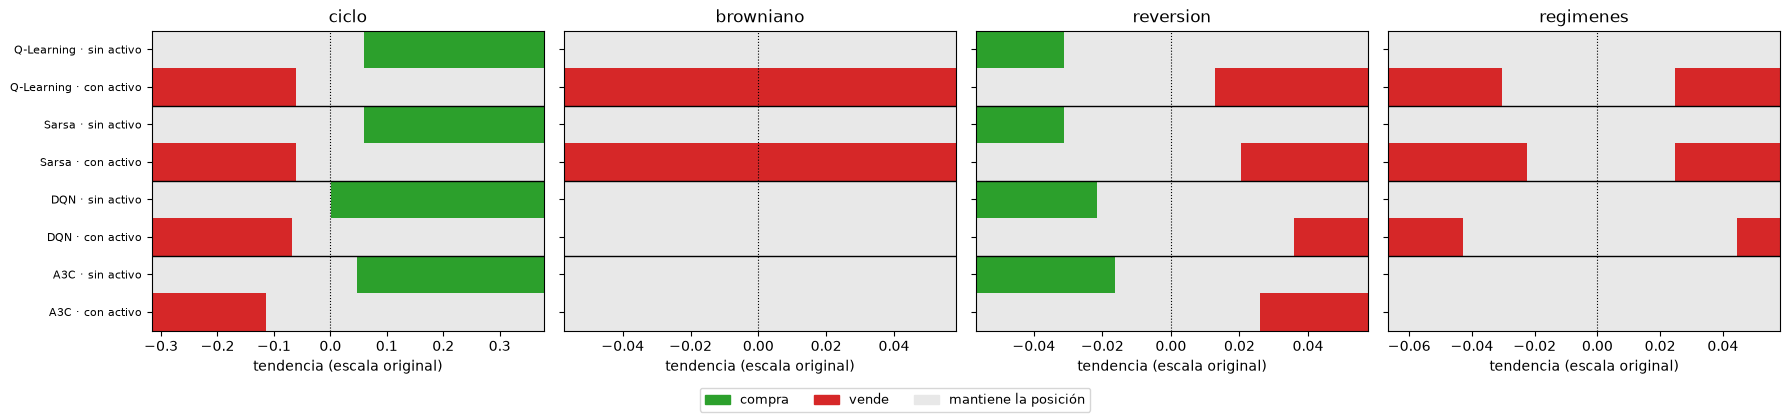

In [63]:
from matplotlib.colors import ListedColormap


def acciones_agente(g, nombre, rep, t):
    # Acción efectiva (0 vende, 1 mantiene la posición, 2 compra) sin y con activo para cada tendencia t;
    # en la tabla, NaN en los intervalos no visitados
    if nombre in METODOS_TAB.values():
        Q = TABULAR[(g, nombre, rep)]["Q"]
        cortes = CORTES_TAB[(g, nombre)]
        n = len(cortes) + 1
        ef = T.acciones_efectivas(Q).astype(float)
        ef[~np.any(Q != 0, axis=1)] = np.nan
        i = np.searchsorted(cortes, t, side="right")
        return ef[i], ef[n + i]
    z = ((t - NORM[g]["media"]) / NORM[g]["desv"]).astype(np.float32)
    entradas = [torch.from_numpy(np.stack([z, np.full_like(z, pos)], axis=1)) for pos in (0.0, 1.0)]
    with torch.no_grad():
        if nombre == "DQN":
            red = red_dqn(REDES[(g, nombre, rep)]["pesos"])
            a0, a1 = (red(x).argmax(1).numpy() for x in entradas)
        else:
            red = red_a3c(REDES[(g, nombre, rep)]["pesos"])
            a0, a1 = (red(x)[0].argmax(1).numpy() for x in entradas)
    return np.where(a0 == 2, 2.0, 1.0), np.where(a1 == 0, 0.0, 1.0)


def moda(acciones):
    # Acción mayoritaria entre semillas y fracción de semillas que la eligen (NaN si nadie visitó el estado)
    a = np.array(acciones)
    valores = np.array([np.bincount(col[~np.isnan(col)].astype(int), minlength=3).argmax()
                        if (~np.isnan(col)).any() else np.nan for col in a.T], dtype=float)
    acuerdo = np.where(np.isnan(valores), np.nan, (a == valores).mean(axis=0))
    return valores, acuerdo


REJILLA_T = {g: np.linspace(*np.percentile(T.tendencias_disc(g), [1, 99]), 400) for g in GENERADORES}
POLITICAS = {}  # (g, nombre) -> (moda sin activo, moda con activo)
for g in GENERADORES:
    for nombre in NOMBRES:
        por_rep = [acciones_agente(g, nombre, rep, REJILLA_T[g]) for rep in T.REPS_FINAL]
        POLITICAS[(g, nombre)] = (moda([p[0] for p in por_rep])[0], moda([p[1] for p in por_rep])[0])

cmap = ListedColormap(["#d62728", "#e8e8e8", "#2ca02c"])
cmap.set_bad("white")
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, g in zip(axes, GENERADORES):
    filas, etiquetas = [], []
    for nombre in NOMBRES:
        sin, con = POLITICAS[(g, nombre)]
        filas += [sin, con]
        etiquetas += [f"{nombre} · sin activo", f"{nombre} · con activo"]
    t = REJILLA_T[g]
    ax.imshow(np.ma.masked_invalid(np.array(filas)), cmap=cmap, vmin=0, vmax=2, aspect="auto",
              extent=[t[0], t[-1], len(filas) - 0.5, -0.5], interpolation="nearest")
    for k in range(2, len(filas), 2):
        ax.axhline(k - 0.5, color="black", linewidth=1)
    ax.axvline(0, color="black", linestyle=":", linewidth=0.8)
    ax.set_yticks(range(len(filas)), etiquetas if g == "ciclo" else [""] * len(filas), fontsize=8)
    ax.set_title(g)
    ax.set_xlabel("tendencia (escala original)")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ("#2ca02c", "#d62728", "#e8e8e8")],
           labels=["compra", "vende", "mantiene la posición"], loc="lower center", ncol=3, fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

In [64]:
# Sobre las tendencias que se observan de verdad (series de discretización, ponderadas por su frecuencia):
# - acuerdo entre semillas: fracción media de las 5 semillas que eligen la acción mayoritaria
# - coincidencia con Q-Learning: % de observaciones con la misma acción que la mayoritaria de Q-Learning
filas = []
for g in GENERADORES:
    t = T.tendencias_disc(g)[::10]
    modas = {}
    for nombre in NOMBRES:
        por_rep = [acciones_agente(g, nombre, rep, t) for rep in T.REPS_FINAL]
        sin, acuerdo_sin = moda([p[0] for p in por_rep])
        con, acuerdo_con = moda([p[1] for p in por_rep])
        modas[nombre] = np.concatenate([sin, con])
        filas.append({"mercado": g, "agente": nombre,
                      "acuerdo entre semillas %": 100 * np.nanmean(np.concatenate([acuerdo_sin, acuerdo_con]))})
    for f in filas[-len(NOMBRES):]:
        f["misma acción que Q-Learning %"] = 100 * np.nanmean(modas[f["agente"]] == modas["Q-Learning"])
ACUERDO = pd.DataFrame(filas).set_index(["mercado", "agente"])
ACUERDO.unstack("agente").round(1)

acuerdo entre semillas %                         \
agente                         A3C   DQN Q-Learning Sarsa   
mercado                                                     
browniano                     94.4  86.6      100.0  80.0   
ciclo                         97.2  95.8       94.5  97.0   
regimenes                     99.9  97.7       91.9  98.9   
reversion                     96.0  97.3       95.1  97.9   

          misma acción que Q-Learning %                          
agente                              A3C   DQN Q-Learning  Sarsa  
mercado                                                          
browniano                          50.0  50.0      100.0  100.0  
ciclo                              93.3  91.5      100.0  100.0  
regimenes                          90.0  93.8      100.0   97.7  
reversion                          85.1  84.2      100.0   95.2

**Resultado.** Las cuatro aprenden **la misma estrategia** en cada mercado: la acción coincide con la de Q-Learning en el 91–93% de los estados observados en *ciclo* y *regímenes* y en el 84–85% en *reversión*.

- ***Ciclo*:** seguir la tendencia, con una banda de histéresis (compra por encima de un umbral, vende por debajo de otro y entre medias mantiene). La tabla pone los umbrales en ±0.06; las redes compran antes (DQN desde 0) y A3C vende más tarde (−0.12).
- ***Reversión*:** estrategia contraria en los cuatro. La tabla solo compra en el decil más bajo (por debajo de −0.031): no puede afinar dentro de un intervalo. Las redes sitúan el umbral donde quieren (−0.022 DQN, −0.017 A3C) y venden más tarde: entran antes y aguantan más.
- ***Regímenes*:** la tabla y el DQN venden con tendencias extremas en los dos sentidos (la tendencia extrema como señal de volatilidad) y no compran; A3C no compra nunca.
- ***Browniano*:** ninguno compra. Con activo, la tabla vendería y las redes mantendrían, pero ese estado no llega a darse: de ahí el 50% de coincidencia, sin efecto en el resultado.
- **Diferencia de forma:** la tabla decide por intervalos y depende de dónde caen los cortes (por eso en la parte 1 hubo que ajustar la discretización); la red traza el umbral de forma continua.
- **Acuerdo entre semillas:** 93–97% de media en los cuatro. Las redes no son menos estables que la tabla, salvo el DQN en *browniano* (87%), que opera de vez en cuando.

#### Velocidad de aprendizaje

Validación cada 100 episodios, media de las 5 semillas. Arriba, en episodios; abajo, en segundos de entrenamiento, con el coste por episodio medido en un solo proceso (tabla ~14 ms, DQN ~49 ms, A3C ~9 ms de reloj con 4 procesos).

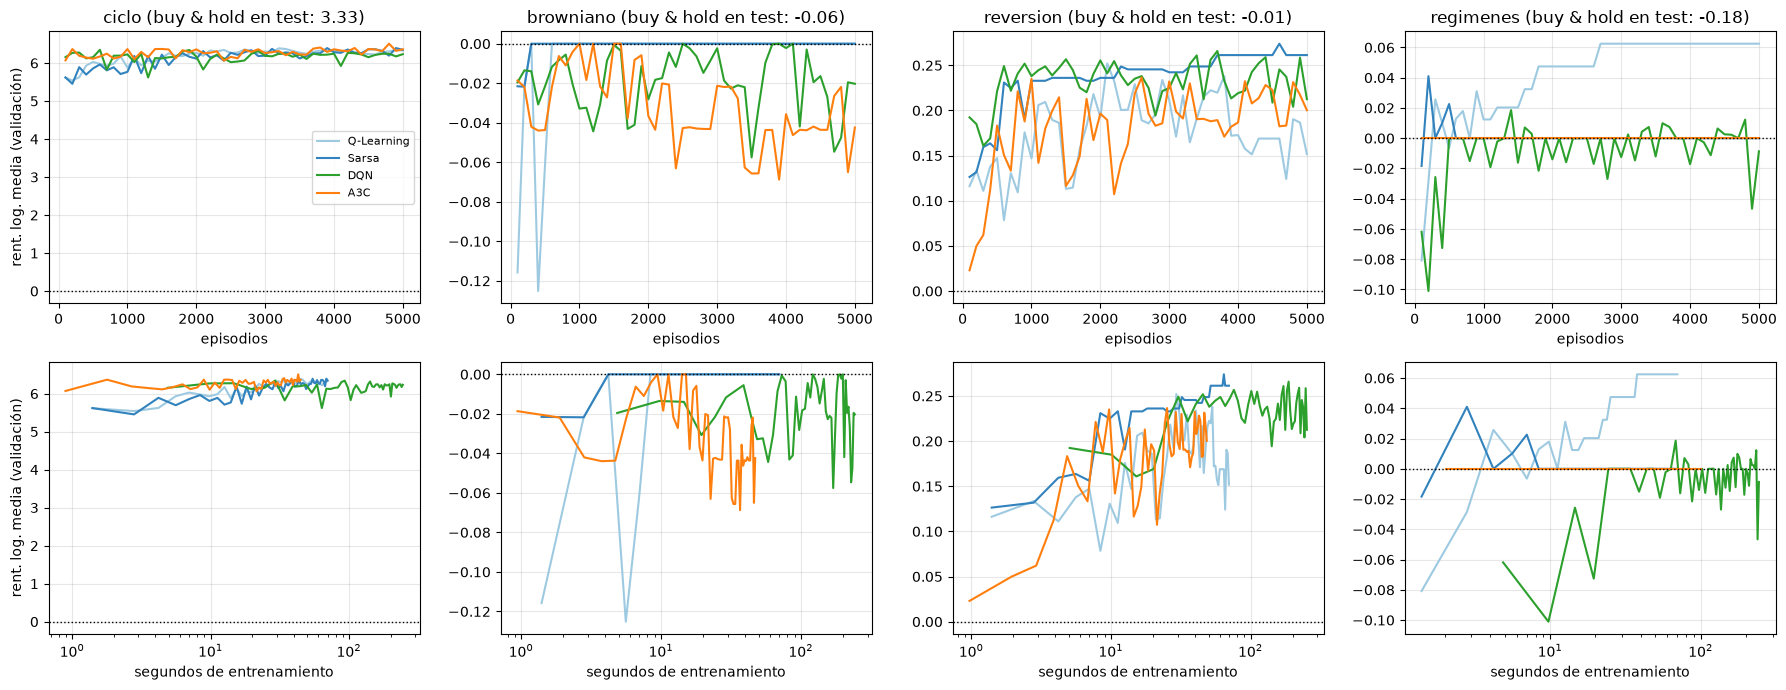

In [65]:
with open(CARPETA_RESULTADOS / "tiempos.json") as f:
    TIEMPOS_7 = json.load(f)
MS = {"Q-Learning": 14.0, "Sarsa": 14.0}

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, g in enumerate(GENERADORES):
    for nombre in NOMBRES:
        fuente = TABULAR if nombre in METODOS_TAB.values() else REDES
        curvas = [fuente[(g, nombre, rep)]["curva"] for rep in T.REPS_FINAL]
        n = min(len(c) for c in curvas)
        media = np.mean([c["ret_log_medio"].to_numpy()[:n] for c in curvas], axis=0)
        episodios = curvas[0]["episodio"].to_numpy()[:n]
        ms = MS.get(nombre) or TIEMPOS_7[nombre.lower()][g]["ms_por_episodio"]
        axes[0, j].plot(episodios, media, color=COLOR[nombre], label=nombre)
        axes[1, j].plot(episodios * ms / 1000, media, color=COLOR[nombre], label=nombre)
    bh = TABLA_FINAL_7.loc[(g, "Buy & hold"), "ret_log_medio"]
    for ax in axes[:, j]:
        ax.axhline(0, color="black", linestyle=":", linewidth=1)
        ax.grid(alpha=0.3)
    axes[0, j].set_title(f"{g} (buy & hold en test: {bh:.2f})")
    axes[0, j].set_xlabel("episodios")
    axes[1, j].set_xlabel("segundos de entrenamiento")
    axes[1, j].set_xscale("log")
axes[0, 0].set_ylabel("rent. log. media (validación)")
axes[1, 0].set_ylabel("rent. log. media (validación)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Resultado.**

- **En episodios, las redes arrancan antes en *ciclo*:** a los 100 episodios ya están en 6.1, donde la tabla tarda ~2 000 episodios en llegar. Generalizan entre tendencias próximas: cada transición enseña algo sobre las vecinas, mientras que la tabla tiene que visitar cada casilla.
- **En *reversión*, el DQN y Sarsa llegan antes** (~800–1 000 episodios) que Q-Learning y A3C, que oscilan más.
- **En *browniano* la tabla es más limpia:** fija 0 (no operar) en ~500 episodios y no se mueve; las redes oscilan entre −0.06 y 0 hasta el final.
- **En segundos, A3C es el más rápido** (4 procesos, ~9 ms por episodio), la tabla le sigue (~14 ms) y el DQN es el más lento (~49 ms, por las actualizaciones con lotes de la memoria): para el mismo número de episodios tarda ~3.5 veces más que la tabla.
- **El criterio del 90% da 1 900–2 600 episodios de media en los cuatro**, con desviaciones del orden de la media: no distingue a los algoritmos.

#### Coste y diseño

In [66]:
from dqn import RedQ
from a3c import RedActorCritico

n_param = lambda red: sum(p.numel() for p in red.parameters())
conv = TABLA_FINAL_7["episodios_media"].unstack("agente")
pd.DataFrame({
    "parámetros del modelo": {"Q-Learning": "60–120 (20–40 estados × 3)", "Sarsa": "60–120 (20–40 estados × 3)",
                              "DQN": f"{n_param(RedQ()):,}".replace(",", "."),
                              "A3C": f"{n_param(RedActorCritico()):,}".replace(",", ".")},
    "hiperparámetros ajustados": {"Q-Learning": "α, γ, ε, discretización", "Sarsa": "α, γ, ε, discretización",
                                  "DQN": "α, γ, ε (+ 8 fijos: red, memoria, lote, red objetivo…)",
                                  "A3C": "α, γ, β, t_max (+ red, trabajadores…)"},
    "ms por episodio": {"Q-Learning": "~14", "Sarsa": "~14", "DQN": "~49",
                        "A3C": "~9 de reloj (~37 de CPU, 4 procesos)"},
    "episodios hasta converger (media de los 4 mercados)": {n: f"{conv[n].mean():.0f}" for n in NOMBRES},
    "acuerdo entre semillas % (media)": {n: f"{ACUERDO.xs(n, level='agente').iloc[:, 0].mean():.1f}" for n in NOMBRES},
}).T

,Q-Learning,Sarsa,DQN,A3C
parámetros del modelo,60–120 (20–40 estados × 3),60–120 (20–40 estados × 3),4.547,4.612
hiperparámetros ajustados,"α, γ, ε, discretización","α, γ, ε, discretización","α, γ, ε (+ 8 fijos: red, memoria, lote, red ob...","α, γ, β, t_max (+ red, trabajadores…)"
ms por episodio,~14,~14,~49,"~9 de reloj (~37 de CPU, 4 procesos)"
episodios hasta converger (media de los 4 mercados),2160,2015,2565,1860
acuerdo entre semillas % (media),95.4,93.5,94.3,96.9


**Conclusión de la comparación**

| Aspecto | Tabla | Redes |
|---|---|---|
| Rendimiento | Igual (Sarsa, mejor en *reversión*) | Igual (A3C, mejor en *ciclo*) |
| Estrategia | La esperada, por intervalos | La misma, con umbrales continuos |
| Aprendizaje | Más lento al principio (visita casilla a casilla); exacta donde no hay señal | Generaliza: arranca antes en *ciclo*; oscila más donde no hay señal |
| Coste | ~14 ms por episodio, 60–120 valores | DQN ~49 ms, A3C ~9 ms (4 procesos); ~4 600 parámetros |
| Diseño | Hay que elegir la discretización | No hay que discretizar, pero hay más hiperparámetros (red, memoria, lote, red objetivo, trabajadores) y hay que escalar entradas y recompensa |
| Garantías | Converge a la $Q$ óptima si explora lo suficiente | Sin garantías: puede divergir u oscilar (de ahí Huber, red objetivo y recorte del gradiente) |

**Con un estado de dos variables, la tabla es suficiente y más simple.** La red no tiene nada que generalizar que la tabla no cubra con 10–20 intervalos. Su ventaja, aceptar estados continuos y de muchas dimensiones sin discretizar, solo compensa con un estado más rico; en la fase 7 se prueba con datos reales.

### Fase 7: Datos reales

Extensión: DQN y A3C con precios diarios reales, con el diseño de la fase 8 de la parte 1 para comparar directamente con Q-Learning y Sarsa en las mismas fechas.

- **Mercados:** EUR/USD (desde 1999), S&P 500 con dividendos reinvertidos (desde 1988) y *Energía*, 10 grandes petroleras y el Brent (desde 2001). Copia local en `datos_reales/`, la misma de la parte 1.
- **Bloques de 252 sesiones** (≈ 1 año) sin solapar, divididos por fechas: ~70% de los bloques más antiguos para entrenar, 15% para validación y el 15% más reciente para test.
- **Walk-forward:** cada bloque de validación o test se juega con un agente entrenado con todas las sesiones anteriores, salvo un *embargo* de 50. Los episodios de entrenamiento son ventanas de 252 sesiones con inicio al azar (en *Energía*, también la serie).
- **Entorno del profesor sin cambios** (comisión del 0.1%). Solo cambia la observación que recibe la red.
- **DQN de la fase 1** (misma red, memoria, red objetivo, Huber y ε-greedy), 1 000 episodios por entrenamiento, exploración en el 50%.
- **A3C de la fase 3** (4 trabajadores asíncronos, retorno a $n$ pasos, entropía), 2 000 episodios por entrenamiento: el doble que el DQN, porque usa cada transición una sola vez y en los mercados sintéticos aprendía más despacio. $\beta = 0.01$ y $t_{max} = 20$, los valores por defecto de `a3c.py`.
- En los dos, la recompensa se escala por la volatilidad diaria del periodo de entrenamiento.

**Dos variantes de estado**

| Variante | Entrada de la red | Para qué |
|---|---|---|
| profesor | tendencia de 6 precios y posición | Mismo estado que Q-Learning y Sarsa en la parte 1, sin discretizar |
| ampliado | + tendencia de 50 precios, rentabilidades log. de las 5 últimas sesiones, volatilidad de 20 sesiones | Lo que la tabla no puede: 8 variables continuas. En la parte 1, añadir solo la tendencia de 50 ya obligó a bajar a 5 × 3 intervalos |

Todas las variables usan solo precios hasta la sesión actual y se normalizan (media 0, desviación 1) con las sesiones de entrenamiento de cada bloque; se recortan a ±10 (la volatilidad se dispara en 2008 y 2020).

**Hiperparámetros:** con 3–6 bloques de validación no tiene sentido repetir el ajuste con Optuna. Para cada algoritmo, mercado y estado se eligen en validación $\gamma \in \{0.5, 0.9, 0.99\}$, los de la parte 1, y $\alpha \in \{10^{-5}, 10^{-4}\}$, el rango que eligió Optuna en los mercados sintéticos (en los dos algoritmos, ~10⁻⁵ en los mercados ruidosos y ~10⁻⁴ en *ciclo*). 3 repeticiones: 468 entrenamientos de validación y 78 de test por algoritmo.

In [67]:
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import matplotlib.dates as mdates
from IPython.display import clear_output

import reales as R

DATOS_REALES = R.datos()
BLOQUES_VAL_REAL, BLOQUES_TEST_REAL = R.particion()
CARPETA_REALES = CARPETA_RESULTADOS / "reales"
CARPETA_REALES.mkdir(exist_ok=True)

filas = []
for m, d in DATOS_REALES.items():
    fecha = lambda i: d.index[i].strftime("%Y-%m-%d")
    n_bloques = len(R.bloques(len(d)))
    v, t = BLOQUES_VAL_REAL[m], BLOQUES_TEST_REAL[m]
    filas.append({"mercado": m, "series": d.shape[1], "desde": fecha(0), "hasta": fecha(-1),
                  "bloques entren.": n_bloques - len(v) - len(t),
                  "validación": f"{len(v)}: {fecha(v[0][0])} a {fecha(v[-1][1])}",
                  "test": f"{len(t)}: {fecha(t[0][0])} a {fecha(t[-1][1])}"})
pd.DataFrame(filas).set_index("mercado")

,series,desde,hasta,bloques entren.,validación,test
mercado,,,,,,
EUR/USD,1,1999-01-04,2026-09-30,19,4: 2018-08-30 a 2022-09-19,4: 2022-09-19 a 2026-09-30
S&P 500,1,1988-01-04,2026-09-30,26,6: 2014-09-19 a 2020-09-22,6: 2020-09-22 a 2026-09-30
Energía,11,2001-06-18,2026-09-30,17,3: 2020-08-12 a 2023-09-07,3: 2023-09-07 a 2026-09-30


In [68]:
# 1) Con la variante del profesor sin normalizar, la observación es la del entorno de la plantilla
m, b = "S&P 500", BLOQUES_TEST_REAL["S&P 500"][0]
sin_normalizar = {"cols": [0], "media": np.zeros(1), "desv": np.ones(1)}
env_real = R.entorno(m, 0, *b, sin_normalizar)
env_plantilla = entorno.SimpleTradingEnv(R.precios(m)[b[0] - 5: b[1] + 1, 0])
o1, _ = env_real.reset()
o2, _ = env_plantilla.reset()
rng = np.random.default_rng(0)
terminado = False
while not terminado:
    assert np.array_equal(o1, o2)
    a = int(rng.integers(3))
    o1, r1, terminado, *_ = env_real.step(a)
    o2, r2, *_ = env_plantilla.step(a)
    assert r1 == r2 and env_real.balance == env_plantilla.balance

# 2) Referencias en test: idénticas a las de la parte 1 (rentabilidad anual, %)
PARTE1_REF_TEST = {("EUR/USD", "Aleatorio"): -5.50, ("EUR/USD", "Buy & hold"): 3.09,
                   ("S&P 500", "Aleatorio"): 5.49, ("S&P 500", "Buy & hold"): 16.51,
                   ("Energía", "Aleatorio"): 1.23, ("Energía", "Buy & hold"): 13.60}
REF_VAL_REAL = R.referencias("val")
REF_TEST_REAL = R.referencias("test")
for clave, valor in PARTE1_REF_TEST.items():
    assert round(R.resumir(REF_TEST_REAL[clave])["rent_anual_%"], 2) == valor, clave
print("Comprobaciones correctas: mismo entorno y mismas referencias que en la parte 1")

Comprobaciones correctas: mismo entorno y mismas referencias que en la parte 1


#### Validación: elección de $\alpha$ y $\gamma$

Rentabilidad anual geométrica media (%) en los bloques de validación, media de 3 repeticiones. Con empate se queda el $\gamma$ y el $\alpha$ más pequeños.

In [69]:
ALGORITMOS_REAL = {"DQN": R.tarea, "A3C": R.tarea_a3c}
N_A_LA_VEZ = {"DQN": 20, "A3C": 6}  # cada entrenamiento de A3C usa 4 procesos


def correr_reales(lista, alg, etiqueta):
    # Cada tarea entrena un agente y juega un bloque; si ya está en disco, se carga.
    # ProcessPoolExecutor (no Pool): sus procesos pueden lanzar los trabajadores de A3C
    t0 = time.perf_counter()
    with ProcessPoolExecutor(N_A_LA_VEZ[alg], mp_context=mp.get_context("spawn")) as ex:
        pendientes = [ex.submit(ALGORITMOS_REAL[alg], *t, str(CARPETA_REALES)) for t in lista]
        while not all(p.done() for p in pendientes):
            time.sleep(10)
            clear_output(wait=True)
            print(f"{etiqueta}: {sum(p.done() for p in pendientes)}/{len(pendientes)} entrenamientos, "
                  f"{(time.perf_counter() - t0) / 60:.1f} min")
        resultados = [p.result() for p in pendientes]
    clear_output(wait=True)
    return resultados


TAREAS_VAL_REAL = R.tareas("val", R.combinaciones_validacion())
RESULTADOS_VAL_REAL, VAL_REAL, ELEGIDAS_REAL = {}, {}, {}
for alg in ALGORITMOS_REAL:
    RESULTADOS_VAL_REAL[alg] = correr_reales(TAREAS_VAL_REAL, alg, f"Validación {alg}")
    VAL_REAL[alg] = R.agrupar(TAREAS_VAL_REAL, RESULTADOS_VAL_REAL[alg])
    ELEGIDAS_REAL[alg] = R.elegir(VAL_REAL[alg])
for alg, res in RESULTADOS_VAL_REAL.items():
    print(f"{alg}: {len(res)} entrenamientos, {np.mean([r['tiempo'] for r in res]):.0f} s de media cada uno "
          f"(con los demás en paralelo), {sum(r['divergio'] for r in res)} divergencias")

tabla_val = pd.DataFrame([{"mercado": m, "variante": v, "algoritmo": alg, "gamma": g, "alpha": lr,
                           "rent_anual_%": R.resumir(res)["rent_anual_%"]}
                          for alg in ALGORITMOS_REAL for (m, v, lr, g), res in VAL_REAL[alg].items()])
tabla_val = tabla_val.pivot_table(index=["mercado", "variante", "algoritmo"], columns=["gamma", "alpha"],
                                  values="rent_anual_%", sort=False).round(2)
tabla_val[("buy & hold", "")] = [round(R.resumir(REF_VAL_REAL[(m, "Buy & hold")])["rent_anual_%"], 2)
                           for m, v, alg in tabla_val.index]
tabla_val[("elegido", "")] = [f"γ={ELEGIDAS_REAL[alg][(m, v)]['gamma']}, α={ELEGIDAS_REAL[alg][(m, v)]['lr']:g}"
                        for m, v, alg in tabla_val.index]
tabla_val

DQN: 468 entrenamientos, 126 s de media cada uno (con los demás en paralelo), 0 divergencias
A3C: 468 entrenamientos, 54 s de media cada uno (con los demás en paralelo), 0 divergencias


gamma                          0.5            0.9           0.99         \
alpha                      0.00001 0.0001 0.00001 0.0001 0.00001 0.0001   
mercado variante algoritmo                                                
EUR/USD profesor DQN          0.00  -0.17   -4.35  -4.36   -3.83  -3.84   
                 A3C          0.00  -3.14    0.00  -1.80    0.00  -0.70   
        ampliado DQN         -2.73  -4.22   -2.77  -4.85   -3.60  -3.62   
                 A3C          0.00  -0.78    0.00  -0.98    0.00  -0.69   
S&P 500 profesor DQN         10.44   9.66   11.72  10.70   10.96   9.91   
                 A3C          8.00   6.01    9.18   7.67    9.06  10.11   
        ampliado DQN          7.37   2.19    4.64  -0.43    9.82   3.39   
                 A3C          2.84   7.75    7.36   9.69    8.13  10.55   
Energía profesor DQN         36.41  32.72   35.16  30.85   35.85  34.58   
                 A3C         24.75  13.98   21.36  24.07   16.01  17.52   
        ampliado DQN         24.13  13.24   18.80  12.67   17.04  11.33   
                 A3C         20.83  24.31   26.35  21.32   19.86  19.02   

gamma                      buy & hold           elegido  
alpha                                                    
mercado variante algoritmo                               
EUR/USD profesor DQN            -3.83    γ=0.5, α=1e-05  
                 A3C            -3.83    γ=0.5, α=1e-05  
        ampliado DQN            -3.83    γ=0.5, α=1e-05  
                 A3C            -3.83    γ=0.5, α=1e-05  
S&P 500 profesor DQN            10.82    γ=0.9, α=1e-05  
                 A3C            10.82  γ=0.99, α=0.0001  
        ampliado DQN            10.82   γ=0.99, α=1e-05  
                 A3C            10.82  γ=0.99, α=0.0001  
Energía profesor DQN            35.85    γ=0.5, α=1e-05  
                 A3C            35.85    γ=0.5, α=1e-05  
        ampliado DQN            35.85    γ=0.5, α=1e-05  
                 A3C            35.85    γ=0.9, α=1e-05

**Resultado.**

**DQN**

- **Estado del profesor:** al nivel de *buy & hold* en S&P 500 (9.7–11.7% frente a 10.8%) y *Energía* (31–36% frente a 35.9%). En EUR/USD, con $\gamma = 0.5$ y $\alpha = 10^{-5}$ no opera (0% frente a −3.8%); con $\gamma$ alto opera y pierde como *buy & hold* (−3.8% a −4.4%). Es lo que encontró la tabla en la parte 1.
- **El estado ampliado empeora en S&P 500 y *Energía* en las 6 combinaciones:** en S&P 500, como mucho un 9.8% frente al 11.7% del estado del profesor; en *Energía*, un 24% frente a un 36%. Con $\alpha = 10^{-4}$ cae aún más (S&P 500: −0.4% a 3.4%). Es **sobreajuste**: con 8 variables y ~20 años de datos diarios, la red aprende patrones de los años de entrenamiento que no se repiten; con el $\alpha$ mayor los memoriza antes. En EUR/USD opera y pierde (−2.7% a −4.9%).
- **$\alpha = 10^{-5}$ gana en los 6 casos**, como en los mercados sintéticos ruidosos. **$\gamma$ pesa menos que en la tabla:** con el estado del profesor, entre el mejor y el peor $\gamma$ hay 1.3 puntos en S&P 500, frente a casi 4 con Q-Learning.

**A3C**

- **Por debajo del DQN en S&P 500** (como mucho un 10.1% con el estado del profesor, frente al 11.7% del DQN) **y muy por debajo en *Energía*** (como mucho un 25%, frente al 36% del DQN y el 35.9% de *buy & hold*). En EUR/USD, con $\alpha = 10^{-5}$ no opera con ningún $\gamma$; con $10^{-4}$ opera y pierde.
- **El estado ampliado no le perjudica** como al DQN (S&P 500: 10.6% frente a 10.1%; *Energía*: 26% frente a 25%): como se ve abajo, A3C apenas usa el estado, así que tampoco sobreajusta con él.

#### Test

Cada bloque de test se juega con un agente entrenado con todas las sesiones anteriores (validación incluida), con el $\alpha$ y el $\gamma$ elegidos. Q-Learning y Sarsa: tabla de test de la parte 1, en los mismos bloques y con el mismo entorno.

In [70]:
TAREAS_TEST_REAL, TEST_REAL = {}, {}
for alg in ALGORITMOS_REAL:
    TAREAS_TEST_REAL[alg] = R.tareas("test", [(m, v, e["lr"], e["gamma"]) for (m, v), e in ELEGIDAS_REAL[alg].items()])
    TEST_REAL[alg] = R.agrupar(TAREAS_TEST_REAL[alg], correr_reales(TAREAS_TEST_REAL[alg], alg, f"Test {alg}"))

# Q-Learning y Sarsa en test: tabla de la parte 1 (mismos bloques, mismo entorno, 3 repeticiones)
PARTE1_REAL = pd.DataFrame(
    [("EUR/USD", "Q-Learning (profesor)", 0.00, 25.00, 0.00, 0.00, 0.00, 0.00),
     ("EUR/USD", "Sarsa (profesor)", 0.00, 25.00, 0.00, 0.00, 0.00, 0.00),
     ("EUR/USD", "Q-Learning (dos tendencias)", 0.00, 25.00, 0.00, 0.00, 0.00, 0.00),
     ("EUR/USD", "Sarsa (dos tendencias)", 0.20, 25.00, 0.08, 1.46, 0.08, 6.75),
     ("S&P 500", "Q-Learning (profesor)", 14.77, 5.56, 0.85, 24.57, 3.44, 95.17),
     ("S&P 500", "Sarsa (profesor)", 16.57, 16.67, 0.93, 24.57, 1.00, 99.21),
     ("S&P 500", "Q-Learning (dos tendencias)", 16.43, 16.67, 0.92, 24.57, 1.00, 99.05),
     ("S&P 500", "Sarsa (dos tendencias)", 16.80, 38.89, 0.95, 24.57, 1.00, 96.27),
     ("Energía", "Q-Learning (profesor)", 13.41, 1.01, 0.49, 29.53, 1.00, 99.92),
     ("Energía", "Sarsa (profesor)", 12.44, 2.02, 0.45, 29.78, 1.00, 99.49),
     ("Energía", "Q-Learning (dos tendencias)", 12.80, 5.05, 0.47, 29.51, 1.00, 99.49),
     ("Energía", "Sarsa (dos tendencias)", 12.90, 12.12, 0.47, 29.62, 1.00, 99.19)],
    columns=["mercado", "agente", "rent_anual_%", "pct_gana_bh", "sharpe", "caida_max_%", "operaciones",
             "pct_invertido"])

filas = []
for m in DATOS_REALES:
    for agente in ("Aleatorio", "Buy & hold"):
        filas.append({"mercado": m, "agente": agente, **R.resumir(REF_TEST_REAL[(m, agente)])})
    for _, f in PARTE1_REAL[PARTE1_REAL["mercado"] == m].iterrows():
        filas.append(f.to_dict())
    for alg in ALGORITMOS_REAL:
        for (m2, v, lr, g), res in TEST_REAL[alg].items():
            if m2 == m:
                filas.append({"mercado": m, "agente": f"{alg} ({v})", "gamma": str(g), "alpha": f"{lr:g}",
                              **R.resumir(res)})
TABLA_REAL = pd.DataFrame(filas).set_index(["mercado", "agente"])
TABLA_REAL.to_csv(CARPETA_RESULTADOS / "tabla_real.csv")
TABLA_REAL.rename(columns={"rent_anual_%": "rent. anual %", "pct_gana_bh": "% bloques gana a B&H",
                           "caida_max_%": "caída máx. %", "pct_invertido": "% invertido",
                           "rent_anual_std_reps": "desv. entre reps"}).round(2).astype(object).fillna("")

rent. anual % % bloques gana a B&H sharpe  \
mercado agente                                                                  
EUR/USD Aleatorio                            -5.5                  0.0  -1.13   
        Buy & hold                           3.09                  0.0   0.42   
        Q-Learning (profesor)                 0.0                 25.0    0.0   
        Sarsa (profesor)                      0.0                 25.0    0.0   
        Q-Learning (dos tendencias)           0.0                 25.0    0.0   
        Sarsa (dos tendencias)                0.2                 25.0   0.08   
        DQN (profesor)                        0.0                 25.0    0.0   
        DQN (ampliado)                       2.55                 50.0   0.46   
        A3C (profesor)                        0.0                 25.0    0.0   
        A3C (ampliado)                        0.0                 25.0    0.0   
S&P 500 Aleatorio                            5.49                16.67   0.46   
        Buy & hold                          16.51                  0.0   0.93   
        Q-Learning (profesor)               14.77                 5.56   0.85   
        Sarsa (profesor)                    16.57                16.67   0.93   
        Q-Learning (dos tendencias)         16.43                16.67   0.92   
        Sarsa (dos tendencias)               16.8                38.89   0.95   
        DQN (profesor)                      16.89                27.78   0.95   
        DQN (ampliado)                      16.57                33.33   0.95   
        A3C (profesor)                      12.12                11.11   0.72   
        A3C (ampliado)                      12.79                11.11   0.82   
Energía Aleatorio                            1.23                24.24   0.11   
        Buy & hold                           13.6                  0.0   0.49   
        Q-Learning (profesor)               13.41                 1.01   0.49   
        Sarsa (profesor)                    12.44                 2.02   0.45   
        Q-Learning (dos tendencias)          12.8                 5.05   0.47   
        Sarsa (dos tendencias)               12.9                12.12   0.47   
        DQN (profesor)                      13.06                17.17   0.48   
        DQN (ampliado)                      10.49                39.39   0.41   
        A3C (profesor)                        5.7                39.39   0.24   
        A3C (ampliado)                       8.33                26.26    0.3   

                                    caída máx. % operaciones % invertido  \
mercado agente                                                             
EUR/USD Aleatorio                          21.09        85.0       44.35   
        Buy & hold                          9.33         1.0       100.0   
        Q-Learning (profesor)                0.0         0.0         0.0   
        Sarsa (profesor)                     0.0         0.0         0.0   
        Q-Learning (dos tendencias)          0.0         0.0         0.0   
        Sarsa (dos tendencias)              1.46        0.08        6.75   
        DQN (profesor)                       0.0         0.0         0.0   
        DQN (ampliado)                      6.22        3.67        53.6   
        A3C (profesor)                       0.0         0.0         0.0   
        A3C (ampliado)                       0.0         0.0         0.0   
S&P 500 Aleatorio                           24.4       84.33       45.11   
        Buy & hold                         24.57         1.0       100.0   
        Q-Learning (profesor)              24.57        3.44       95.17   
        Sarsa (profesor)                   24.57         1.0       99.21   
        Q-Learning (dos tendencias)        24.57         1.0       99.05   
        Sarsa (dos tendencias)             24.57         1.0       96.27   
        DQN (profesor)                      23.8        1.44       99.38   

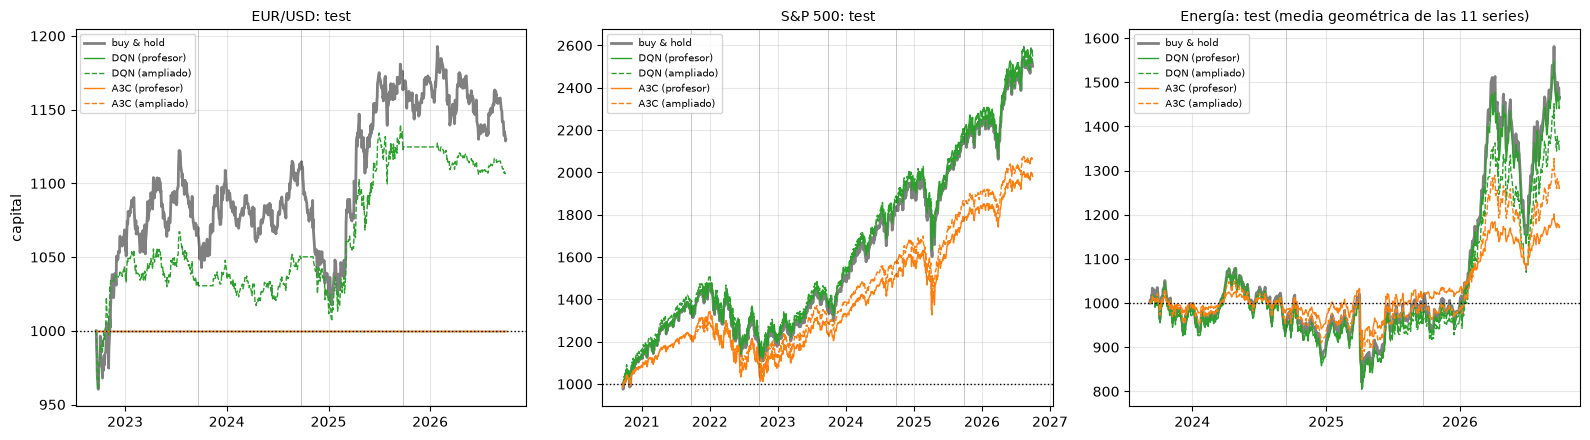

In [71]:
COLOR_ALG = {"DQN": "tab:green", "A3C": "tab:orange"}
ESTILO_VARIANTE = {"profesor": "-", "ampliado": "--"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, m in zip(axes, DATOS_REALES):
    fechas = DATOS_REALES[m].index[BLOQUES_TEST_REAL[m][0][0]: BLOQUES_TEST_REAL[m][-1][1] + 1]
    ax.plot(fechas, R.curva_capital(REF_TEST_REAL[(m, "Buy & hold")]), color="gray", linewidth=2, label="buy & hold")
    for alg in ALGORITMOS_REAL:
        for (m2, v, lr, g), res in TEST_REAL[alg].items():
            if m2 == m:
                ax.plot(fechas, R.curva_capital(res), color=COLOR_ALG[alg], linestyle=ESTILO_VARIANTE[v],
                        linewidth=1, label=f"{alg} ({v})")
    for inicio, fin in BLOQUES_TEST_REAL[m][1:]:
        ax.axvline(DATOS_REALES[m].index[inicio], color="black", linewidth=0.5, alpha=0.3)
    ax.axhline(1000, color="black", linestyle=":", linewidth=1)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_title(f"{m}: test" + (" (media geométrica de las 11 series)" if m == "Energía" else ""), fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
axes[0].set_ylabel("capital")
plt.tight_layout()
plt.show()

Las líneas verticales separan los bloques; en cada una el agente se ha reentrenado con todo lo anterior. Cada curva es la media geométrica de las 3 repeticiones (y de las 11 series en *Energía*).

#### Política aprendida con el estado del profesor

Con una sola variable, la política se lee como en las fases 1 y 3, para el agente de cada repetición entrenado para el último bloque de test. Arriba, DQN: ventaja de cambiar de posición ($> 0$: cambia). Abajo, A3C: probabilidad de comprar sin activo y de vender con activo ($> 0.5$: es la acción más probable salvo empate a tres). La rejilla cubre ±3 desviaciones de la tendencia de cada mercado.

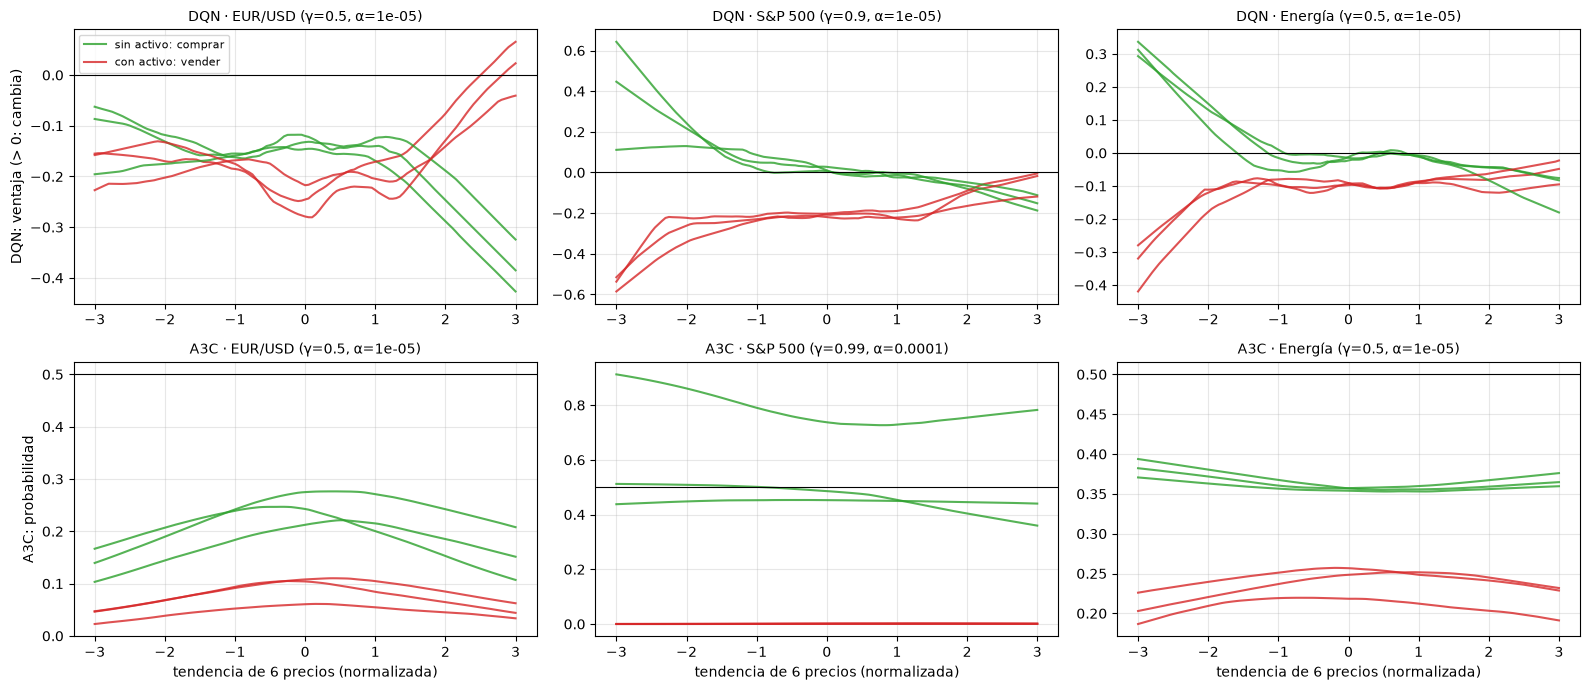

In [72]:
from dqn import ventajas_en_rejilla
from a3c import politica_en_rejilla

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for j, m in enumerate(DATOS_REALES):
    for i, (alg, funcion) in enumerate(ALGORITMOS_REAL.items()):
        ax = axes[i, j]
        e = ELEGIDAS_REAL[alg][(m, "profesor")]
        for rep in R.REPS:
            r = funcion("test", m, "profesor", e["lr"], e["gamma"], rep, BLOQUES_TEST_REAL[m][-1],
                        str(CARPETA_REALES))  # ya está en disco: solo se carga
            if alg == "DQN":
                red = R.red_desde_resultado({"pesos": r["pesos"], "config": {"n_ocultas": 64}, "n_entradas": 2})
                compra, venta = ventajas_en_rejilla(red)
            else:
                red = R.red_a3c_desde_resultado({"pesos": r["pesos"], "config": {"n_ocultas": 64}, "n_entradas": 2})
                compra, venta, _, _ = politica_en_rejilla(red)
            ax.plot(REJILLA_Z, compra, color="tab:green", alpha=0.8, label="sin activo: comprar" if rep == 0 else None)
            ax.plot(REJILLA_Z, venta, color="tab:red", alpha=0.8, label="con activo: vender" if rep == 0 else None)
        ax.axhline(0 if alg == "DQN" else 0.5, color="black", linewidth=0.8)
        ax.set_title(f"{alg} · {m} (γ={e['gamma']}, α={e['lr']:g})", fontsize=10)
        ax.grid(alpha=0.3)
    axes[1, j].set_xlabel("tendencia de 6 precios (normalizada)")
axes[0, 0].set_ylabel("DQN: ventaja (> 0: cambia)")
axes[1, 0].set_ylabel("A3C: probabilidad")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Resultado en test.**

**DQN**

- **S&P 500:** con el estado del profesor obtiene un 16.9% anual frente al 16.5% de *buy & hold*, invertido el 99% del tiempo y con 1.4 operaciones por bloque: el mismo Sharpe (0.95 frente a 0.93) y una caída máxima algo menor (23.8% frente a 24.6%). Igual que Sarsa (16.6–16.8%): **es *buy & hold***. El estado ampliado, 16.6% con 4.7 operaciones: lo mismo.
- ***Energía*:** 13.1% frente a 13.6% de *buy & hold* (Q-Learning y Sarsa, 12.4–13.4%). El estado ampliado opera más (9.9 operaciones por bloque, 90% invertido) y se queda en un 10.5%: sale en plena subida de 2026.
- **EUR/USD:** con el estado del profesor no opera, como la tabla. El estado ampliado gana un 2.6% anual frente al 3.1% de *buy & hold*, invertido la mitad del tiempo: Sharpe 0.46 frente a 0.42 y caída máxima del 6.2% frente al 9.3%. Es el único caso con algo distinto de *buy & hold* o de no operar, pero con 4 bloques y 0.8 puntos de desviación entre repeticiones no se distingue de la suerte; en validación perdía un 2.7% (*buy & hold*, −3.8%).
- **Política (estado del profesor):** en S&P 500 y *Energía* compra tras una caída (ventaja de compra > 0 con tendencia por debajo de ~−1 desviación) y no vende nunca: *buy & hold* con entrada en un retroceso. En EUR/USD la ventaja de compra es negativa en toda la rejilla: no entra nunca.

**A3C**

- **Claramente peor:** S&P 500, 12.1–12.8% frente al 16.5% de *buy & hold* (invertido el 78–83% del tiempo); *Energía*, 5.7–8.3% frente al 13.6% (invertido el 41–64%). La caída máxima es menor en *Energía* (22% frente a 30%) solo porque está menos tiempo dentro. En EUR/USD no opera.
- **Muy inestable entre repeticiones:** 3–8 puntos de desviación, frente a menos de 1 en el DQN.
- **Política casi plana:** la probabilidad de cada acción apenas cambia con la tendencia, y en *Energía* está cerca de la uniforme (p(comprar) ≈ 0.36). La acción voraz depende de diferencias mínimas, así que entra y sale sin criterio y cambia de una semilla a otra. En S&P 500 una de las tres semillas aprende a comprar siempre (p ≈ 0.8), y las otras dos no.
- **Por qué:** A3C aprende de la política actual (*on-policy*) y usa cada transición una sola vez, mientras que el DQN reutiliza cada una muchas veces desde la memoria. Con una señal tan débil, el gradiente de la política apenas tiene dirección y el término de entropía ($\beta$) la mantiene cerca de la uniforme. En los mercados sintéticos A3C ya necesitó 5 000 episodios para alcanzar al DQN; aquí, con 2 000 y unos 20 años de datos, no llega a converger.

**Conclusión de la fase 7**

1. **El DQN llega al nivel de la tabla, pero no supera ni a la tabla ni a *buy & hold*.** Con datos diarios y este estado, lo mejor que encuentra es quedarse dentro (S&P 500, *Energía*) o fuera (EUR/USD), como Q-Learning y Sarsa.
2. **A3C ni siquiera llega:** sin memoria de repeticiones aprovecha peor unos datos escasos y ruidosos. En este problema, reutilizar la experiencia pesa más que la exploración asíncrona.
3. **Más variables no ayudan: sobreajustan.** La ventaja de la red, aceptar muchas variables continuas sin discretizar, no sirve si las variables no predicen: con unos 20 años de entrenamiento la red encuentra patrones que no se repiten. Es lo que contó el profesor de su propio proyecto: con DQN *metieron demasiadas variables* y Q-Learning les fue mejor.
4. **El límite son los datos, no el modelo.** Para aprovechar la red haría falta información con poder predictivo real o muchos más datos (más activos, frecuencias más altas), y regularizar (red más pequeña, parada temprana).